# 🎬 Box-Office Intelligence
## A Statistical and Machine-Learning Analysis of ~10,000 Movies (TMDB)

---

## 1. Project Statement

**What I am doing.** I am building an end-to-end analytics project on the film industry. Using a TMDB extract of ~10,000 movies, I will move from raw, messy data through exploratory analysis, classical statistics, inferential testing, multiple-testing control, A/B-style experiments, and predictive / unsupervised machine learning, to produce **evidence-based answers to questions a studio, financier, or streaming-acquisition team would actually ask**.

**Why it matters.** A film is a high-variance capital investment. Most titles lose money, a few return many multiples, and the decisions made *before* release (budget, genre, release window, talent, studio backing) are the ones executives control. This project quantifies how much of the outcome those decisions explain, which "rules of thumb" survive statistical scrutiny, and where the uncertainty remains.

### Business questions
| # | Question | Primary methods |
|---|----------|-----------------|
| Q1 | What does the landscape look like, and how has it changed over time? | EDA, trend analysis |
| Q2 | How strongly does budget drive revenue, and is the relationship linear? | Correlation, log-log regression |
| Q3 | Do big-budget films carry more or less *relative* risk than small ones? | Variance tests, ROI distributions |
| Q4 | Do release timing, language, genre, and studio backing change outcomes? | t / Mann-Whitney, ANOVA / Kruskal, χ², OLS, logistic |
| Q5 | Which genres genuinely outperform once we correct for running dozens of tests? | Bonferroni, Holm, Benjamini-Hochberg, permutation max-T |
| Q6 | Is "release in summer" (or "major-studio backing") an *effect*, or just a proxy for bigger budgets? | A/B framework, power, Bayesian A/B, propensity matching |
| Q7 | Can we predict revenue and hit/flop **before release**, with honest uncertainty? | Ridge, Random Forest, XGBoost, quantile GBM, SHAP |
| Q8 | Are there natural "types" of movies, and which films beat expectations? | K-Means, GMM, PCA, residual analysis |

### Hypotheses (declared *before* looking at test results)
* **H1** Budget is the strongest single predictor of revenue (positive, sub-linear elasticity).
* **H2** ROI variability *decreases* with budget (small films are lottery tickets; tentpoles are less volatile in relative terms).
* **H3** Release window matters: summer and holiday windows outperform other windows.
* **H4** English-language films earn more than non-English films (larger addressable market).
* **H5** Genre matters (Animation/Adventure/Family on revenue; Horror on ROI), but fewer genres survive multiple-testing correction than naive p-values suggest.
* **H6** Audience rating correlates positively with revenue, but weakly relative to budget.
* **H7** Major-studio involvement raises hit probability *even after matching on budget and other covariates*.
* **H8** International co-productions are rated higher than single-country productions.

### Data
`tmbddataset.csv` – one row per movie. Core fields: `id, title, budget, revenue, genres, runtime, release_date, production_companies, production_countries, cast`. The file also contains **`director, vote_average, vote_count, popularity, original_language`**, which I use for talent features, audience-reception analysis, and clustering.

### Definitions used throughout
* **ROI** = revenue / budget. **Hit** = revenue ≥ 2 × budget (the industry "2× rule", since studios keep only ~50% of box office and must also cover marketing).
* **Pre-release features** = information known before opening day (budget, runtime, genre, month, countries, studio, talent track record). **Post-release signals** (vote_count, popularity, vote_average) are used for description and clustering but are *kept out of predictive models* to avoid target leakage (demonstrated explicitly in §9).

### Success criteria
1. A documented, reproducible cleaning pipeline with every exclusion quantified.
2. Every statistical claim reported with an effect size and a confidence interval, not just a p-value.
3. Predictive models judged on a **temporal hold-out** (train on the past, test on the future) against a naive baseline.
4. Explicit statement of assumptions, biases, and limitations.

### Roadmap
`2 Setup → 3 Cleaning → 4 Feature engineering → 5 EDA → 6 Descriptive statistics → 7 Inferential statistics → 8 Multiple testing → 9 A/B testing → 10 Machine learning → 11 Clustering → 12 Over/under-performers → 13 Conclusions`

## 2. Setup

In [1]:
import warnings, ast, re, math, itertools, platform
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.power import TTestIndPower, NormalIndPower
from statsmodels.stats.proportion import (proportion_confint, proportions_ztest,
                                          proportion_effectsize, confint_proportions_2indep)
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd

warnings.filterwarnings('ignore')
SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)

sns.set_theme(style='whitegrid', context='notebook', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'axes.titleweight': 'bold',
                     'axes.titlesize': 12, 'axes.labelsize': 10, 'figure.autolayout': False})
pd.set_option('display.max_columns', 60, 'display.width', 200, 'display.float_format', '{:,.3f}'.format)

FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)
def savefig(name):
    plt.savefig(FIG_DIR / f'{name}.png', bbox_inches='tight')

def money(x, pos=None):
    if abs(x) >= 1e9: return f'${x/1e9:.1f}B'
    if abs(x) >= 1e6: return f'${x/1e6:.0f}M'
    if abs(x) >= 1e3: return f'${x/1e3:.0f}K'
    return f'${x:.0f}'
MONEY = mtick.FuncFormatter(money)

print('Python', platform.python_version(), '| pandas', pd.__version__, '| numpy', np.__version__)

C:\Users\Lehma\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Python 3.11.5 | pandas 2.3.3 | numpy 1.26.4


## 3. Data Loading, Audit and Cleaning
I start with an audit *before* touching anything, so every later exclusion can be justified and quantified.

In [2]:
CANDIDATES = [Path('tmbddataset.csv'), Path('data/tmbddataset.csv'), Path('/mnt/user-data/uploads/tmbddataset.csv')]
DATA_PATH = next(p for p in CANDIDATES if p.exists())
raw = pd.read_csv(DATA_PATH)
print(f'Loaded {DATA_PATH}  ->  {raw.shape[0]:,} rows x {raw.shape[1]} columns')

audit = pd.DataFrame({
    'dtype': raw.dtypes.astype(str),
    'missing': raw.isna().sum(),
    'zeros': (raw.select_dtypes('number') == 0).sum().reindex(raw.columns),
    'n_unique': raw.nunique(),
})
audit['pct_missing'] = 100 * audit.missing / len(raw)
audit['pct_zero'] = 100 * audit.zeros / len(raw)
audit

Loaded tmbddataset.csv  ->  9,999 rows x 15 columns


,dtype,missing,zeros,n_unique,pct_missing,pct_zero
id,int64,0,0.000,9767,0.000,0.000
title,object,0,NaN,9426,0.000,NaN
budget,int64,0,"4,774.000",704,0.000,47.745
revenue,int64,0,"4,432.000",5057,0.000,44.324
genres,object,0,NaN,2211,0.000,NaN
runtime,int64,0,178.000,223,0.000,1.780
release_date,object,22,NaN,6102,0.220,NaN
production_companies,object,0,NaN,7894,0.000,NaN
production_countries,object,0,NaN,856,0.000,NaN
cast,object,0,NaN,9606,0.000,NaN


**Audit findings that drive the cleaning plan**

* **Exact duplicate rows** exist (the same movie repeated).
* `budget` and `revenue` are **0 for roughly half the films**. In TMDB, 0 means *unknown*, not "free" or "no sales", so these must become missing values. Treating them as real zeros would wreck every mean, ratio, and log.
* `release_date` mixes two formats (`m/d/yyyy` and ISO `yyyy-mm-dd`) and includes dates in the future.
* `runtime` has zeros and absurd values (e.g. 999 min). A handful of budgets/revenues are implausibly tiny ($1, $5, $120), which are data-entry artefacts.
* List-like columns are stored as strings and need parsing.

In [3]:
cleaning_log = []
def log_step(step, before, after, note=''):
    cleaning_log.append({'step': step, 'rows_before': before, 'rows_after': after, 'rows_removed': before - after, 'note': note})

df = raw.copy()

# 1. exact duplicates
n = len(df); df = df.drop_duplicates().reset_index(drop=True)
log_step('Drop exact duplicate rows', n, len(df), 'same movie repeated')

# 2. parse list-like text columns
def parse_list(s):
    try:
        v = ast.literal_eval(s)
        return v if isinstance(v, list) else []
    except Exception:
        return []
for c in ['genres', 'production_companies', 'production_countries', 'cast']:
    df[c] = df[c].apply(parse_list)

# 3. dates: two formats present
df['release_date'] = pd.to_datetime(df['release_date'], format='mixed', errors='coerce')
n = len(df); df = df[df.release_date.notna()]
log_step('Drop rows with unparseable / missing release_date', n, len(df), 'cannot place in time')

CUTOFF = pd.Timestamp('2025-12-31')
n = len(df); df = df[df.release_date <= CUTOFF]
log_step('Drop future-dated (unreleased) titles', n, len(df), f'release_date > {CUTOFF.date()}')
df = df.reset_index(drop=True)

# 4. values that are really "unknown"
df['budget_raw'], df['revenue_raw'] = df.budget, df.revenue
MIN_MONEY = 10_000
df['budget']  = df.budget.where(df.budget  >= MIN_MONEY)    # 0 and <$10k -> NaN
df['revenue'] = df.revenue.where(df.revenue >= MIN_MONEY)
df['runtime'] = df.runtime.where(df.runtime.between(40, 300))  # drop 0-min and >5h entries
df['vote_average'] = df.vote_average.where(df.vote_count > 0)   # a 0.0 rating with 0 votes means "unrated"

print(f"budget unknown : {df.budget.isna().mean():.1%}")
print(f"revenue unknown: {df.revenue.isna().mean():.1%}")
print(f"runtime unknown: {df.runtime.isna().mean():.1%}")
print(f"unrated        : {df.vote_average.isna().mean():.1%}")
pd.DataFrame(cleaning_log)

budget unknown : 47.7%
revenue unknown: 44.3%
runtime unknown: 3.2%
unrated        : 2.6%


,step,rows_before,rows_after,rows_removed,note
0,Drop exact duplicate rows,9999,9767,232,same movie repeated
1,Drop rows with unparseable / missing release_date,9767,9746,21,cannot place in time
2,Drop future-dated (unreleased) titles,9746,9733,13,release_date > 2025-12-31


### 3.1 Is the "known budget & revenue" subset representative?
Roughly half the films lack financials. If those films differ systematically from the rest, conclusions drawn on the financial subset are **selection-biased**. I check this rather than assume it away.

In [4]:
df['has_fin'] = df.budget.notna() & df.revenue.notna()
df['year'] = df.release_date.dt.year
comp = df.groupby('has_fin').agg(
    n=('id', 'size'),
    median_year=('year', 'median'),
    median_runtime=('runtime', 'median'),
    median_vote_count=('vote_count', 'median'),
    median_popularity=('popularity', 'median'),
    pct_english=('original_language', lambda s: (s == 'en').mean() * 100),
    pct_us=('production_countries', lambda s: s.apply(lambda l: 'United States of America' in l).mean() * 100),
)
print(comp.round(1))
u, p = stats.mannwhitneyu(df.loc[df.has_fin, 'vote_count'], df.loc[~df.has_fin, 'vote_count'])
print(f"\nvote_count, with vs without financials: Mann-Whitney p = {p:.2e}")
print("-> Films with financials are more visible, more English/US, and more heavily voted. "
      "Findings describe *films with disclosed financials*, which skews toward commercially released titles.")

            n  median_year  median_runtime  median_vote_count  median_popularity  pct_english  pct_us
has_fin                                                                                              
False    5151    2,016.000          95.000             71.000              2.500       54.400  43.500
True     4582    2,009.000         108.000          1,943.500              3.700       89.200  85.200

vote_count, with vs without financials: Mann-Whitney p = 0.00e+00
-> Films with financials are more visible, more English/US, and more heavily voted. Findings describe *films with disclosed financials*, which skews toward commercially released titles.


## 4. Feature Engineering
Features are grouped into (a) money & return metrics, (b) time & release window, (c) content, (d) production footprint, and (e) **talent track record built without look-ahead** (a director's prior average revenue uses only films released *before* the current one, so there is no leakage from the film's own outcome).

In [5]:
# ---------- time / release window ----------
df['month'] = df.release_date.dt.month
df['decade'] = (df.year // 10 * 10).astype(int)
def season(m):
    return ('Winter (Jan-Feb)' if m in (1, 2) else 'Spring (Mar-Apr)' if m in (3, 4) else
            'Summer (May-Aug)' if m in (5, 6, 7, 8) else 'Fall (Sep-Oct)' if m in (9, 10) else 'Holiday (Nov-Dec)')
df['season'] = df.month.apply(season)
df['is_summer'] = (df.season == 'Summer (May-Aug)').astype(int)
df['month_sin'] = np.sin(2 * np.pi * df.month / 12)
df['month_cos'] = np.cos(2 * np.pi * df.month / 12)

# ---------- money & return ----------
df['log_budget'] = np.log(df.budget)
df['log_revenue'] = np.log(df.revenue)
df['roi'] = df.revenue / df.budget
df['log_roi'] = np.log(df.roi)
df['profit'] = df.revenue - df.budget
df['hit'] = np.where(df.has_fin, (df.revenue >= 2 * df.budget).astype(float), np.nan)
df['budget_tier'] = pd.cut(df.budget, [0, 1e6, 1e7, 5e7, 1.5e8, np.inf],
                           labels=['Micro (<$1M)', 'Low ($1-10M)', 'Mid ($10-50M)', 'High ($50-150M)', 'Blockbuster (>$150M)'])
df['log_vote_count'] = np.log1p(df.vote_count)
df['log_popularity'] = np.log1p(df.popularity)

# ---------- content ----------
df['n_genres'] = df.genres.apply(len)
GENRES = df.genres.explode().value_counts().index.tolist()
safe = lambda g: 'g_' + re.sub(r'\W+', '_', g)
GENRE_COLS = {g: safe(g) for g in GENRES}
for g, c in GENRE_COLS.items():
    df[c] = df.genres.apply(lambda l: int(g in l))

# ---------- production footprint ----------
df['n_countries'] = df.production_countries.apply(len)
df['n_companies'] = df.production_companies.apply(len)
df['is_us'] = df.production_countries.apply(lambda l: int('United States of America' in l))
df['is_coproduction'] = (df.n_countries >= 2).astype(int)
df['is_english'] = (df.original_language == 'en').astype(int)
MAJORS = ['Warner Bros', 'Universal Pictures', 'Paramount', 'Walt Disney', 'Pixar', 'Marvel', 'Lucasfilm', '20th Century',
          'Twentieth Century', 'Columbia Pictures', 'Sony Pictures', 'TriStar', 'Metro-Goldwyn-Mayer', 'New Line Cinema',
          'Lionsgate', 'DreamWorks', 'Legendary', 'Amblin', 'Touchstone', 'Focus Features', 'Miramax']
STREAMERS = ['Netflix', 'Amazon', 'Apple Original', 'Apple Studios', 'Apple TV']   # streaming originals: tiny theatrical revenue vs large budgets
major_re = '|'.join(map(re.escape, MAJORS)); stream_re = '|'.join(map(re.escape, STREAMERS))
df['has_major'] = df.production_companies.apply(lambda l: int(bool(re.search(major_re, ' | '.join(l)))))
df['is_streamer'] = df.production_companies.apply(lambda l: int(bool(re.search(stream_re, ' | '.join(l)))))
top_langs = df.original_language.value_counts().head(8).index
df['lang_group'] = df.original_language.where(df.original_language.isin(top_langs), 'other')

# ---------- talent track record (NO look-ahead) ----------
df = df.sort_values(['release_date', 'id']).reset_index(drop=True)
df['director'] = df.director.fillna('Unknown')
df['lead'] = df.cast.str[0]
def track_record(key):
    g = df.groupby(key, sort=False)
    prior_n = g.cumcount()                                  # earlier films by same person in the dataset
    prior_mean = g['log_revenue'].transform(lambda s: s.shift(1).expanding().mean())   # their earlier avg log-revenue
    bad = df[key].isna() | (df[key] == 'Unknown')
    return prior_n.where(~bad, 0), prior_mean.where(~bad)
df['dir_prior_films'], df['dir_prior_mean_logrev'] = track_record('director')
df['lead_prior_films'], df['lead_prior_mean_logrev'] = track_record('lead')

# ---------- analysis samples ----------
fin = df[df.has_fin].copy()                                 # known budget AND revenue
rated = df[(df.vote_count >= 50) & df.vote_average.notna()].copy()   # enough votes for a stable rating
print(f'Full cleaned universe : {len(df):,} films')
print(f'Financial sample (fin): {len(fin):,} films   <- used for revenue / ROI / hit analyses')
print(f'Rated sample (rated)  : {len(rated):,} films   <- used for rating analyses (>=50 votes)')
print(f"Streaming-studio films in fin sample: {fin.is_streamer.sum()} (theatrical revenue understates their reach; treated as a control)")
print(f"Hit rate in fin sample: {fin.hit.mean():.1%}   |   median ROI: {fin.roi.median():.2f}x   |   mean ROI: {fin.roi.mean():.2f}x")
fin[['title', 'year', 'budget', 'revenue', 'roi', 'hit', 'season', 'has_major', 'dir_prior_films', 'dir_prior_mean_logrev']].head()

Full cleaned universe : 9,733 films
Financial sample (fin): 4,582 films   <- used for revenue / ROI / hit analyses
Rated sample (rated)  : 7,320 films   <- used for rating analyses (>=50 votes)
Streaming-studio films in fin sample: 12 (theatrical revenue understates their reach; treated as a control)
Hit rate in fin sample: 59.9%   |   median ROI: 2.56x   |   mean ROI: 7.19x


,title,year,budget,revenue,roi,hit,season,has_major,dir_prior_films,dir_prior_mean_logrev
4,The Birth of a Nation,1915,"100,000.000","11,000,000.000",110.000,1.000,Winter (Jan-Feb),0,0,NaN
5,Intolerance: Love's Struggle Throughout the Ages,1916,"385,907.000","1,750,000.000",4.535,1.000,Fall (Sep-Oct),0,1,16.213
9,The Kid,1921,"250,000.000","2,500,000.000",10.000,1.000,Winter (Jan-Feb),0,0,NaN
13,Safety Last!,1923,"121,000.000","1,500,000.000",12.397,1.000,Spring (Mar-Apr),0,0,NaN
17,The Gold Rush,1925,"923,000.000","4,000,000.000",4.334,1.000,Summer (May-Aug),0,1,14.732


## 5. Exploratory Data Analysis (EDA)

### 5.1 Data completeness

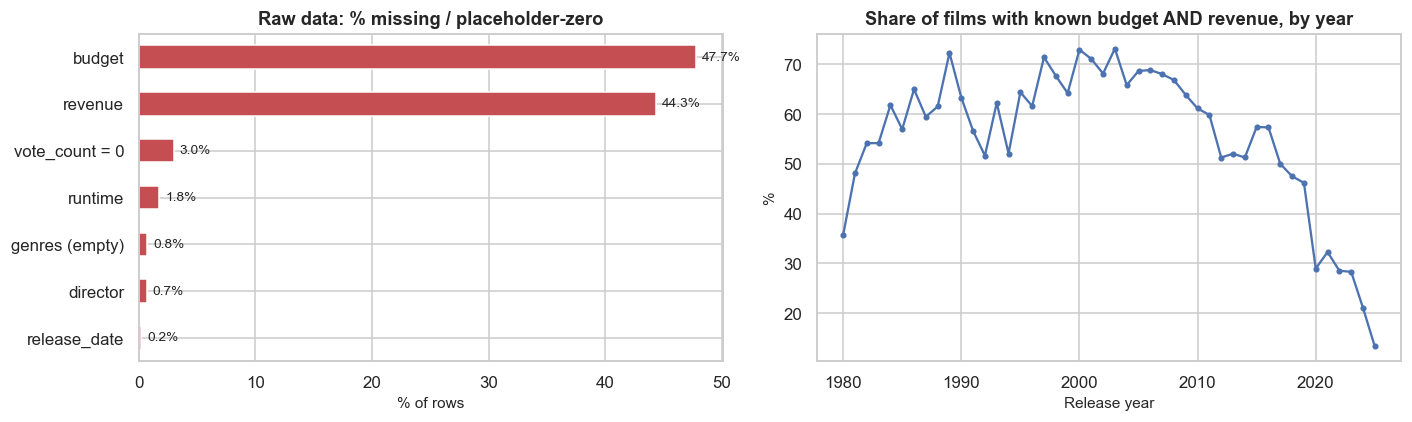

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
miss = pd.Series({
    'budget': raw.budget.eq(0).mean(), 'revenue': raw.revenue.eq(0).mean(), 'runtime': raw.runtime.eq(0).mean(),
    'director': raw.director.isna().mean(), 'release_date': raw.release_date.isna().mean(),
    'genres (empty)': (raw.genres == '[]').mean(), 'vote_count = 0': raw.vote_count.eq(0).mean()}).sort_values()
(miss * 100).plot.barh(ax=ax[0], color=sns.color_palette('deep')[3])
ax[0].set_title('Raw data: % missing / placeholder-zero'); ax[0].set_xlabel('% of rows')
for i, v in enumerate(miss * 100): ax[0].text(v + .5, i, f'{v:.1f}%', va='center', fontsize=9)

yr = df.groupby('year').has_fin.mean().loc[1980:]
ax[1].plot(yr.index, yr * 100, marker='o', ms=3)
ax[1].set_title('Share of films with known budget AND revenue, by year'); ax[1].set_ylabel('%'); ax[1].set_xlabel('Release year')
plt.tight_layout()
plt.show()

### 5.2 Univariate distributions - raw vs log scale
Money variables are extremely right-skewed (a few mega-blockbusters), so raw-scale means are misleading and parametric tests on raw values are unreliable. The log scale is close to symmetric, which motivates modelling **log-revenue** and **log-ROI** later.

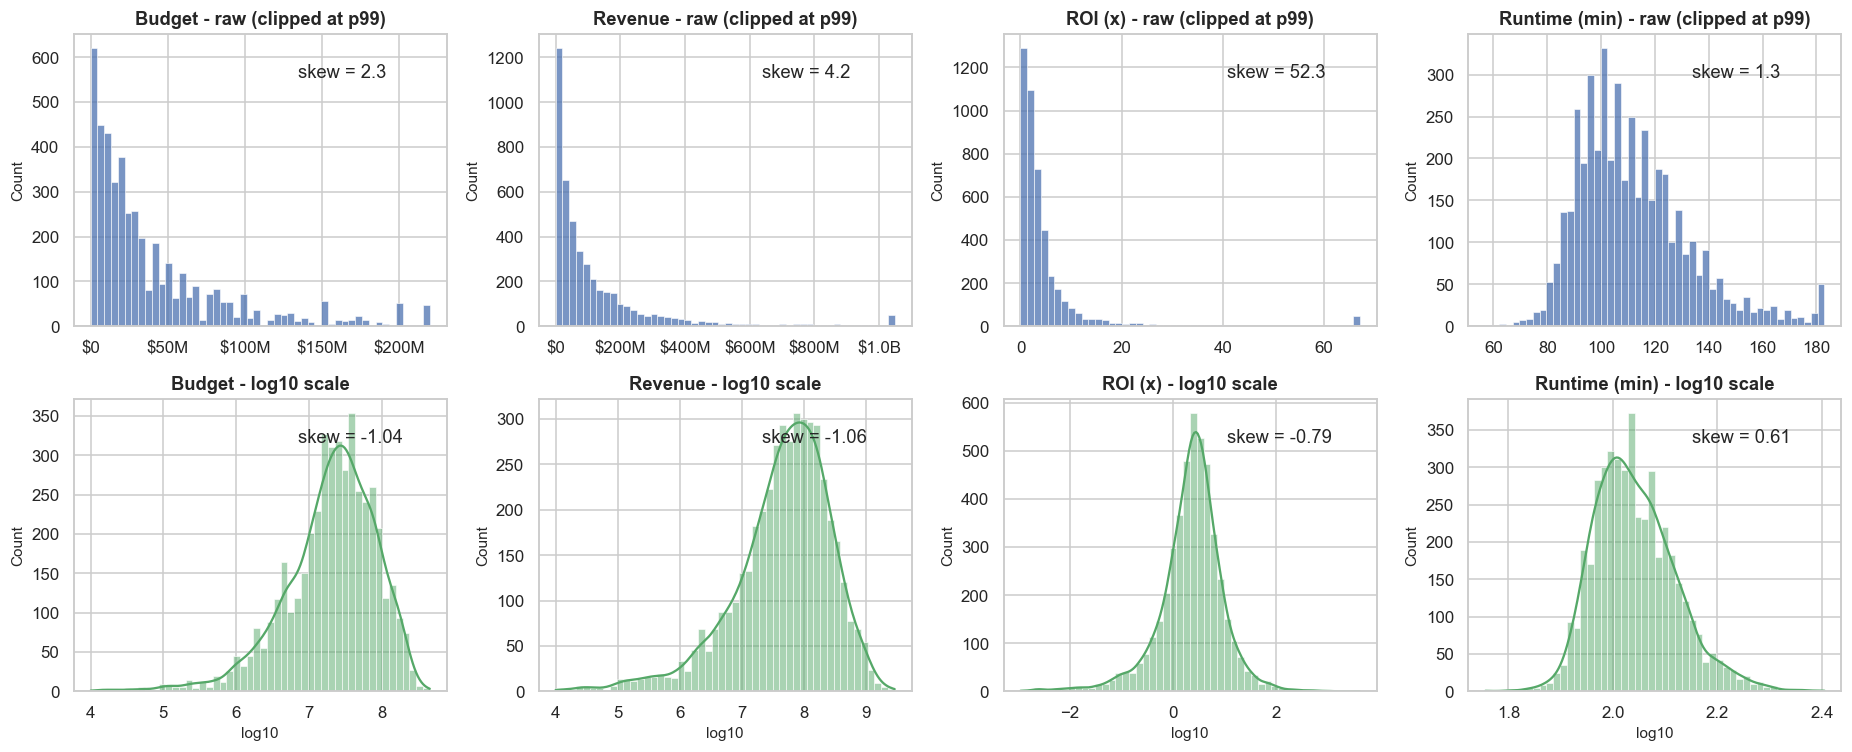

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
spec = [('budget', 'Budget'), ('revenue', 'Revenue'), ('roi', 'ROI (x)'), ('runtime', 'Runtime (min)')]
for j, (c, t) in enumerate(spec):
    x = fin[c].dropna()
    sns.histplot(x.clip(upper=x.quantile(.99)), bins=50, ax=axes[0, j], color='#4C72B0')
    axes[0, j].set_title(f'{t} - raw (clipped at p99)'); axes[0, j].set_xlabel('')
    if c in ('budget', 'revenue'): axes[0, j].xaxis.set_major_formatter(MONEY)
    sns.histplot(np.log10(x), bins=50, ax=axes[1, j], color='#55A868', kde=True)
    axes[1, j].set_title(f'{t} - log10 scale'); axes[1, j].set_xlabel('log10')
    axes[0, j].annotate(f'skew = {stats.skew(x):.1f}', (.6, .85), xycoords='axes fraction')
    axes[1, j].annotate(f'skew = {stats.skew(np.log10(x)):.2f}', (.6, .85), xycoords='axes fraction')
plt.tight_layout()
plt.show()

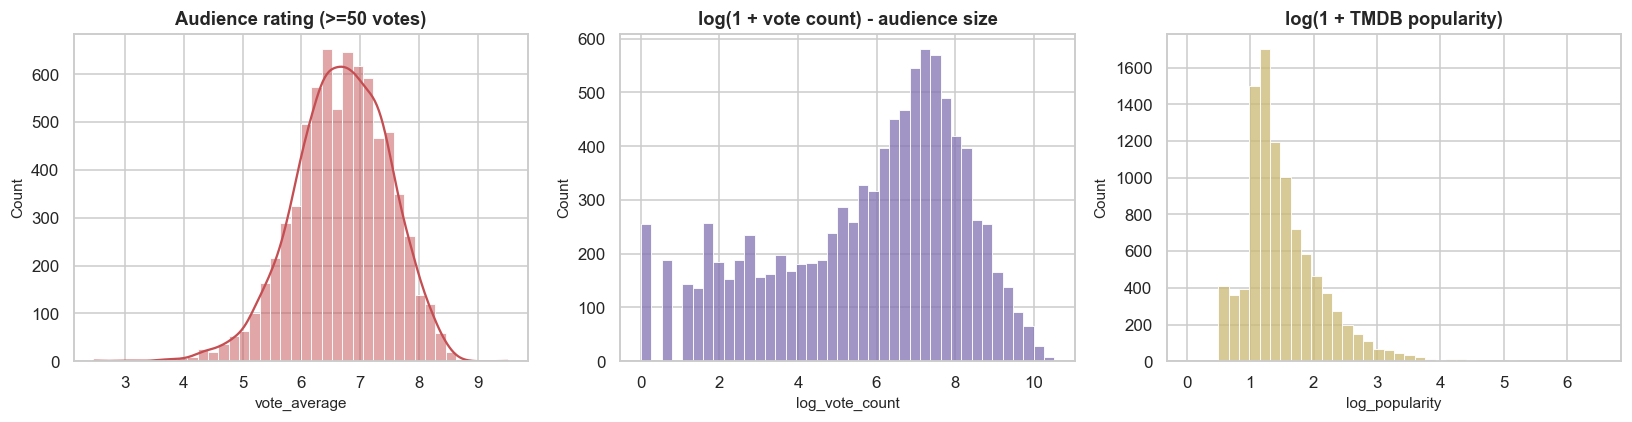

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(rated.vote_average, bins=40, ax=axes[0], color='#C44E52', kde=True); axes[0].set_title('Audience rating (>=50 votes)')
sns.histplot(df.log_vote_count.dropna(), bins=40, ax=axes[1], color='#8172B2'); axes[1].set_title('log(1 + vote count) - audience size')
sns.histplot(df.log_popularity.dropna(), bins=40, ax=axes[2], color='#CCB974'); axes[2].set_title('log(1 + TMDB popularity)')
plt.tight_layout()
plt.show()

### 5.3 The industry over time
Volume exploded after 2000 and especially 2022-2024 (TMDB coverage and streaming). Revenue and budget are **nominal** dollars (no inflation adjustment is available in the data), so I interpret raw long-run dollar growth cautiously and control for `year` in models.

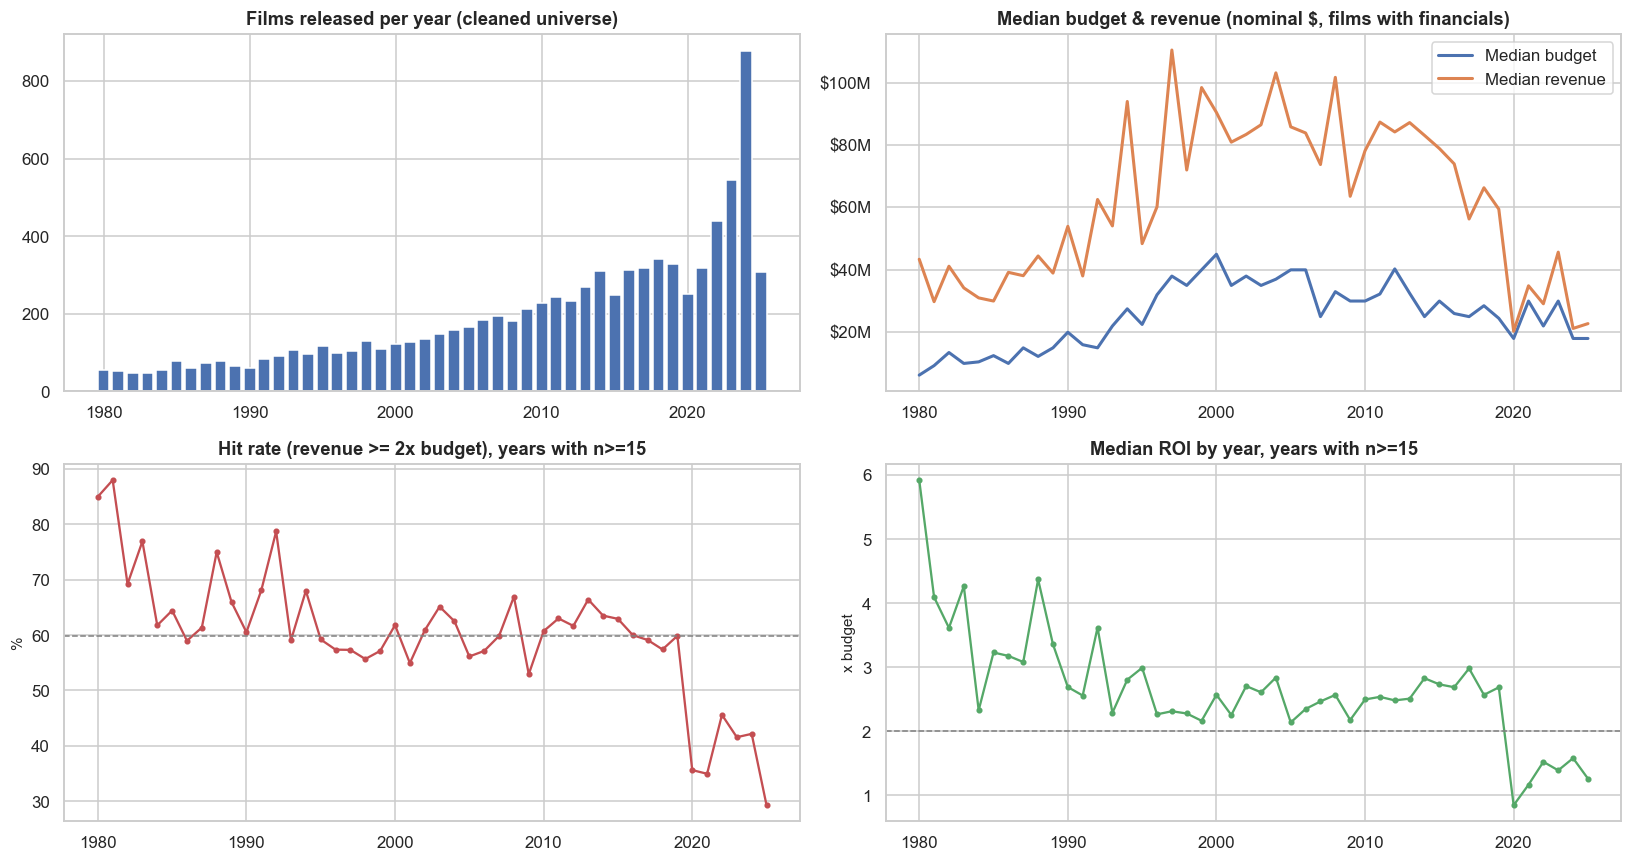

In [9]:
yearly = df[df.year >= 1980].groupby('year').agg(n_films=('id', 'size'))
fy = fin[fin.year >= 1980].groupby('year').agg(med_budget=('budget', 'median'), med_revenue=('revenue', 'median'),
                                               hit_rate=('hit', 'mean'), med_roi=('roi', 'median'), n=('id', 'size'))
fig, ax = plt.subplots(2, 2, figsize=(15, 8))
ax[0, 0].bar(yearly.index, yearly.n_films, color='#4C72B0'); ax[0, 0].set_title('Films released per year (cleaned universe)')
ax[0, 1].plot(fy.index, fy.med_budget, label='Median budget', lw=2); ax[0, 1].plot(fy.index, fy.med_revenue, label='Median revenue', lw=2)
ax[0, 1].yaxis.set_major_formatter(MONEY); ax[0, 1].legend(); ax[0, 1].set_title('Median budget & revenue (nominal $, films with financials)')
fy_s = fy[fy.n >= 15]
ax[1, 0].plot(fy_s.index, fy_s.hit_rate * 100, color='#C44E52', marker='o', ms=3); ax[1, 0].set_title('Hit rate (revenue >= 2x budget), years with n>=15')
ax[1, 0].set_ylabel('%'); ax[1, 0].axhline(fin.hit.mean() * 100, ls='--', c='gray', lw=1)
ax[1, 1].plot(fy_s.index, fy_s.med_roi, color='#55A868', marker='o', ms=3); ax[1, 1].set_title('Median ROI by year, years with n>=15')
ax[1, 1].axhline(2, ls='--', c='gray', lw=1); ax[1, 1].set_ylabel('x budget')
plt.tight_layout(); savefig('04_time_trends'); plt.show()

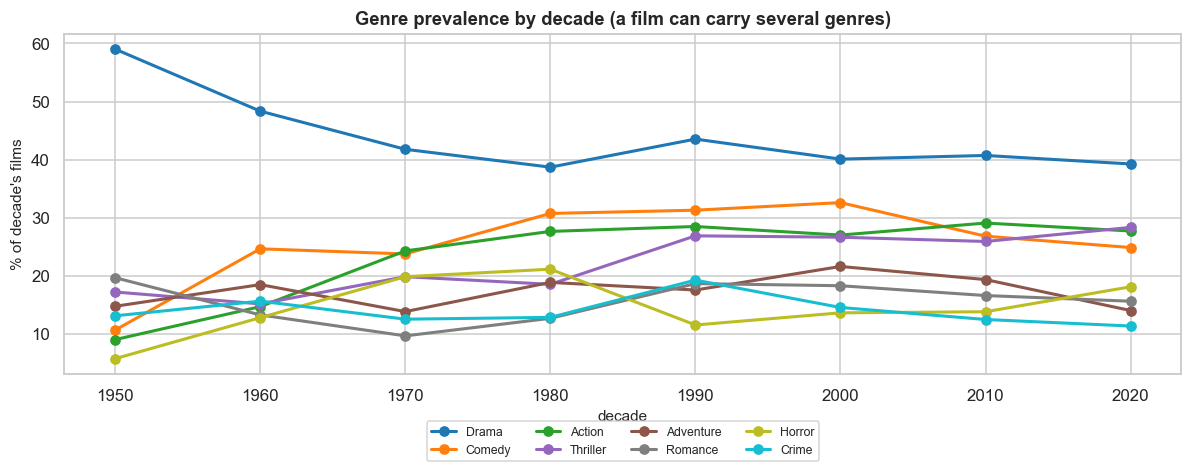

In [10]:
# Genre mix by decade (share of that decade's films carrying each genre)
top8 = GENRES[:8]
dec = df[df.decade >= 1950]
mix = pd.DataFrame({g: dec.groupby('decade')[GENRE_COLS[g]].mean() * 100 for g in top8})
fig, ax = plt.subplots(figsize=(11, 4.5))
mix.plot(ax=ax, marker='o', lw=2, colormap='tab10'); ax.set_ylabel('% of decade\'s films'); ax.set_title('Genre prevalence by decade (a film can carry several genres)')
ax.legend(ncol=4, fontsize=8, loc='upper center', bbox_to_anchor=(.5, -.12))
plt.tight_layout(); savefig('05_genre_by_decade'); plt.show()

### 5.4 Budget vs revenue
The log-log scatter shows an almost linear band: revenue scales roughly proportionally with budget, but with huge scatter. Break-even and hit lines make the risk visible - plenty of big-budget films sit below the 1x line.

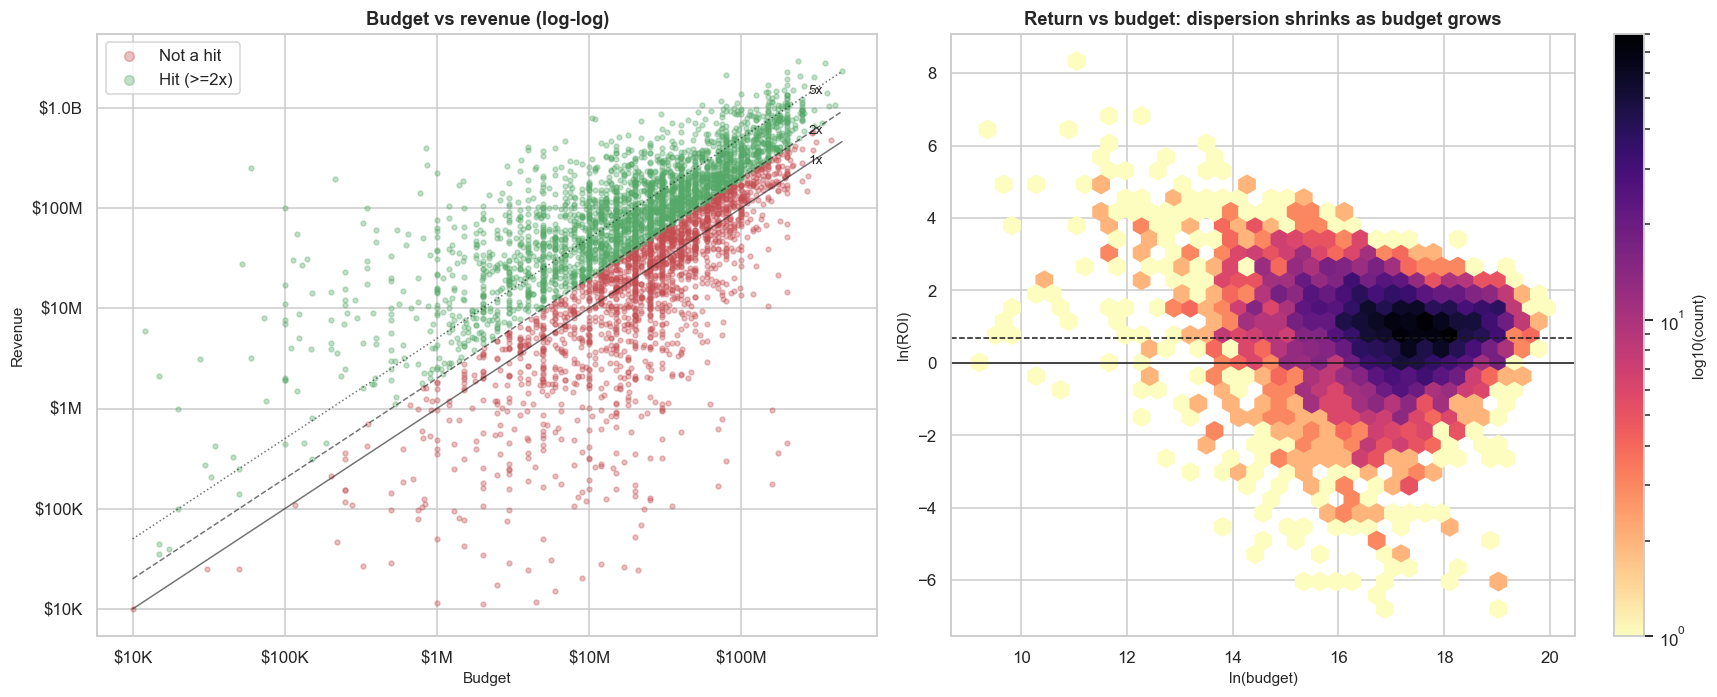

                         n  median_roi  mean_roi  hit_rate  loss_rate  p10_roi  p90_roi
budget_tier                                                                            
Micro (<$1M)           183      10.140    74.780     0.750      0.160    0.480  115.090
Low ($1-10M)          1082       3.560     7.660     0.660      0.200    0.340   18.270
Mid ($10-50M)         2124       2.280     3.510     0.550      0.250    0.400    7.510
High ($50-150M)        982       2.290     2.890     0.580      0.160    0.710    5.720
Blockbuster (>$150M)   211       2.790     3.210     0.670      0.100    1.010    6.080


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
colors = {1.0: '#55A868', 0.0: '#C44E52'}
for h, d in fin.groupby('hit'):
    ax[0].scatter(d.budget, d.revenue, s=10, alpha=.35, c=colors[h], label='Hit (>=2x)' if h else 'Not a hit')
ax[0].set_xscale('log'); ax[0].set_yscale('log')
xs = np.array([fin.budget.min(), fin.budget.max()])
for k, ls in [(1, '-'), (2, '--'), (5, ':')]:
    ax[0].plot(xs, xs * k, c='k', lw=1, ls=ls, alpha=.6); ax[0].text(xs[1] * .6, xs[1] * k * .6, f'{k}x', fontsize=9)
ax[0].xaxis.set_major_formatter(MONEY); ax[0].yaxis.set_major_formatter(MONEY)
ax[0].set_xlabel('Budget'); ax[0].set_ylabel('Revenue'); ax[0].legend(markerscale=2); ax[0].set_title('Budget vs revenue (log-log)')
hb = ax[1].hexbin(fin.log_budget, fin.log_roi, gridsize=35, cmap='magma_r', mincnt=1, bins='log')
ax[1].axhline(0, c='k', lw=1); ax[1].axhline(np.log(2), c='k', lw=1, ls='--')
ax[1].set_xlabel('ln(budget)'); ax[1].set_ylabel('ln(ROI)'); ax[1].set_title('Return vs budget: dispersion shrinks as budget grows')
plt.colorbar(hb, ax=ax[1], label='log10(count)')
plt.tight_layout()
plt.show()

print(fin.groupby('budget_tier', observed=True).agg(n=('id', 'size'), median_roi=('roi', 'median'), mean_roi=('roi', 'mean'),
      hit_rate=('hit', 'mean'), loss_rate=('roi', lambda s: (s < 1).mean()), p10_roi=('roi', lambda s: s.quantile(.1)),
      p90_roi=('roi', lambda s: s.quantile(.9))).round(2))

### 5.5 Genre economics
`explode` turns each film into one row per genre it carries, so multi-genre films count toward every genre they belong to.

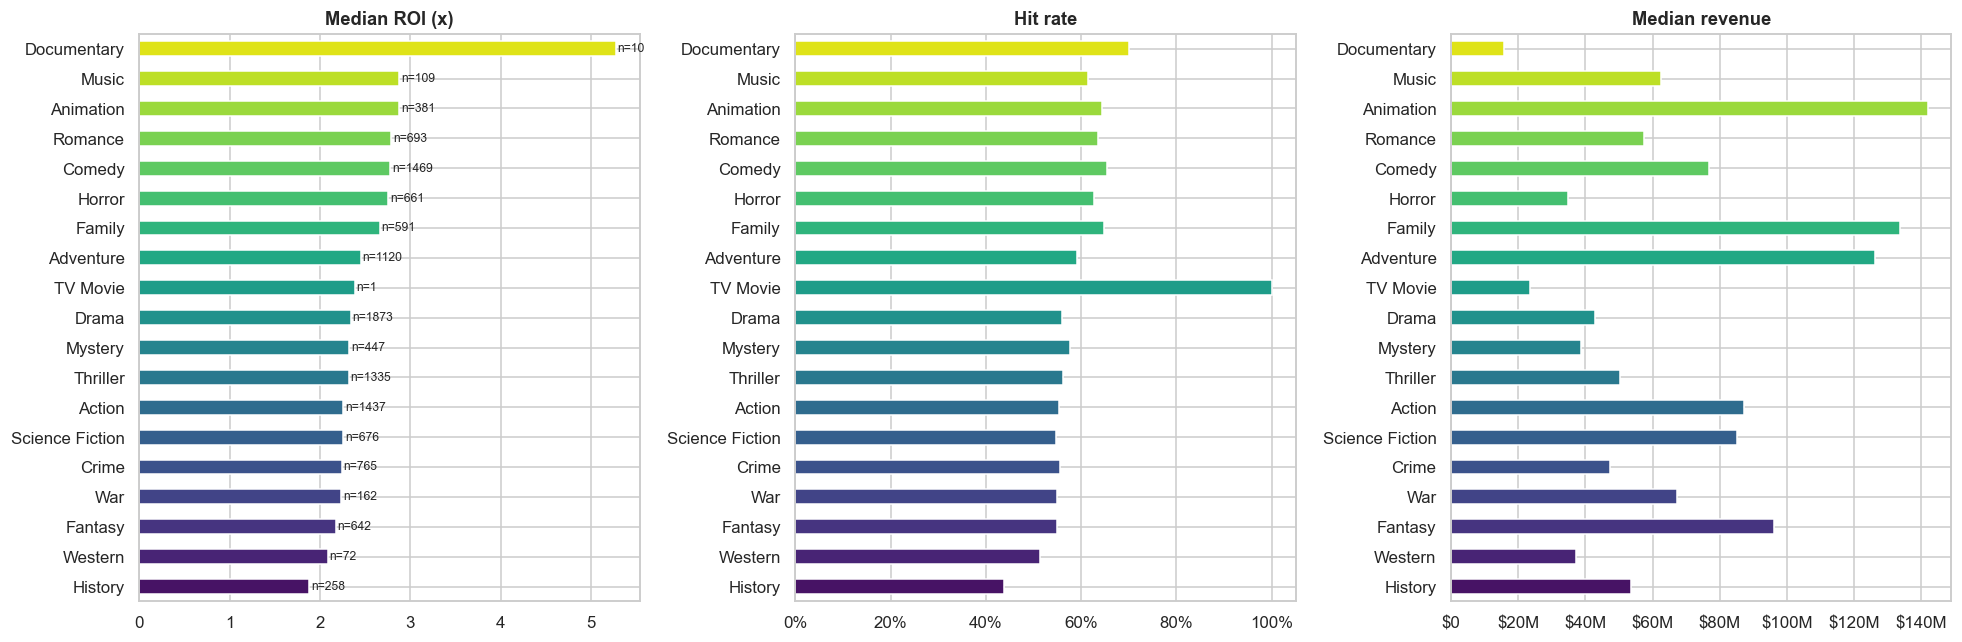

,n,median_budget,median_revenue,median_roi,hit_rate,loss_rate,median_rating
genres,,,,,,,
Documentary,10,"3,750,000.000","15,735,761.000",5.280,0.700,0.200,6.720
Music,109,"26,000,000.000","62,646,763.000",2.880,0.610,0.220,6.930
Animation,381,"60,000,000.000","141,940,042.000",2.880,0.640,0.180,7.000
Romance,693,"20,000,000.000","57,600,000.000",2.790,0.640,0.170,6.860
Comedy,1469,"26,000,000.000","76,700,000.000",2.780,0.650,0.160,6.600
Horror,661,"10,000,000.000","34,861,127.000",2.760,0.630,0.210,6.330
Family,591,"55,000,000.000","133,800,000.000",2.660,0.650,0.150,6.770
Adventure,1120,"60,000,000.000","126,191,986.000",2.450,0.590,0.190,6.640
TV Movie,1,"9,900,000.000","23,600,000.000",2.380,1.000,0.000,6.500


In [12]:
ge = fin.explode('genres').reset_index(drop=True)
gs = ge.groupby('genres').agg(n=('id', 'size'), median_budget=('budget', 'median'), median_revenue=('revenue', 'median'),
        median_roi=('roi', 'median'), hit_rate=('hit', 'mean'), loss_rate=('roi', lambda s: (s < 1).mean()),
        median_rating=('vote_average', 'median')).sort_values('median_roi', ascending=False)
fig, ax = plt.subplots(1, 3, figsize=(18, 6), sharey=False)
order = gs.sort_values('median_roi').index
for a, col, ttl, fmt in [(ax[0], 'median_roi', 'Median ROI (x)', None), (ax[1], 'hit_rate', 'Hit rate', 'pct'), (ax[2], 'median_revenue', 'Median revenue', 'money')]:
    gs.loc[order, col].plot.barh(ax=a, color=sns.color_palette('viridis', len(order)))
    a.set_title(ttl); a.set_ylabel('')
    if fmt == 'pct': a.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    if fmt == 'money': a.xaxis.set_major_formatter(MONEY)
for i, g in enumerate(order): ax[0].text(gs.loc[g, 'median_roi'] + .02, i, f"n={gs.loc[g,'n']}", va='center', fontsize=8)
plt.tight_layout()
plt.show()
gs.round(2)

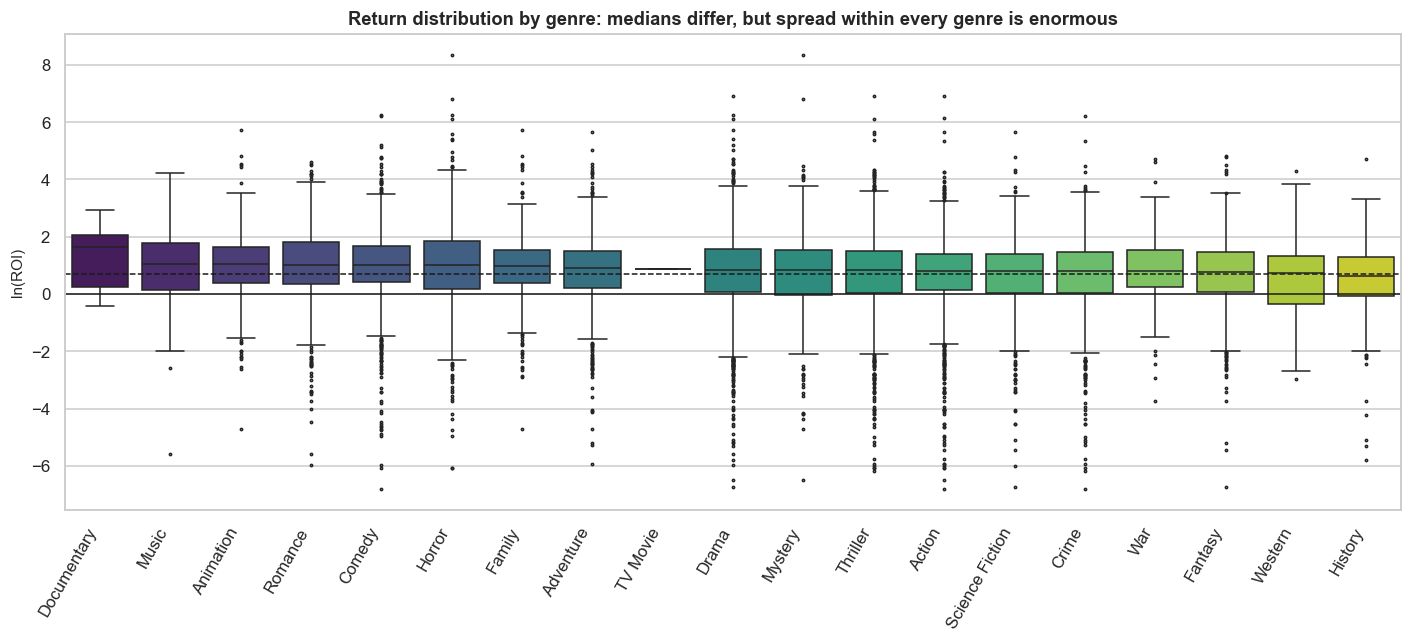

In [13]:
fig, ax = plt.subplots(figsize=(13, 6))
order2 = ge.groupby('genres').log_roi.median().sort_values(ascending=False).index
sns.boxplot(data=ge, x='genres', y='log_roi', order=order2, ax=ax, fliersize=1.5, linewidth=1, palette='viridis')
ax.axhline(0, c='k', lw=1); ax.axhline(np.log(2), c='k', ls='--', lw=1)
ax.set_xticklabels(ax.get_xticklabels(), rotation=60, ha='right'); ax.set_ylabel('ln(ROI)'); ax.set_xlabel('')
ax.set_title('Return distribution by genre: medians differ, but spread within every genre is enormous')
plt.tight_layout()
plt.show()

### 5.6 Genre co-occurrence (lift)
Lift = P(A and B) / (P(A) x P(B)). Lift > 1 means two genres appear together *more than chance* (e.g. Animation + Family); lift < 1 means they rarely mix.

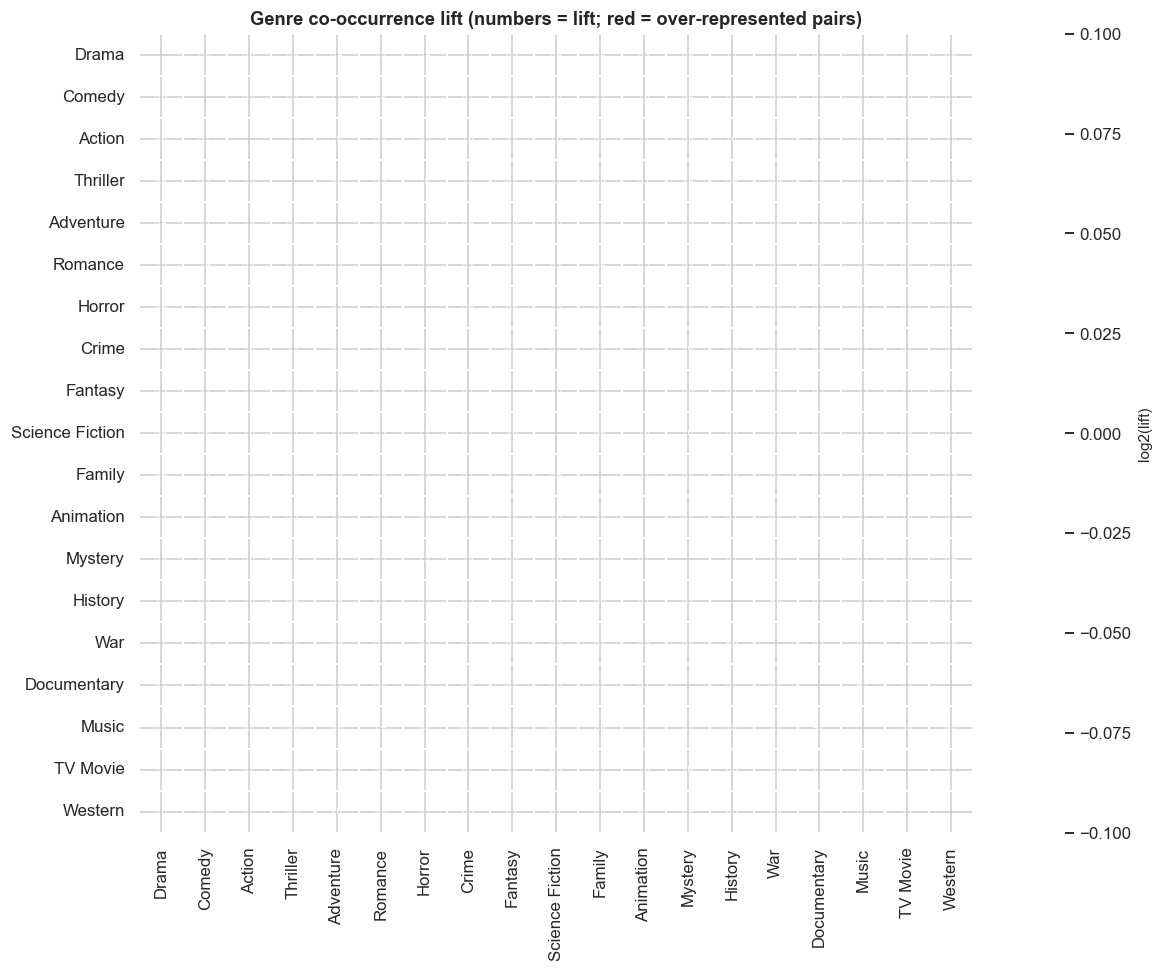

Strongest genre affinities:
History      War         8.590
Family       Animation   5.230
Documentary  Music       4.240
Fantasy      Animation   3.220
             Family      3.140
Music        TV Movie    2.990

Strongest genre repulsions:
Science Fiction  Documentary   0.030
Thriller         Family        0.030
Romance          Documentary   0.020
Science Fiction  History       0.020
Mystery          Documentary   0.000
Documentary      Western       0.000


In [14]:
G = df[list(GENRE_COLS.values())].values.astype(float)
co = G.T @ G / len(df); p = np.diag(co)
lift = pd.DataFrame(co / np.outer(p, p), index=GENRES, columns=GENRES)
mask = np.eye(len(GENRES), dtype=bool)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(np.log2(lift), mask=mask, cmap='RdBu_r', center=0, ax=ax, annot=lift.round(1).where(~mask).values, fmt='', annot_kws={'size': 6},
            cbar_kws={'label': 'log2(lift)'}, linewidths=.3)
ax.set_title('Genre co-occurrence lift (numbers = lift; red = over-represented pairs)')
plt.tight_layout()
plt.show()
pairs = (lift.where(np.triu(np.ones_like(lift, dtype=bool), 1)).stack().sort_values(ascending=False))
print('Strongest genre affinities:'); print(pairs.head(6).round(2).to_string())
print('\nStrongest genre repulsions:'); print(pairs.tail(6).round(2).to_string())

### 5.7 Release timing

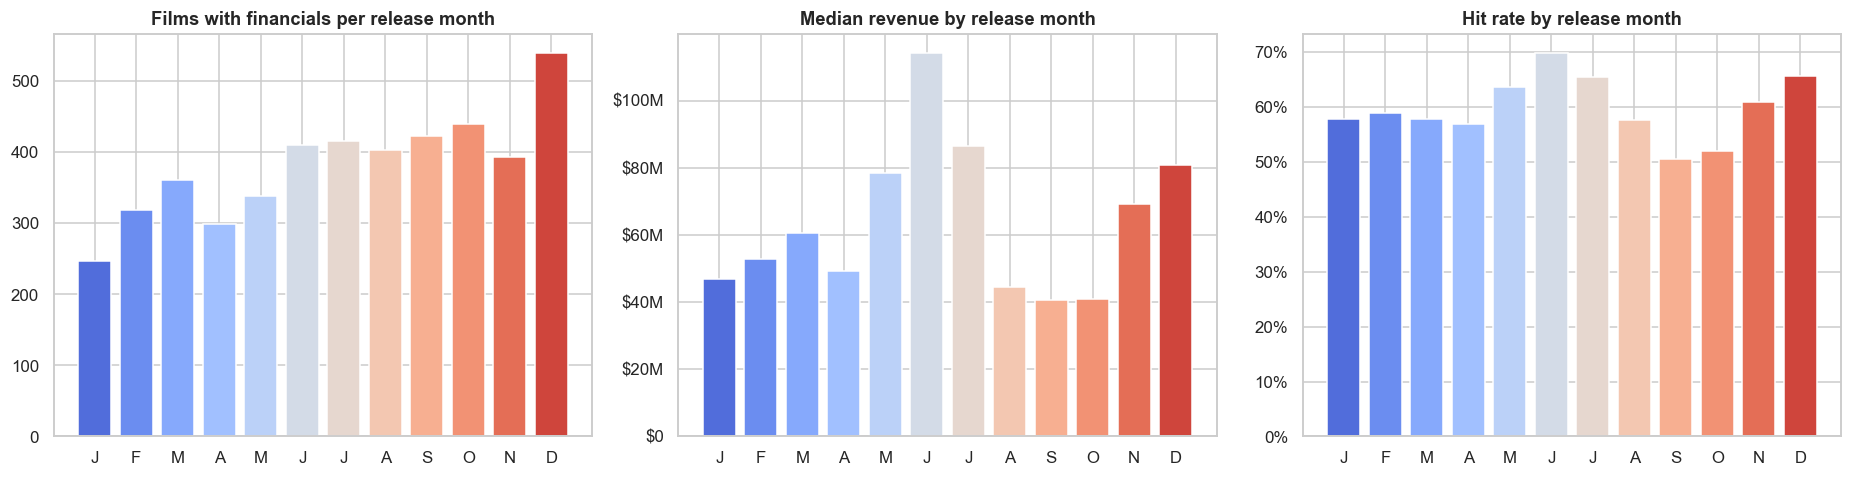

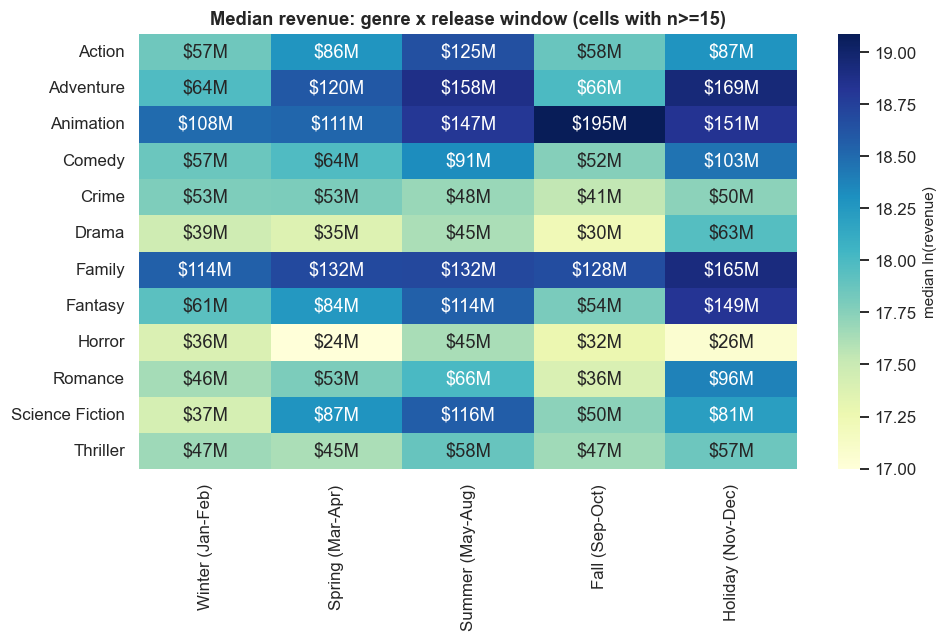

In [15]:
mo = fin.groupby('month').agg(n=('id', 'size'), med_rev=('revenue', 'median'), med_roi=('roi', 'median'), hit=('hit', 'mean'))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
mn = ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D']
for a, c, t, f in [(ax[0], 'n', 'Films with financials per release month', None), (ax[1], 'med_rev', 'Median revenue by release month', MONEY), (ax[2], 'hit', 'Hit rate by release month', mtick.PercentFormatter(1.0))]:
    a.bar(range(1, 13), mo[c], color=sns.color_palette('coolwarm', 12)); a.set_xticks(range(1, 13)); a.set_xticklabels(mn); a.set_title(t)
    if f: a.yaxis.set_major_formatter(f)
plt.tight_layout(); savefig('10_seasonality'); plt.show()

gse = fin.explode('genres').reset_index(drop=True)
hm = gse[gse.genres.isin(GENRES[:12])].pivot_table(index='genres', columns='season', values='log_revenue', aggfunc='median')
cnt = gse[gse.genres.isin(GENRES[:12])].pivot_table(index='genres', columns='season', values='id', aggfunc='count')
hm = hm.where(cnt >= 15)[['Winter (Jan-Feb)', 'Spring (Mar-Apr)', 'Summer (May-Aug)', 'Fall (Sep-Oct)', 'Holiday (Nov-Dec)']]
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(hm, cmap='YlGnBu', annot=np.exp(hm).map(lambda v: money(v) if pd.notna(v) else ''), fmt='', ax=ax, cbar_kws={'label': 'median ln(revenue)'})
ax.set_title('Median revenue: genre x release window (cells with n>=15)'); ax.set_ylabel(''); ax.set_xlabel('')
plt.tight_layout()
plt.show()

### 5.8 Language, country, studios and talent

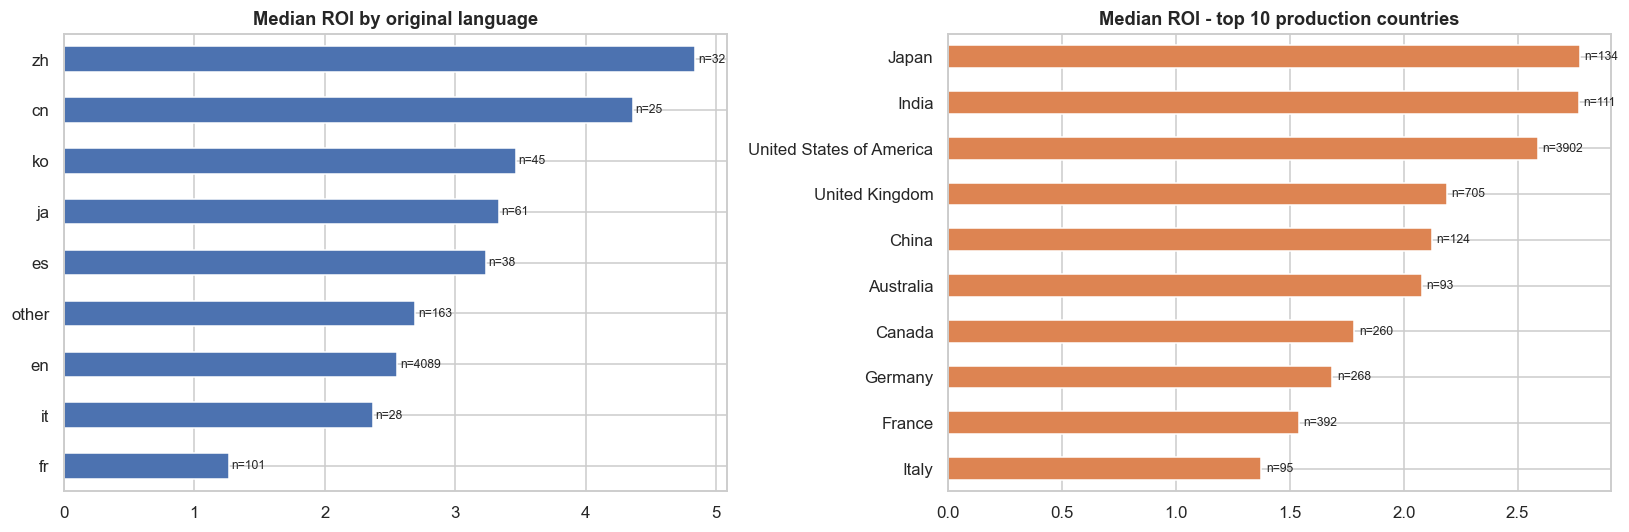

In [16]:
lg = fin.groupby('lang_group').agg(n=('id', 'size'), med_rev=('revenue', 'median'), hit=('hit', 'mean'), med_roi=('roi', 'median')).sort_values('n', ascending=False)
ce = fin.explode('production_countries').reset_index(drop=True); ce = ce[ce.production_countries.notna()]
top_c = ce.production_countries.value_counts().head(10).index
cs = ce[ce.production_countries.isin(top_c)].groupby('production_countries').agg(n=('id', 'size'), med_rev=('revenue', 'median'), hit=('hit', 'mean'), med_roi=('roi', 'median')).sort_values('med_roi')
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
lg.med_roi.sort_values().plot.barh(ax=ax[0], color='#4C72B0'); ax[0].set_title('Median ROI by original language'); ax[0].set_ylabel('')
for i, l in enumerate(lg.med_roi.sort_values().index): ax[0].text(lg.med_roi[l] + .02, i, f'n={lg.n[l]}', va='center', fontsize=8)
cs.med_roi.plot.barh(ax=ax[1], color='#DD8452'); ax[1].set_title('Median ROI - top 10 production countries'); ax[1].set_ylabel('')
for i, l in enumerate(cs.index): ax[1].text(cs.med_roi[l] + .02, i, f'n={cs.n[l]}', va='center', fontsize=8)
plt.tight_layout()
plt.show()

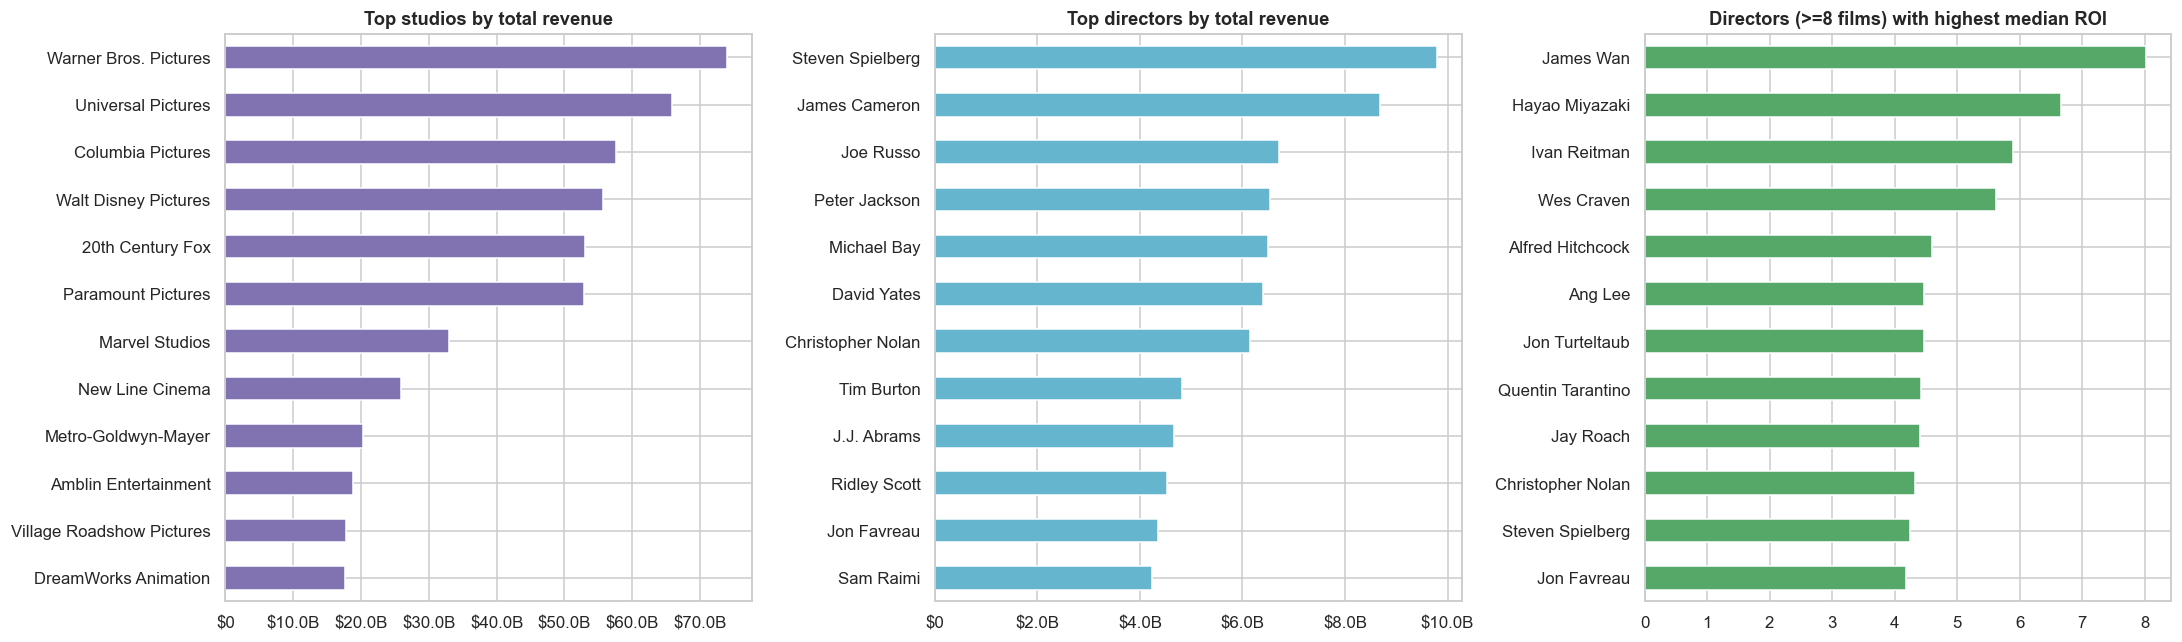

In [17]:
co_ = fin.explode('production_companies').reset_index(drop=True); co_ = co_[co_.production_companies.notna()]
cstat = co_.groupby('production_companies').agg(n=('id', 'size'), total_revenue=('revenue', 'sum'), med_roi=('roi', 'median'), hit=('hit', 'mean'))
dstat = fin[fin.director != 'Unknown'].groupby('director').agg(n=('id', 'size'), total_revenue=('revenue', 'sum'), med_roi=('roi', 'median'), hit=('hit', 'mean'))
fig, ax = plt.subplots(1, 3, figsize=(20, 6))
cstat.total_revenue.nlargest(12).sort_values().plot.barh(ax=ax[0], color='#8172B2'); ax[0].xaxis.set_major_formatter(MONEY); ax[0].set_title('Top studios by total revenue'); ax[0].set_ylabel('')
dstat.total_revenue.nlargest(12).sort_values().plot.barh(ax=ax[1], color='#64B5CD'); ax[1].xaxis.set_major_formatter(MONEY); ax[1].set_title('Top directors by total revenue'); ax[1].set_ylabel('')
d10 = dstat[dstat.n >= 8].med_roi.nlargest(12).sort_values()
d10.plot.barh(ax=ax[2], color='#55A868'); ax[2].set_title('Directors (>=8 films) with highest median ROI'); ax[2].set_ylabel('')
plt.tight_layout()
plt.show()

### 5.9 Audience reception

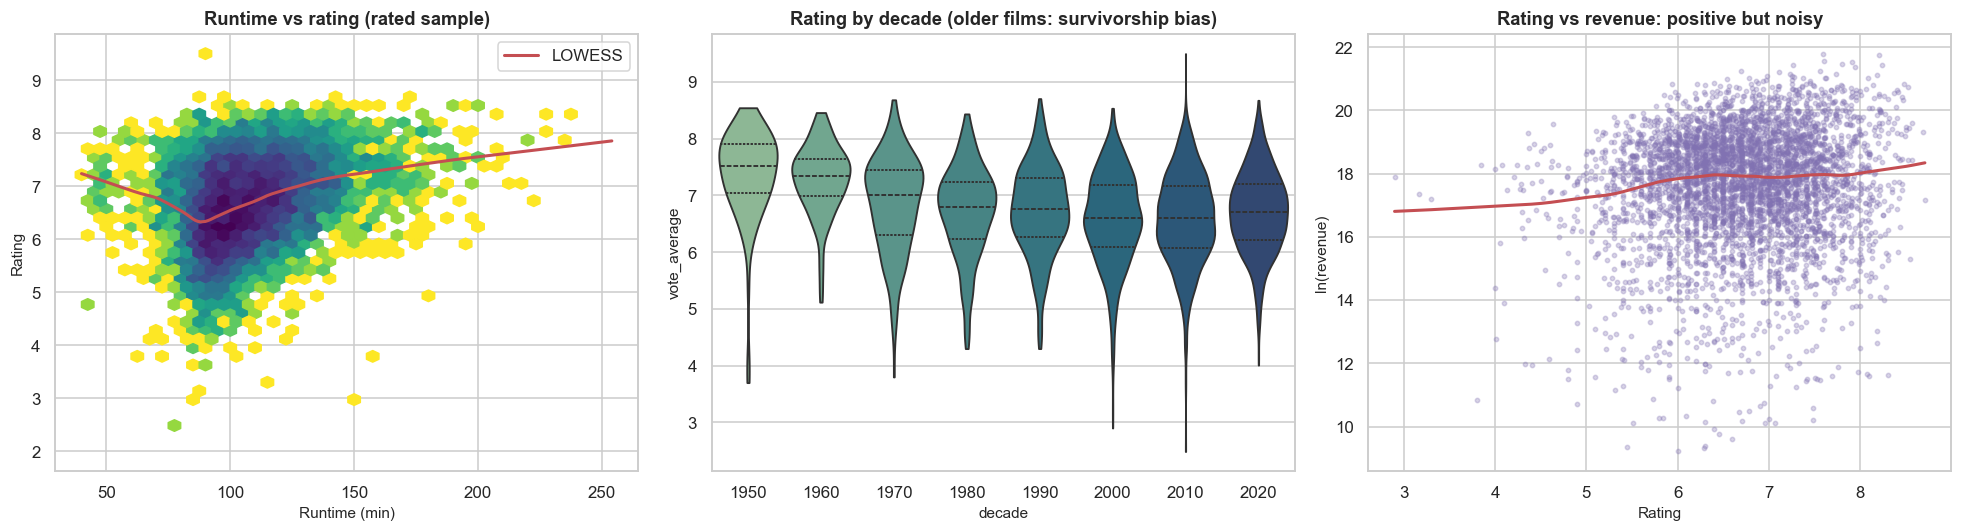

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
hb = ax[0].hexbin(rated.runtime, rated.vote_average, gridsize=40, cmap='viridis_r', mincnt=1, bins='log', extent=(40, 240, 2, 9.5))
ax[0].set_xlabel('Runtime (min)'); ax[0].set_ylabel('Rating'); ax[0].set_title('Runtime vs rating (rated sample)')
lo = sm.nonparametric.lowess(rated.vote_average, rated.runtime, frac=.3); ax[0].plot(lo[:, 0], lo[:, 1], c='r', lw=2, label='LOWESS'); ax[0].legend()
sns.violinplot(data=rated[rated.decade >= 1950], x='decade', y='vote_average', ax=ax[1], palette='crest', cut=0, inner='quartile'); ax[1].set_title('Rating by decade (older films: survivorship bias)')
fr = fin.dropna(subset=['vote_average'])
ax[2].scatter(fr.vote_average, fr.log_revenue, s=8, alpha=.3, c='#8172B2')
lo = sm.nonparametric.lowess(fr.log_revenue, fr.vote_average, frac=.3); ax[2].plot(lo[:, 0], lo[:, 1], c='r', lw=2)
ax[2].set_xlabel('Rating'); ax[2].set_ylabel('ln(revenue)'); ax[2].set_title('Rating vs revenue: positive but noisy')
plt.tight_layout()
plt.show()

### 5.10 Correlation structure (Spearman - robust to skew)

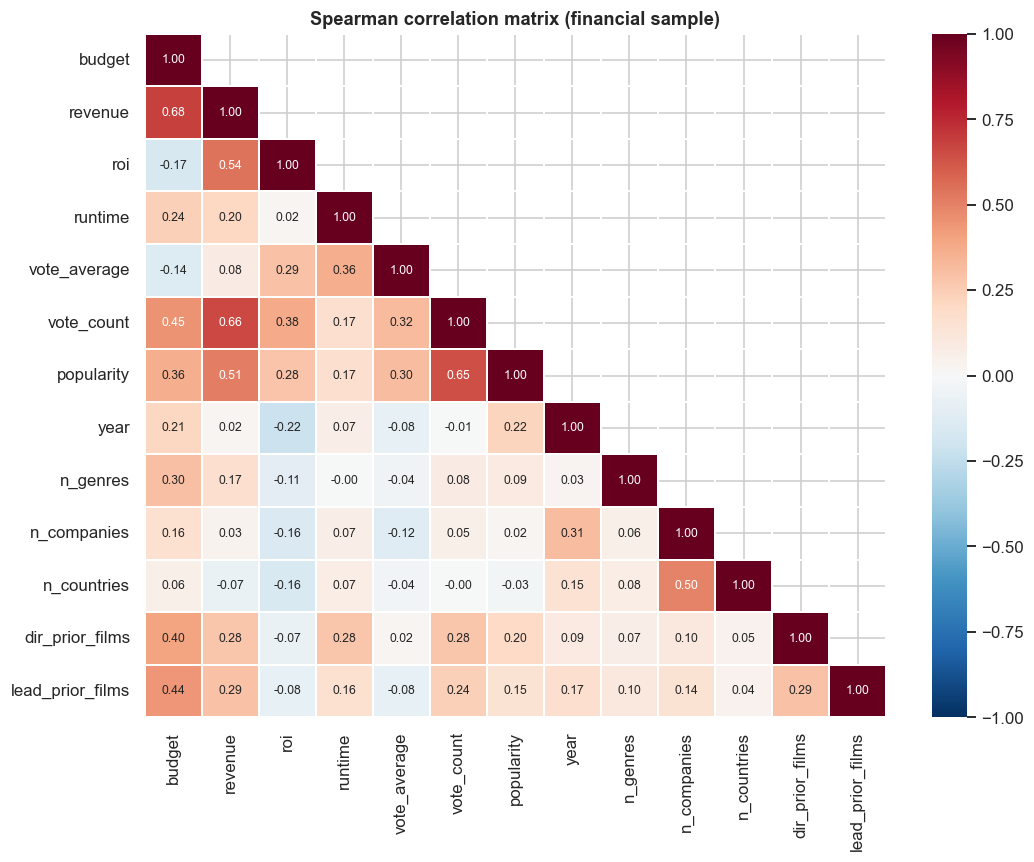

In [19]:
num_cols = ['budget', 'revenue', 'roi', 'runtime', 'vote_average', 'vote_count', 'popularity', 'year', 'n_genres', 'n_companies', 'n_countries',
            'dir_prior_films', 'lead_prior_films']
cm = fin[num_cols].corr(method='spearman')
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, mask=np.triu(np.ones_like(cm, dtype=bool), 1), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax, annot_kws={'size': 8}, linewidths=.3)
ax.set_title('Spearman correlation matrix (financial sample)')
plt.tight_layout()
plt.show()

## 6. In-Depth Statistical Analysis (Descriptive)

### 6.1 Summary statistics beyond the mean
For skewed data the mean, SD, and range mislead; I report robust measures (median, IQR) alongside shape statistics (skewness, excess kurtosis) and the coefficient of variation.

In [20]:
def describe_full(s):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75])
    return pd.Series({'n': len(s), 'mean': s.mean(), 'std': s.std(), 'median': s.median(), 'IQR': q3 - q1,
                      'min': s.min(), 'p5': s.quantile(.05), 'p95': s.quantile(.95), 'max': s.max(),
                      'skew': stats.skew(s), 'ex_kurtosis': stats.kurtosis(s), 'CV': s.std() / s.mean()})
desc_vars = ['budget', 'revenue', 'profit', 'roi', 'runtime', 'vote_average', 'popularity']
desc = pd.DataFrame({v: describe_full(fin[v]) for v in desc_vars}).T
desc.style.format('{:,.2f}')

,n,mean,std,median,IQR,min,p5,p95,max,skew,ex_kurtosis,CV
budget,"4,582.00","41,894,138.22","49,869,671.94","25,000,000.00","45,075,000.00","10,000.00","1,450,420.80","150,000,000.00","460,000,000.00",2.32,7.16,1.19
revenue,"4,582.00","133,819,366.59","216,648,627.52","59,237,106.00","138,393,160.25","10,000.00","1,600,000.00","523,892,838.05","2,923,706,026.00",4.23,28.21,1.62
profit,"4,582.00","91,925,228.37","185,153,459.36","30,942,600.50","102,100,000.00","-199,545,977.00","-20,367,264.75","402,941,215.40","2,686,706,026.00",4.65,34.47,2.01
roi,"4,582.00",7.19,67.32,2.56,3.71,0.00,0.20,17.28,"4,143.98",52.30,"3,130.62",9.37
runtime,"4,579.00",112.09,21.73,108.00,26.00,57.00,86.00,153.10,254.00,1.33,3.21,0.19
vote_average,"4,582.00",6.71,0.77,6.71,1.06,2.90,5.40,7.93,8.71,-0.32,0.30,0.11
popularity,"4,582.00",6.22,15.12,3.72,3.93,0.82,1.82,15.70,681.31,26.28,985.64,2.43


**Reading the table.** Revenue and profit have skewness well above 5 and enormous kurtosis: a handful of billion-dollar films dominate the mean. The mean ROI is pulled far above the median ROI by a few extreme multiples. **Median-based and log-based summaries are therefore the honest descriptors** for money variables.

### 6.2 Normality assessment
Tests are run on raw and log-transformed values. With n≈4,500 even trivial departures from normality are "significant", so I pair p-values with **Q-Q plots** and judge by shape, not just p.

In [21]:
def normality_row(x, name):
    x = x.dropna().values
    k2, p_k2 = stats.normaltest(x)
    sub = rng.choice(x, size=min(5000, len(x)), replace=False)
    w, p_w = stats.shapiro(sub)
    jb, p_jb = stats.jarque_bera(x)
    return {'variable': name, 'n': len(x), 'skew': stats.skew(x), 'ex_kurt': stats.kurtosis(x),
            "D'Agostino K2 p": p_k2, 'Shapiro-Wilk W': w, 'Shapiro p': p_w, 'Jarque-Bera p': p_jb}
rows = []
for v in ['budget', 'revenue', 'roi', 'runtime']:
    rows.append(normality_row(fin[v], f'{v} (raw)'))
    rows.append(normality_row(np.log(fin[v]), f'{v} (ln)'))
rows.append(normality_row(rated.vote_average, 'vote_average (raw)'))
norm_tbl = pd.DataFrame(rows).set_index('variable')
norm_tbl.style.format({"D'Agostino K2 p": '{:.2e}', 'Shapiro p': '{:.2e}', 'Jarque-Bera p': '{:.2e}', 'skew': '{:.2f}', 'ex_kurt': '{:.2f}', 'Shapiro-Wilk W': '{:.3f}'})

,n,skew,ex_kurt,D'Agostino K2 p,Shapiro-Wilk W,Shapiro p,Jarque-Bera p
variable,,,,,,,
budget (raw),4582,2.32,7.16,0.00e+00,0.747,2.90e-64,0.00e+00
budget (ln),4582,-1.04,2.04,1.19e-173,0.948,1.75e-37,0.00e+00
revenue (raw),4582,4.23,28.21,0.00e+00,0.585,3.66e-74,0.00e+00
revenue (ln),4582,-1.06,1.82,1.05e-171,0.944,1.50e-38,0.00e+00
roi (raw),4582,52.30,3130.62,0.00e+00,0.040,1.41e-92,0.00e+00
roi (ln),4582,-0.79,3.52,2.21e-164,0.944,1.33e-38,0.00e+00
runtime (raw),4579,1.33,3.21,1.44e-254,0.921,7.77e-44,0.00e+00
runtime (ln),4579,0.61,0.74,3.79e-66,0.978,8.19e-26,5.96e-85
vote_average (raw),7320,-0.39,0.43,4.76e-47,0.990,5.37e-18,1.96e-53


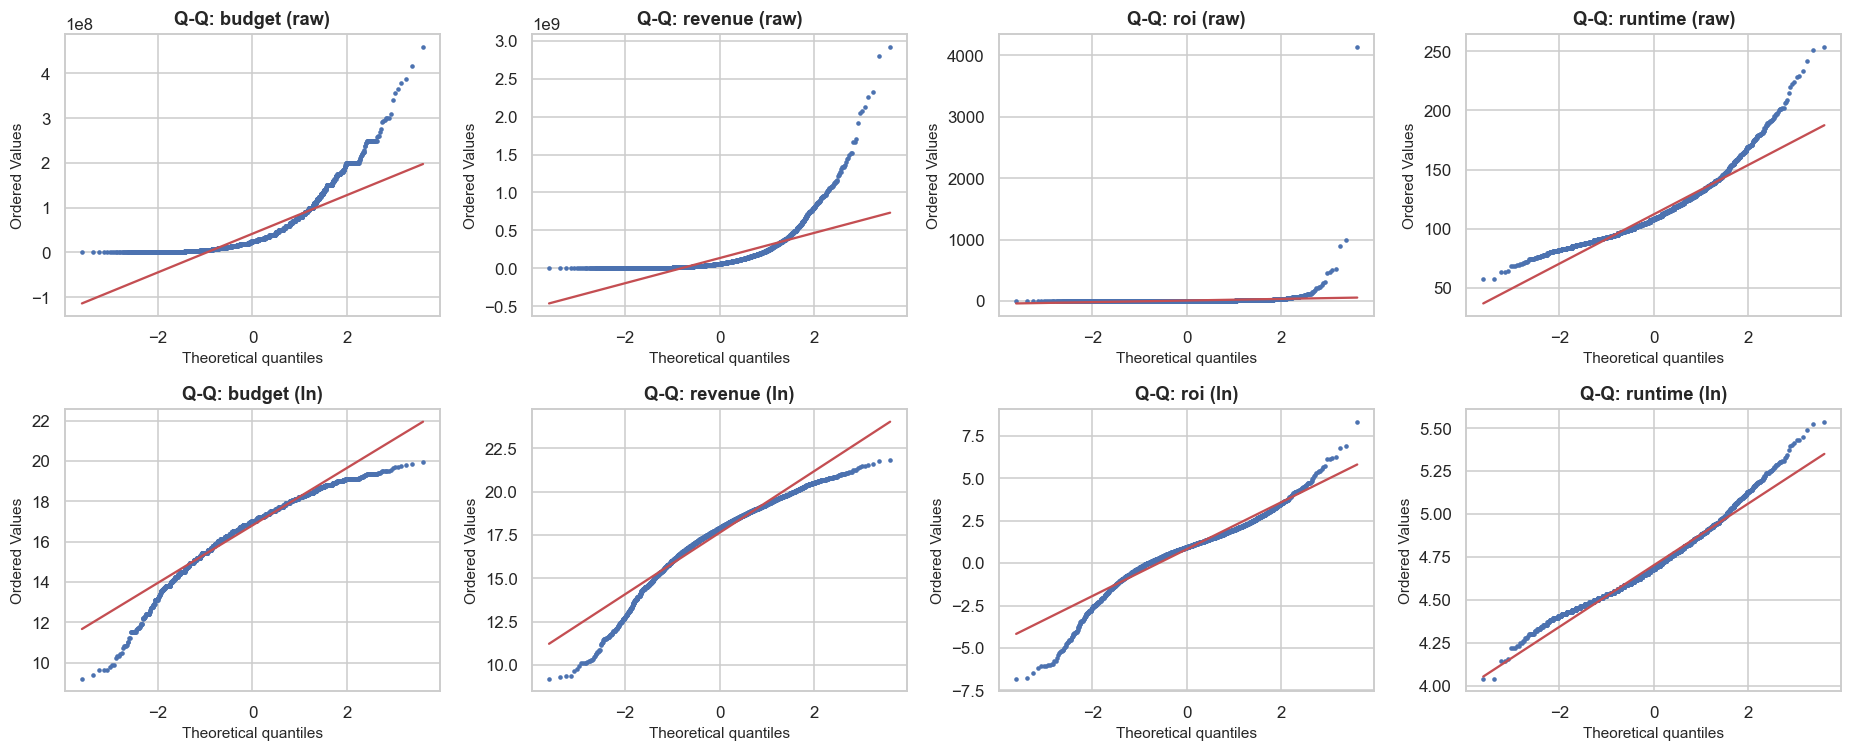

In [22]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for j, v in enumerate(['budget', 'revenue', 'roi', 'runtime']):
    for i, (x, lab) in enumerate([(fin[v].dropna(), 'raw'), (np.log(fin[v].dropna()), 'ln')]):
        stats.probplot(x, dist='norm', plot=axes[i, j])
        axes[i, j].set_title(f'Q-Q: {v} ({lab})'); axes[i, j].get_lines()[0].set_markersize(2); axes[i, j].get_lines()[1].set_color('r')
plt.tight_layout()
plt.show()

**Conclusion:** raw money variables fail normality dramatically (Q-Q curves bend away from the line). Their log transforms are far closer to normal (though still heavy-tailed), so log-scale analysis with robust or non-parametric confirmation is the defensible approach. Runtime is near-normal in the centre with a long right tail.

### 6.3 Outlier analysis
Two complementary rules: Tukey fences (1.5 x IQR) and the robust modified z-score based on the MAD (|M| > 3.5). Outliers here are *real* (genuine blockbusters and flops), not errors, so I **flag but do not delete** them.

In [23]:
def tukey(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - k * i) | (s > q3 + k * i)
def mod_z(s):
    med = s.median(); mad = (s - med).abs().median()
    return 0.6745 * (s - med) / mad
out_tbl = pd.DataFrame({v: {'Tukey outliers': int(tukey(fin[v]).sum()), 'MAD outliers (|M|>3.5)': int((mod_z(fin[v]).abs() > 3.5).sum()),
                            '% flagged (Tukey)': 100 * tukey(fin[v]).mean()} for v in ['log_budget', 'log_revenue', 'log_roi', 'runtime']}).T
display(out_tbl.round(1))
fin['roi_outlier'] = tukey(fin.log_roi)
cols = ['title', 'year', 'budget', 'revenue', 'roi']
print('Largest ROI outliers (cheap films that exploded):')
display(fin[fin.roi_outlier].nlargest(8, 'roi')[cols].assign(budget=lambda d: d.budget.map(money), revenue=lambda d: d.revenue.map(money)))
print('Largest negative outliers (revenue far below budget):')
display(fin[fin.roi_outlier].nsmallest(8, 'roi')[cols].assign(budget=lambda d: d.budget.map(money), revenue=lambda d: d.revenue.map(money)))

,Tukey outliers,MAD outliers (|M|>3.5),% flagged (Tukey)
log_budget,125.000,67.000,2.700
log_revenue,153.000,82.000,3.300
log_roi,266.000,125.000,5.800
runtime,147.000,72.000,3.200


Largest ROI outliers (cheap films that exploded):


,title,year,budget,revenue,roi
2471,The Blair Witch Project,1999,$60K,$249M,"4,143.985"
598,Fist of Fury,1972,$100K,$100M,"1,000.000"
3698,Paranormal Activity,2007,$215K,$193M,899.329
6282,One Cut of the Dead,2017,$52K,$28M,526.470
596,Pink Flamingos,1972,$12K,$6M,500.000
653,Enter the Dragon,1973,$850K,$400M,470.588
3027,Open Water,2003,$120K,$55M,455.696
126,Bambi,1942,$858K,$267M,311.710


Largest negative outliers (revenue far below budget):


,title,year,budget,revenue,roi
7507,Red Notice,2021,$160M,$178K,0.001
7263,Space Sweepers,2021,$21M,$25K,0.001
7794,Hunt,2022,$17M,$26K,0.002
8409,The Killer,2023,$175M,$362K,0.002
7759,The Gray Man,2022,$200M,$454K,0.002
7853,Project Wolf Hunting,2022,$9M,$21K,0.002
3746,Trick 'r Treat,2007,$12M,$28K,0.002
7191,Skylines,2020,$70M,$171K,0.002


### 6.4 Correlation analysis with confidence intervals
Three coefficients answer different questions: **Pearson** (linear), **Spearman** (monotonic, rank-based), **Kendall** (rank concordance, more robust with ties). A large gap between Pearson and Spearman signals nonlinearity or outlier influence. Pearson CIs use the Fisher z-transform; Spearman CIs use a bootstrap.

In [24]:
def corr_row(d, x, y, B=1000):
    d = d[[x, y]].dropna(); a, b = d[x].values, d[y].values; n = len(d)
    r, p = stats.pearsonr(a, b); rho, p_s = stats.spearmanr(a, b); tau, p_k = stats.kendalltau(a, b)
    z = np.arctanh(r); se = 1 / np.sqrt(n - 3); lo, hi = np.tanh([z - 1.96 * se, z + 1.96 * se])
    idx = rng.integers(0, n, (B, n))
    boots = [stats.spearmanr(a[i], b[i])[0] for i in idx[:300]]   # 300 bootstrap resamples
    return {'pair': f'{x} ~ {y}', 'n': n, 'Pearson r': r, 'Pearson 95% CI': f'[{lo:.2f}, {hi:.2f}]', 'Spearman rho': rho,
            'Spearman 95% CI': f'[{np.percentile(boots, 2.5):.2f}, {np.percentile(boots, 97.5):.2f}]', 'Kendall tau': tau, 'p (Spearman)': p_s}
pairs = [('log_budget', 'log_revenue'), ('log_budget', 'log_roi'), ('log_budget', 'vote_average'), ('runtime', 'vote_average'),
         ('vote_average', 'log_revenue'), ('year', 'log_budget'), ('year', 'log_roi'), ('runtime', 'log_budget'),
         ('dir_prior_mean_logrev', 'log_revenue'), ('lead_prior_mean_logrev', 'log_revenue'), ('n_genres', 'log_revenue')]
corr_tbl = pd.DataFrame([corr_row(fin, x, y) for x, y in pairs]).set_index('pair')
corr_tbl.style.format({'Pearson r': '{:.3f}', 'Spearman rho': '{:.3f}', 'Kendall tau': '{:.3f}', 'p (Spearman)': '{:.1e}'})

,n,Pearson r,Pearson 95% CI,Spearman rho,Spearman 95% CI,Kendall tau,p (Spearman)
pair,,,,,,,
log_budget ~ log_revenue,4582,0.646,"[0.63, 0.66]",0.683,"[0.67, 0.70]",0.505,0.0e+00
log_budget ~ log_roi,4582,-0.199,"[-0.23, -0.17]",-0.171,"[-0.20, -0.14]",-0.112,3.0e-31
log_budget ~ vote_average,4582,-0.117,"[-0.15, -0.09]",-0.137,"[-0.17, -0.11]",-0.093,1.3e-20
runtime ~ vote_average,4579,0.357,"[0.33, 0.38]",0.361,"[0.33, 0.39]",0.250,4.5e-141
vote_average ~ log_revenue,4582,0.109,"[0.08, 0.14]",0.080,"[0.05, 0.11]",0.054,6.5e-08
year ~ log_budget,4582,0.376,"[0.35, 0.40]",0.212,"[0.19, 0.24]",0.152,1.0e-47
year ~ log_roi,4582,-0.255,"[-0.28, -0.23]",-0.217,"[-0.24, -0.19]",-0.148,6.9e-50
runtime ~ log_budget,4579,0.222,"[0.19, 0.25]",0.241,"[0.21, 0.27]",0.167,2.1e-61
dir_prior_mean_logrev ~ log_revenue,2613,0.455,"[0.42, 0.49]",0.479,"[0.44, 0.51]",0.336,3.1e-150


**Partial correlation.** Is the budget-revenue link just an artefact of both rising over time or of film length? I regress each on the confounders, correlate the **residuals**, and compare with the raw correlation.

In [25]:
def partial_corr(d, x, y, controls):
    d = d[[x, y] + controls].dropna()
    Z = sm.add_constant(d[controls])
    rx = sm.OLS(d[x], Z).fit().resid; ry = sm.OLS(d[y], Z).fit().resid
    r, p = stats.pearsonr(rx, ry)
    return r, p, len(d)
r0 = fin[['log_budget', 'log_revenue']].corr().iloc[0, 1]
for ctrl in [['year'], ['year', 'runtime'], ['year', 'runtime', 'is_us', 'is_english']]:
    r, p, n = partial_corr(fin, 'log_budget', 'log_revenue', ctrl)
    print(f'ln(budget) ~ ln(revenue) | controlling {ctrl}:  r = {r:.3f}   (raw r = {r0:.3f}, n = {n})')
r, p, n = partial_corr(fin.dropna(subset=['vote_average']), 'vote_average', 'log_revenue', ['log_budget', 'year'])
print(f'rating ~ ln(revenue) | budget, year: r = {r:.3f}  (compare with the raw rating-revenue correlation in 6.4)')

ln(budget) ~ ln(revenue) | controlling ['year']:  r = 0.659   (raw r = 0.646, n = 4582)
ln(budget) ~ ln(revenue) | controlling ['year', 'runtime']:  r = 0.640   (raw r = 0.646, n = 4579)
ln(budget) ~ ln(revenue) | controlling ['year', 'runtime', 'is_us', 'is_english']:  r = 0.598   (raw r = 0.646, n = 4579)
rating ~ ln(revenue) | budget, year: r = 0.225  (compare with the raw rating-revenue correlation in 6.4)


### 6.5 Non-linear dependence (mutual information)
Mutual information captures *any* dependence with `ln(revenue)`, linear or not. Variables with high MI but low correlation are non-linear signals worth feeding to tree models.

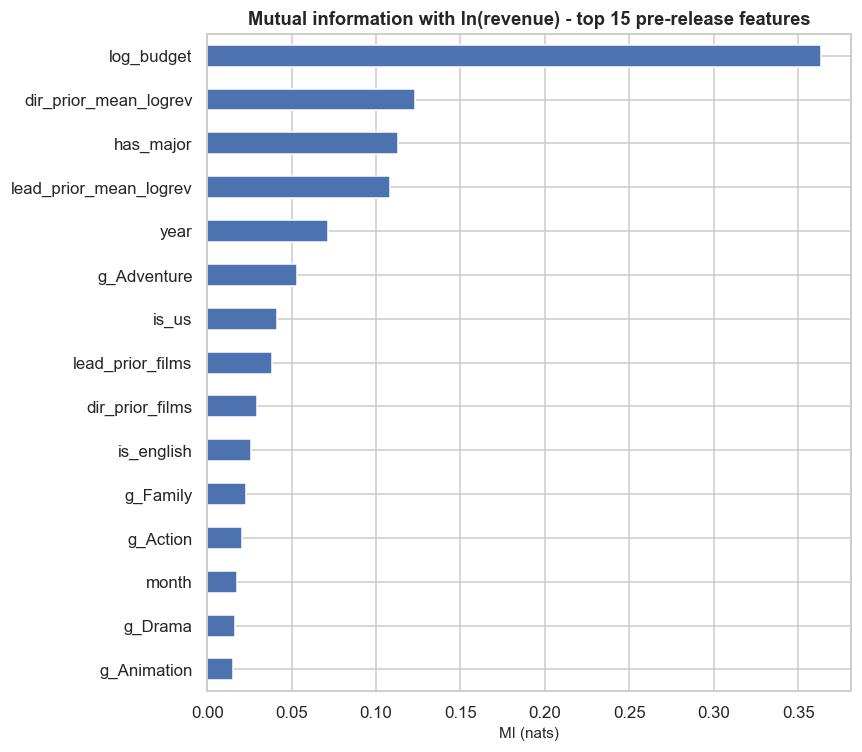

In [26]:
from sklearn.feature_selection import mutual_info_regression
mi_feats = ['log_budget', 'runtime', 'year', 'month', 'n_genres', 'n_countries', 'n_companies', 'is_us', 'is_english', 'has_major',
            'dir_prior_films', 'lead_prior_films', 'dir_prior_mean_logrev', 'lead_prior_mean_logrev'] + list(GENRE_COLS.values())
Xmi = fin[mi_feats].fillna(fin[mi_feats].median())
mi = pd.Series(mutual_info_regression(Xmi, fin.log_revenue, random_state=SEED), index=mi_feats).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
mi.tail(15).plot.barh(ax=ax, color='#4C72B0'); ax.set_title('Mutual information with ln(revenue) - top 15 pre-release features'); ax.set_xlabel('MI (nats)')
plt.tight_layout()
plt.show()

### 6.6 Trend tests
Has the economics of film changed? I test monotonic trends with Spearman correlation against year (a non-parametric Mann-Kendall-style test) and regress hit probability on year.

In [27]:
trend = []
for v in ['log_budget', 'log_revenue', 'log_roi', 'runtime', 'n_genres']:
    d = fin[['year', v]].dropna(); rho, p = stats.spearmanr(d.year, d[v]); trend.append((v, rho, p))
trend = pd.DataFrame(trend, columns=['variable', 'Spearman rho vs year', 'p-value']).set_index('variable')
display(trend.style.format({'Spearman rho vs year': '{:.3f}', 'p-value': '{:.1e}'}))
lm = smf.logit('hit ~ I((year-2000)/10)', data=fin).fit(disp=0)
b = lm.params.iloc[1]; ci = lm.conf_int().iloc[1]
print(f'Logistic trend: odds of a hit change by x{np.exp(b):.2f} per decade (95% CI {np.exp(ci[0]):.2f}-{np.exp(ci[1]):.2f}), p = {lm.pvalues.iloc[1]:.3g}')

,Spearman rho vs year,p-value
variable,,
log_budget,0.212,1.0e-47
log_revenue,0.021,1.6e-01
log_roi,-0.217,6.9e-50
runtime,0.067,6.0e-06
n_genres,0.030,4.5e-02


Logistic trend: odds of a hit change by x0.79 per decade (95% CI 0.76-0.82), p = 2.11e-28


## 7. Inferential Statistics

The goal is to move from "what happened in this sample" to "what we can say about the broader population of commercially released films", with uncertainty quantified. **Every test below reports an effect size and a confidence interval; a p-value alone says nothing about practical importance.**

**Reusable helpers** (effect sizes and a vectorised bootstrap):

In [28]:
fin['season_short'] = fin.season.str.split().str[0]
GENRES_OK = [g for g in GENRES if (fin[GENRE_COLS[g]].sum() >= 30)]       # genres with enough financial data to test
GCOLS_OK = [GENRE_COLS[g] for g in GENRES_OK]
print(f'{len(GENRES_OK)} genres have >=30 films with financials:', GENRES_OK)

def cohen_d(a, b):
    a, b = np.asarray(a), np.asarray(b); na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (a.mean() - b.mean()) / sp
def cliffs_delta(a, b):
    """P(a>b) - P(a<b), via the Mann-Whitney U statistic. Range [-1, 1]."""
    u = stats.mannwhitneyu(a, b, alternative='two-sided').statistic
    return 2 * u / (len(a) * len(b)) - 1
def boot_ci(x, stat=np.median, B=5000, level=95):
    x = np.asarray(x); idx = rng.integers(0, len(x), (B, len(x)))
    vals = stat(x[idx], axis=1)
    return np.percentile(vals, [(100 - level) / 2, 100 - (100 - level) / 2])
def boot_diff_ci(a, b, stat=np.median, B=5000, level=95):
    a, b = np.asarray(a), np.asarray(b)
    ia = rng.integers(0, len(a), (B, len(a))); ib = rng.integers(0, len(b), (B, len(b)))
    d = stat(a[ia], axis=1) - stat(b[ib], axis=1)
    return np.percentile(d, [(100 - level) / 2, 100 - (100 - level) / 2])
def epsilon_sq(H, n): return H * (n + 1) / (n ** 2 - 1)           # effect size for Kruskal-Wallis
def cramers_v(chi2, n, r, c): return np.sqrt(chi2 / (n * (min(r, c) - 1)))
def verdict(p, a=.05): return 'reject H0' if p < a else 'fail to reject H0'

17 genres have >=30 films with financials: ['Drama', 'Comedy', 'Action', 'Thriller', 'Adventure', 'Romance', 'Horror', 'Crime', 'Fantasy', 'Science Fiction', 'Family', 'Animation', 'Mystery', 'History', 'War', 'Music', 'Western']


### 7.1 Confidence intervals for the headline numbers
Bootstrap intervals make no distributional assumptions - ideal for skewed ROI. The hit rate uses the Wilson interval, which behaves well near 0 or 1.

,estimate,ci_low,ci_high,method
metric,,,,
Median ROI (x),2.560,2.465,2.646,bootstrap
Mean ROI (x) - fragile,7.187,5.690,9.458,bootstrap
Geometric-mean revenue ($),"45,053,281.319","42,734,923.809","47,497,409.067",t-interval on ln scale
Hit rate (>=2x),0.599,0.585,0.613,Wilson
Loss rate (ROI<1),0.207,0.196,0.219,Wilson


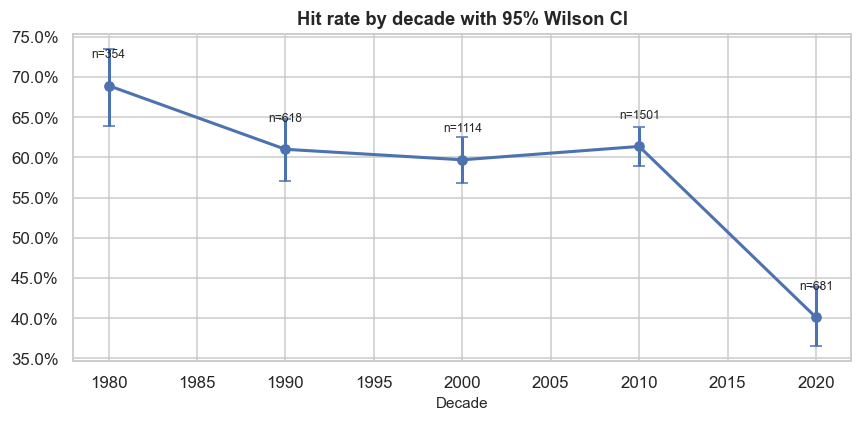

In [29]:
n = len(fin)
mean_lr = fin.log_revenue.mean(); se = fin.log_revenue.sem()
lo, hi = stats.t.interval(.95, n - 1, mean_lr, se)
hit_lo, hit_hi = proportion_confint(fin.hit.sum(), n, method='wilson')
roi_ci = boot_ci(fin.roi); mroi_ci = boot_ci(fin.roi, np.mean)
headline = pd.DataFrame([
    ['Median ROI (x)', fin.roi.median(), *roi_ci, 'bootstrap'],
    ['Mean ROI (x)  - fragile', fin.roi.mean(), *mroi_ci, 'bootstrap'],
    ['Geometric-mean revenue ($)', np.exp(mean_lr), np.exp(lo), np.exp(hi), 't-interval on ln scale'],
    ['Hit rate (>=2x)', fin.hit.mean(), hit_lo, hit_hi, 'Wilson'],
    ['Loss rate (ROI<1)', (fin.roi < 1).mean(), *proportion_confint((fin.roi < 1).sum(), n, method='wilson'), 'Wilson'],
], columns=['metric', 'estimate', 'ci_low', 'ci_high', 'method']).set_index('metric')
display(headline.style.format('{:,.3f}', subset=['estimate', 'ci_low', 'ci_high']))

# hit rate with CI by decade
dd = fin[fin.year >= 1980].groupby('decade').agg(n=('id', 'size'), hits=('hit', 'sum'))
dd[['lo', 'hi']] = [proportion_confint(h, k, method='wilson') for h, k in zip(dd.hits, dd.n)]
dd['rate'] = dd.hits / dd.n
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(dd.index, dd.rate, yerr=[dd.rate - dd.lo, dd.hi - dd.rate], fmt='o-', capsize=4, lw=2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_xlabel('Decade'); ax.set_title('Hit rate by decade with 95% Wilson CI')
for x, r, k in zip(dd.index, dd.rate, dd.n): ax.text(x, r + .035, f'n={k}', ha='center', fontsize=8)
plt.tight_layout()
plt.show()

### 7.2 Two-sample tests: English vs non-English (H4)
**H0:** the distribution of ln(ROI) / ln(revenue) is the same for English and non-English films. **Plan:** check variance equality (Levene), then run Welch's t-test (no equal-variance assumption) *and* the Mann-Whitney U test (rank-based) - agreement between them is reassuring; disagreement flags a distribution-shape effect.

,n EN,n nonEN,mean EN,mean nonEN,diff,95% CI diff,Cohen's d,Cliff's delta,Levene p,Welch p,Mann-Whitney p
metric,,,,,,,,,,,
log_revenue,4089,493,17.75,16.57,1.177,"[0.994, 1.360]",0.66,0.38,2.3e-02,1.5e-32,1.0e-42
log_roi,4089,493,0.82,0.84,-0.025,"[-0.177, 0.128]",-0.02,-0.02,6.8e-07,7.5e-01,4.3e-01
log_budget,4089,493,16.93,15.73,1.201,"[1.060, 1.343]",0.85,0.48,2.1e-01,1.4e-51,1.4e-68


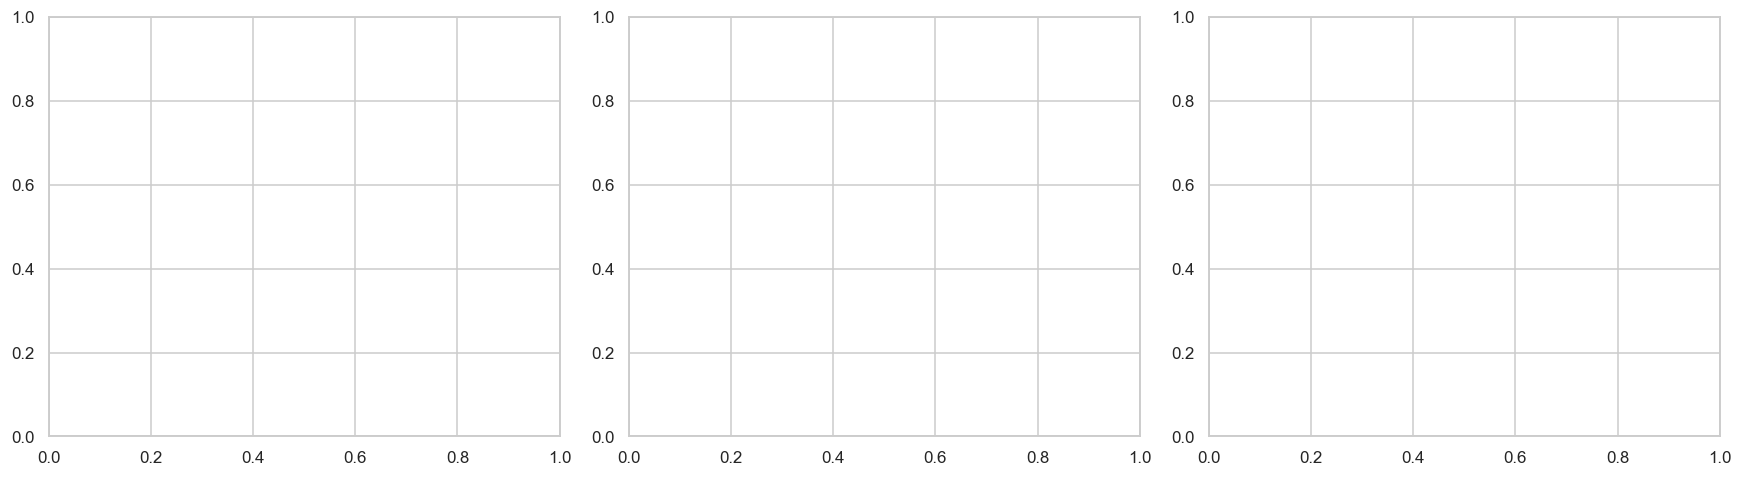

Interpretation guide: |d| 0.2 small, 0.5 medium, 0.8 large  |  |Cliff delta| 0.147 small, 0.33 medium, 0.474 large


In [30]:
def two_sample(d, col, flag, label_1, label_0, B=5000):
    a = d.loc[d[flag] == 1, col].dropna(); b = d.loc[d[flag] == 0, col].dropna()
    lev = stats.levene(a, b, center='median')
    t = stats.ttest_ind(a, b, equal_var=False); mw = stats.mannwhitneyu(a, b, alternative='two-sided')
    diff = a.mean() - b.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    dfw = se**4 / ((a.var(ddof=1) / len(a))**2 / (len(a) - 1) + (b.var(ddof=1) / len(b))**2 / (len(b) - 1))
    ci = (diff - stats.t.ppf(.975, dfw) * se, diff + stats.t.ppf(.975, dfw) * se)
    return {'metric': col, f'n {label_1}': len(a), f'n {label_0}': len(b), f'mean {label_1}': a.mean(), f'mean {label_0}': b.mean(),
            'diff': diff, '95% CI diff': f'[{ci[0]:.3f}, {ci[1]:.3f}]', "Cohen's d": cohen_d(a, b), "Cliff's delta": cliffs_delta(a, b),
            'Levene p': lev.pvalue, 'Welch p': t.pvalue, 'Mann-Whitney p': mw.pvalue}
res = pd.DataFrame([two_sample(fin, c, 'is_english', 'EN', 'nonEN') for c in ['log_revenue', 'log_roi', 'log_budget']]).set_index('metric')
display(res.style.format({'mean EN': '{:.2f}', 'mean nonEN': '{:.2f}', 'diff': '{:.3f}', "Cohen's d": '{:.2f}', "Cliff's delta": '{:.2f}',
                          'Levene p': '{:.1e}', 'Welch p': '{:.1e}', 'Mann-Whitney p': '{:.1e}'}))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a_, c, t in zip(ax, ['log_revenue', 'log_roi', 'log_budget'], ['ln(revenue)', 'ln(ROI)', 'ln(budget)']):
    sns.violinplot(data=fin, x=fin.is_english.map({1: 'English', 0: 'Non-English'}), y=c, ax=a, palette=['#C44E52', '#4C72B0'], cut=0, inner='quartile')
    a.set_title(t); a.set_xlabel('')
plt.tight_layout()
plt.show()
print('Interpretation guide: |d| 0.2 small, 0.5 medium, 0.8 large  |  |Cliff delta| 0.147 small, 0.33 medium, 0.474 large')

**Reading the result.** English-language films have a higher revenue *and* a different budget profile. The raw revenue gap is mostly a **budget gap** (English-language films are made with bigger budgets for bigger markets). Looking at ROI, which normalises for budget, shows how much of the advantage is genuinely "return" vs "scale". This is exactly why Section 7.6 uses regression to separate the two.

### 7.3 Multi-group comparison: release window (H3)
Five release windows -> one-way ANOVA (Welch version, robust to unequal variances), Kruskal-Wallis (rank-based), then **Tukey HSD** post-hoc, which controls the family-wise error rate across all 10 pairwise comparisons.

log_roi      Welch ANOVA F=6.71, p=2.31e-05 | Kruskal H=40.3, p=3.68e-08 | epsilon^2=0.0088
log_revenue  Welch ANOVA F=24.24, p=1.36e-19 | Kruskal H=124.5, p=5.75e-26 | epsilon^2=0.0272

(epsilon^2 < 0.01 negligible, 0.01-0.06 small, 0.06-0.14 medium, >0.14 large)


,group1,group2,meandiff,p-adj,lower,upper,reject
0,Fall,Holiday,0.656,0.000,0.424,0.889,True
1,Fall,Spring,0.329,0.004,0.074,0.584,True
2,Fall,Summer,0.647,0.000,0.438,0.857,True
3,Fall,Winter,0.187,0.311,-0.080,0.454,False
4,Holiday,Spring,-0.328,0.003,-0.578,-0.077,True
5,Holiday,Summer,-0.009,1.000,-0.213,0.195,False
6,Holiday,Winter,-0.469,0.000,-0.732,-0.207,True
7,Spring,Summer,0.318,0.001,0.090,0.547,True
8,Spring,Winter,-0.142,0.646,-0.425,0.141,False
9,Summer,Winter,-0.461,0.000,-0.702,-0.218,True


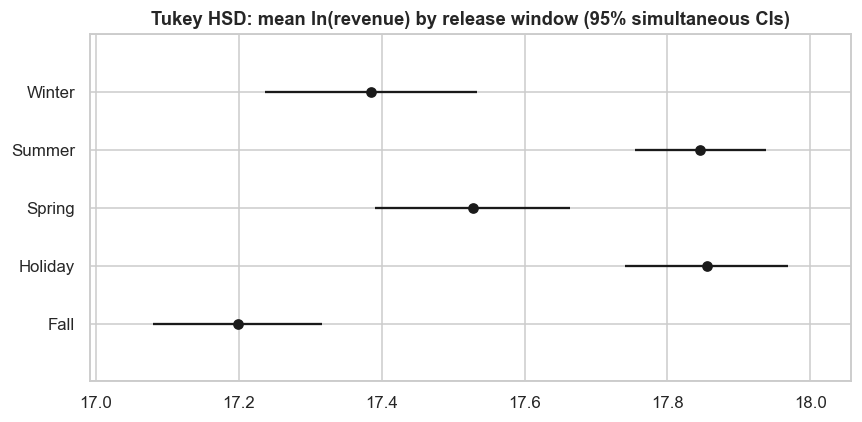

In [31]:
season_order = ['Winter', 'Spring', 'Summer', 'Fall', 'Holiday']
for col in ['log_roi', 'log_revenue']:
    groups = [fin.loc[fin.season_short == s, col].dropna().values for s in season_order]
    w = anova_oneway(groups, use_var='unequal', welch_correction=True)
    H, pk = stats.kruskal(*groups); N = sum(map(len, groups))
    print(f'{col:12s} Welch ANOVA F={w.statistic:.2f}, p={w.pvalue:.2e} | Kruskal H={H:.1f}, p={pk:.2e} | epsilon^2={epsilon_sq(H, N):.4f}')
print('\n(epsilon^2 < 0.01 negligible, 0.01-0.06 small, 0.06-0.14 medium, >0.14 large)')
tk = pairwise_tukeyhsd(fin.log_revenue, fin.season_short, alpha=.05)
display(pd.DataFrame(tk._results_table.data[1:], columns=tk._results_table.data[0]))
fig = tk.plot_simultaneous(figsize=(8, 4)); plt.title('Tukey HSD: mean ln(revenue) by release window (95% simultaneous CIs)'); plt.tight_layout(); savefig('20_tukey_season'); plt.show()

**Reading the result.** Release window shows statistically detectable differences in ln(revenue), but the effect size is small - consistent with window being partly a proxy for *which kinds of films studios schedule when* (tentpoles in summer, awards-bait in fall/holiday). Whether summer has a causal effect is tested properly in the A/B section.

### 7.4 Is ROI more variable for small films? (H2)
Levene / Brown-Forsythe tests whether *variance* differs across budget tiers. Financial intuition: low-budget films are lottery tickets (huge upside and downside), blockbusters are less dispersed in relative terms.

Brown-Forsythe test of equal ln(ROI) variance across budget tiers: W = 82.1, p = 2.07e-67


,n,median ln(ROI),SD,IQR
budget_tier,,,,
Micro (<$1M),183,2.320,2.210,3.000
Low ($1-10M),1082,1.270,1.670,1.900
Mid ($10-50M),2124,0.830,1.320,1.450
High ($50-150M),982,0.830,0.960,1.000
Blockbuster (>$150M),211,1.030,1.220,0.940


Spearman(ln budget, |ln ROI - median|) = -0.291, p = 2.2e-90  -> dispersion falls with budget


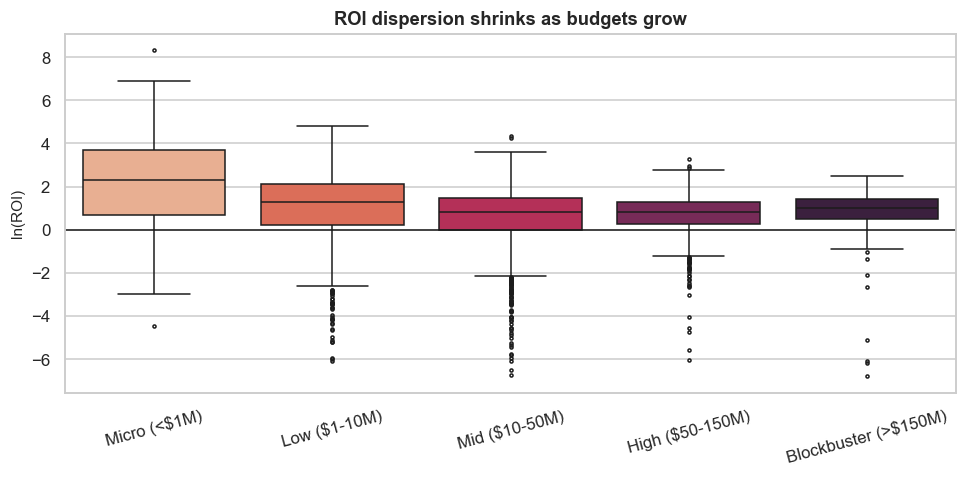

In [32]:
tiers = [fin.loc[fin.budget_tier == t, 'log_roi'].values for t in fin.budget_tier.cat.categories]
bf = stats.levene(*tiers, center='median')
print(f'Brown-Forsythe test of equal ln(ROI) variance across budget tiers: W = {bf.statistic:.1f}, p = {bf.pvalue:.2e}')
tier_stats = fin.groupby('budget_tier', observed=True).log_roi.agg(['size', 'median', 'std', lambda s: s.quantile(.75) - s.quantile(.25)])
tier_stats.columns = ['n', 'median ln(ROI)', 'SD', 'IQR']
display(tier_stats.round(2))
# Spearman between budget and absolute deviation from median ROI => dispersion trend
d_ = (fin.log_roi - fin.log_roi.median()).abs()
rho, p = stats.spearmanr(fin.log_budget, d_)
print(f'Spearman(ln budget, |ln ROI - median|) = {rho:.3f}, p = {p:.1e}  -> dispersion {"falls" if rho < 0 else "rises"} with budget')
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=fin, x='budget_tier', y='log_roi', ax=ax, palette='rocket_r', fliersize=2)
ax.axhline(0, c='k', lw=1); ax.set_xlabel(''); ax.set_ylabel('ln(ROI)'); ax.set_title('ROI dispersion shrinks as budgets grow')
plt.xticks(rotation=15); plt.tight_layout()
plt.show()

### 7.5 Tests of association: chi-square (categorical x categorical)
Is "hit / not hit" independent of budget tier and of release window? I report Cramér's V (effect size) and **standardised residuals** (|z| > 2 marks the cells driving the association).

hit x budget_tier: chi2(4) = 57.6, p = 9.22e-12, Cramer's V = 0.112
hit x season_short: chi2(4) = 46.0, p = 2.46e-09, Cramer's V = 0.100


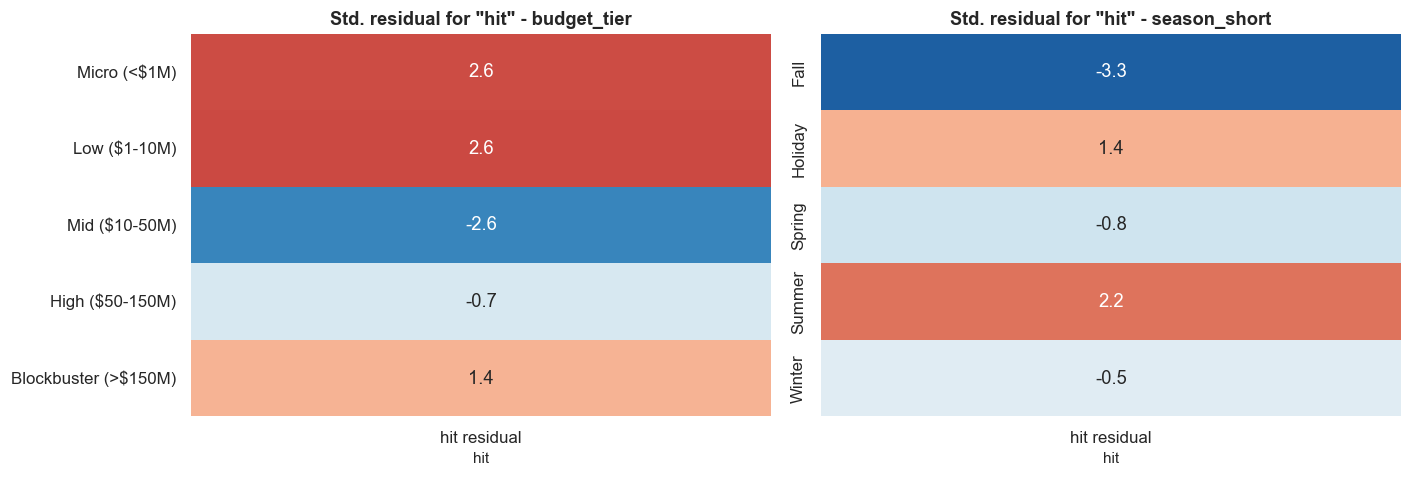

In [33]:
def chi_block(d, row, col='hit'):
    ct = pd.crosstab(d[row], d[col])
    chi2, p, dof, exp = stats.chi2_contingency(ct)
    v = cramers_v(chi2, ct.values.sum(), *ct.shape)
    resid = (ct - exp) / np.sqrt(exp)
    return ct, chi2, p, dof, v, resid
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a_, row in zip(ax, ['budget_tier', 'season_short']):
    ct, chi2, p, dof, v, resid = chi_block(fin, row)
    print(f'hit x {row}: chi2({dof}) = {chi2:.1f}, p = {p:.2e}, Cramer\'s V = {v:.3f}')
    sns.heatmap(resid[[1.0]].rename(columns={1.0: 'hit residual'}), annot=True, fmt='.1f', cmap='RdBu_r', center=0, vmin=-4, vmax=4, ax=a_, cbar=False)
    a_.set_title(f'Std. residual for "hit" - {row}'); a_.set_ylabel('')
plt.tight_layout()
plt.show()

### 7.6 Multivariable regression: what drives ln(revenue) once everything is held constant?
A log-log OLS: the coefficient on `ln(budget)` is an **elasticity** (a 1% higher budget is associated with a b% higher revenue). Standard errors are **heteroskedasticity-robust (HC3)** because diagnostics (below) show non-constant residual variance. Genres are not mutually exclusive, so all can be included without a dummy-variable trap.

n = 4,579   R2 = 0.490   adj R2 = 0.486   F-test p = 0.0e+00
Budget elasticity = 0.728  (95% CI 0.675 to 0.781)


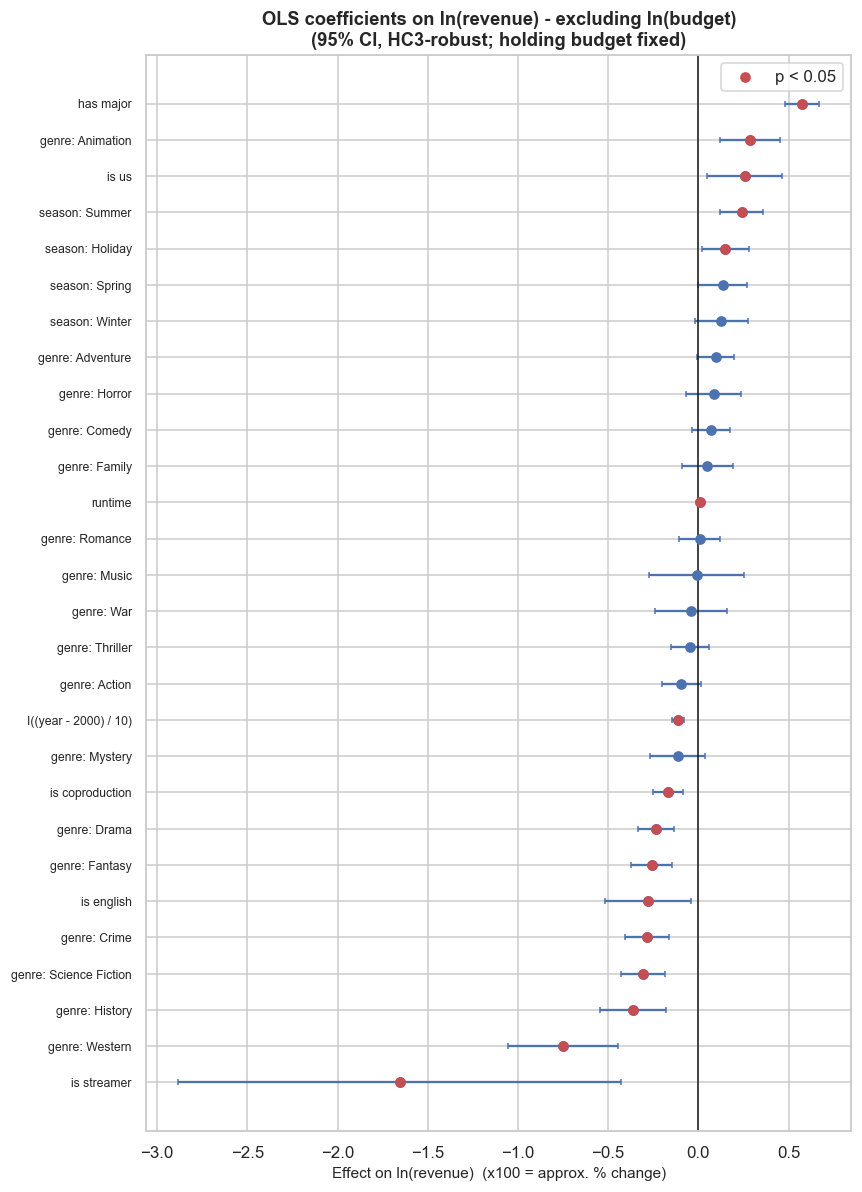

,coef,lo,hi,p
log budget,0.728,0.675,0.781,0.000
has major,0.575,0.480,0.670,0.000
runtime,0.011,0.008,0.013,0.000
I((year - 2000) / 10),-0.111,-0.144,-0.077,0.000
genre: Science Fiction,-0.308,-0.432,-0.184,0.000
genre: Western,-0.748,-1.053,-0.443,0.000
genre: Crime,-0.286,-0.406,-0.166,0.000
genre: Drama,-0.236,-0.337,-0.135,0.000
genre: Fantasy,-0.259,-0.372,-0.145,0.000
is coproduction,-0.168,-0.251,-0.085,0.000


In [34]:
genre_terms = ' + '.join(GCOLS_OK)
f_ols = ("log_revenue ~ log_budget + runtime + I((year-2000)/10) + C(season_short, Treatment('Fall')) + is_us + is_english"
         f" + has_major + is_streamer + is_coproduction + {genre_terms}")
ols = smf.ols(f_ols, data=fin).fit(cov_type='HC3')
print(f'n = {int(ols.nobs):,}   R2 = {ols.rsquared:.3f}   adj R2 = {ols.rsquared_adj:.3f}   F-test p = {ols.f_pvalue:.1e}')
print(f'Budget elasticity = {ols.params["log_budget"]:.3f}  (95% CI {ols.conf_int().loc["log_budget", 0]:.3f} to {ols.conf_int().loc["log_budget", 1]:.3f})')
coef = pd.DataFrame({'coef': ols.params, 'lo': ols.conf_int()[0], 'hi': ols.conf_int()[1], 'p': ols.pvalues}).drop('Intercept')
coef.index = (coef.index.str.replace(r"C\(season_short, Treatment\('Fall'\)\)\[T\.", 'season: ', regex=True).str.replace(']', '', regex=False)
              .str.replace('I((year-2000)/10)', 'per decade', regex=False).str.replace(r'^g_', 'genre: ', regex=True).str.replace('_', ' '))
others = coef.drop('log budget', errors='ignore')
fig, ax = plt.subplots(figsize=(8, 11))
cc = others.sort_values('coef'); y = np.arange(len(cc))
ax.errorbar(cc.coef, y, xerr=[cc.coef - cc.lo, cc.hi - cc.coef], fmt='o', color='#4C72B0', capsize=2)
ax.scatter(cc.coef[cc.p < .05], y[(cc.p < .05).values], color='#C44E52', zorder=5, label='p < 0.05')
ax.axvline(0, c='k', lw=1); ax.set_yticks(y); ax.set_yticklabels(cc.index, fontsize=8); ax.legend()
ax.set_title('OLS coefficients on ln(revenue) - excluding ln(budget)\n(95% CI, HC3-robust; holding budget fixed)'); ax.set_xlabel('Effect on ln(revenue)  (x100 = approx. % change)')
plt.tight_layout()
plt.show()
display(coef.sort_values('p').head(12).round(4))

**Regression diagnostics.** I verify the assumptions rather than assume them: residual-vs-fitted (linearity), Q-Q (normality of errors), scale-location (constant variance), Cook's distance (influential points), Breusch-Pagan (formal heteroskedasticity test) and VIF (multicollinearity).

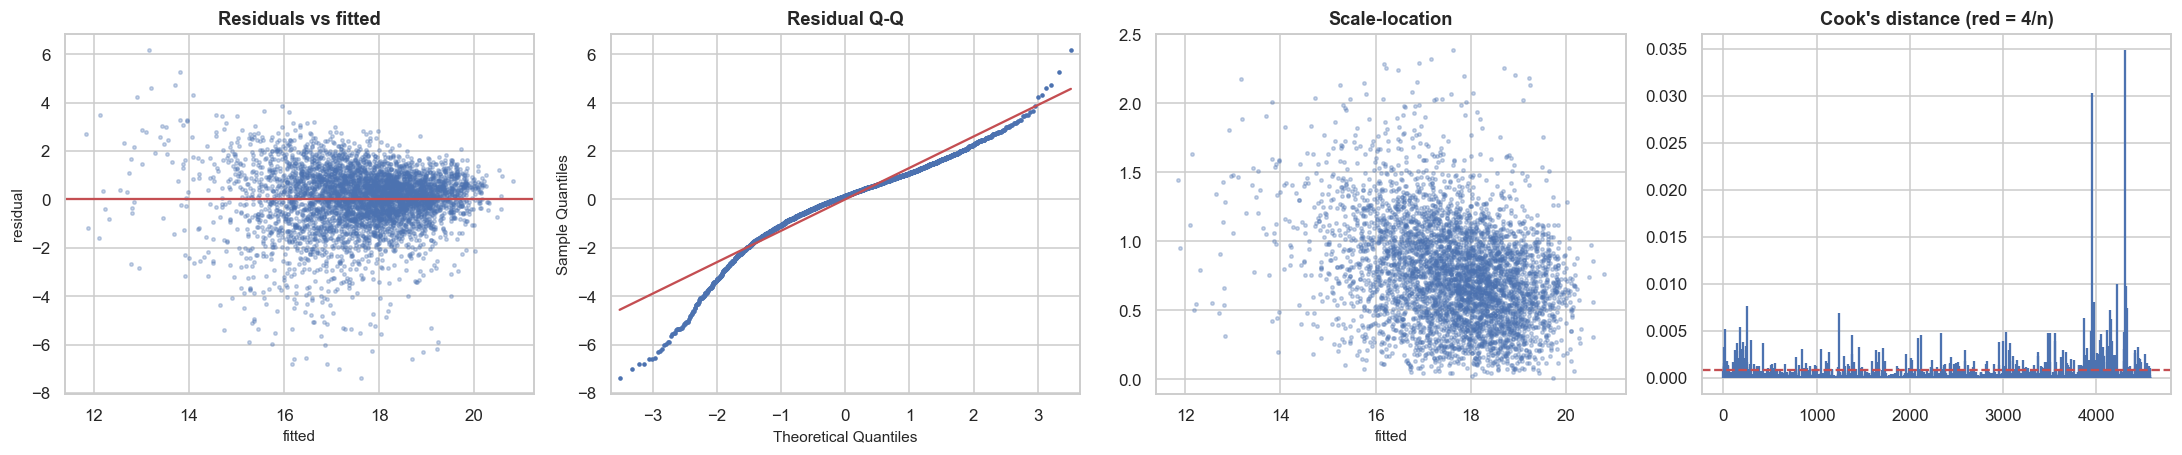

Breusch-Pagan LM p = 1.52e-54  -> heteroskedastic: robust (HC3) SEs justified
Observations with Cook's D > 4/n: 279 (6.1%)

Highest VIFs (rule of thumb: >5 concerning, >10 serious):
is_us                                          2.640
is_english                                     2.610
log_budget                                     2.350
g_Family                                       2.010
C(season_short, Treatment('Fall'))[T.Summer]   1.950
g_Animation                                    1.770


In [35]:
from statsmodels.stats.diagnostic import het_breuschpagan
ols_plain = smf.ols(f_ols, data=fin).fit()
infl = ols_plain.get_influence(); cooks = infl.cooks_distance[0]; fitted = ols_plain.fittedvalues; resid = ols_plain.resid
fig, ax = plt.subplots(1, 4, figsize=(20, 4.3))
ax[0].scatter(fitted, resid, s=5, alpha=.3); ax[0].axhline(0, c='r'); ax[0].set_title('Residuals vs fitted'); ax[0].set_xlabel('fitted'); ax[0].set_ylabel('residual')
sm.qqplot(resid, line='s', ax=ax[1], markersize=2); ax[1].set_title('Residual Q-Q')
ax[2].scatter(fitted, np.sqrt(np.abs(resid / resid.std())), s=5, alpha=.3); ax[2].set_title('Scale-location'); ax[2].set_xlabel('fitted')
ax[3].stem(np.arange(len(cooks)), cooks, markerfmt=' ', basefmt=' '); ax[3].axhline(4 / len(cooks), c='r', ls='--'); ax[3].set_title("Cook's distance (red = 4/n)")
plt.tight_layout() 
plt.show()
bp = het_breuschpagan(resid, ols_plain.model.exog)
print(f'Breusch-Pagan LM p = {bp[1]:.2e}  -> {"heteroskedastic: robust (HC3) SEs justified" if bp[1] < .05 else "no evidence of heteroskedasticity"}')
print(f'Observations with Cook\'s D > 4/n: {(cooks > 4 / len(cooks)).sum()} ({(cooks > 4 / len(cooks)).mean():.1%})')
X = ols_plain.model.exog; names = ols_plain.model.exog_names
vif = pd.Series([variance_inflation_factor(X, i) for i in range(1, X.shape[1])], index=names[1:]).sort_values(ascending=False)
print('\nHighest VIFs (rule of thumb: >5 concerning, >10 serious):'); print(vif.head(6).round(2).to_string())

### 7.7 Logistic regression: what shifts the odds of a hit?
Odds ratios (OR) are reported per doubling of budget, per extra 10 minutes of runtime, etc. OR > 1 raises the odds of a hit **holding the other variables fixed**.

n = 4,579 | McFadden pseudo-R2 = 0.082 | LR-test p = 3.0e-88


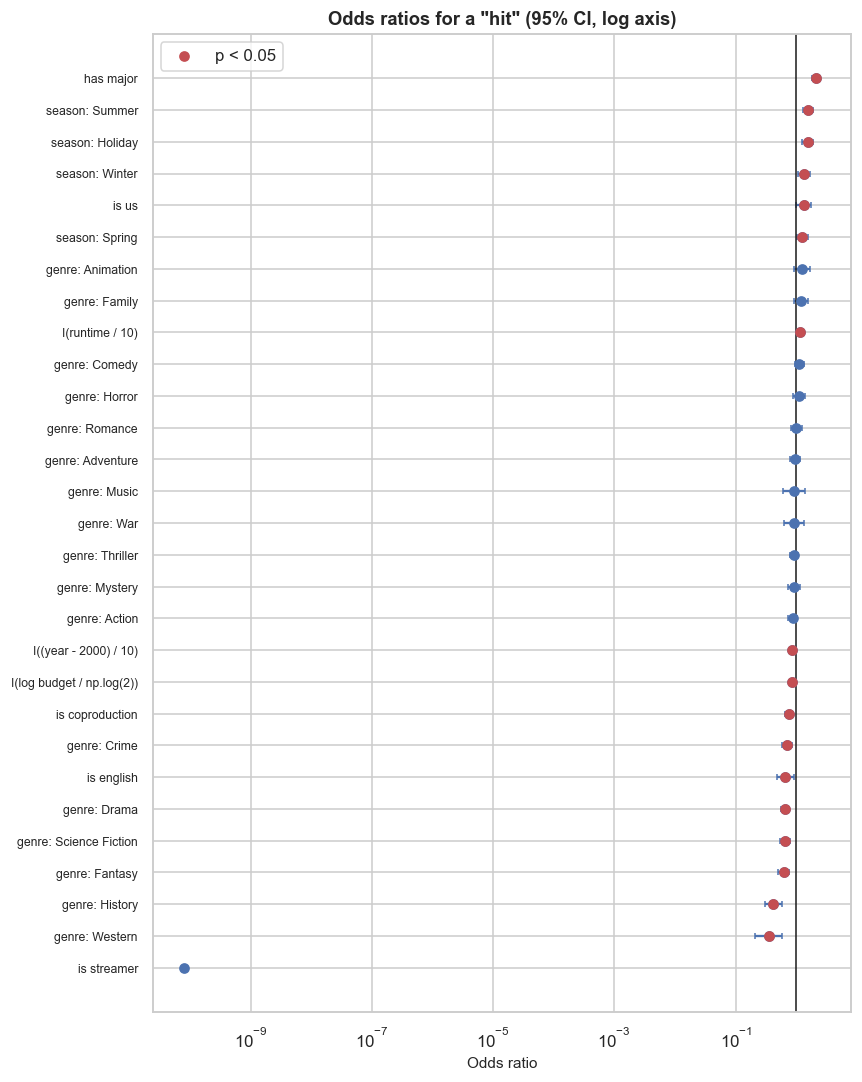

,OR,lo,hi,p
has major,2.079,1.781,2.425,0.000
I(runtime / 10),1.166,1.121,1.213,0.000
I(log budget / np.log(2)),0.857,0.818,0.899,0.000
I((year - 2000) / 10),0.859,0.817,0.903,0.000
genre: History,0.420,0.308,0.574,0.000
genre: Drama,0.652,0.552,0.770,0.000
genre: Fantasy,0.617,0.506,0.751,0.000
season: Summer,1.554,1.295,1.864,0.000


In [36]:
f_logit = ("hit ~ I(log_budget/np.log(2)) + I(runtime/10) + I((year-2000)/10) + C(season_short, Treatment('Fall')) + is_us + is_english"
           f" + has_major + is_streamer + is_coproduction + {genre_terms}")
lg_m = smf.logit(f_logit, data=fin).fit(disp=0)
orr = pd.DataFrame({'OR': np.exp(lg_m.params), 'lo': np.exp(lg_m.conf_int()[0]), 'hi': np.exp(lg_m.conf_int()[1]), 'p': lg_m.pvalues}).drop('Intercept')
orr.index = (orr.index.str.replace(r"C\(season_short, Treatment\('Fall'\)\)\[T\.", 'season: ', regex=True).str.replace(']', '', regex=False)
             .str.replace('I(log_budget/np.log(2))', 'budget (per doubling)', regex=False).str.replace('I(runtime/10)', 'runtime (per 10 min)', regex=False)
             .str.replace('I((year-2000)/10)', 'per decade', regex=False).str.replace(r'^g_', 'genre: ', regex=True).str.replace('_', ' '))
print(f'n = {int(lg_m.nobs):,} | McFadden pseudo-R2 = {lg_m.prsquared:.3f} | LR-test p = {lg_m.llr_pvalue:.1e}')
oo = orr.sort_values('OR'); y = np.arange(len(oo))
fig, ax = plt.subplots(figsize=(8, 10))
ax.errorbar(oo.OR, y, xerr=[oo.OR - oo.lo, oo.hi - oo.OR], fmt='o', capsize=2, color='#4C72B0')
ax.scatter(oo.OR[oo.p < .05], y[(oo.p < .05).values], color='#C44E52', zorder=5, label='p < 0.05')
ax.axvline(1, c='k', lw=1); ax.set_xscale('log'); ax.set_yticks(y); ax.set_yticklabels(oo.index, fontsize=8); ax.legend()
ax.set_title('Odds ratios for a "hit" (95% CI, log axis)'); ax.set_xlabel('Odds ratio')
plt.tight_layout()
plt.show()
display(orr.sort_values('p').head(8).round(3))

### 7.8 Statistical power: how big an effect can this dataset reliably detect?
A non-significant result is only informative if the test had the **power** to see a meaningful effect. Below: power curves for a two-sample t-test and the minimum detectable effect (MDE) at 80% power for the comparisons used in this project.

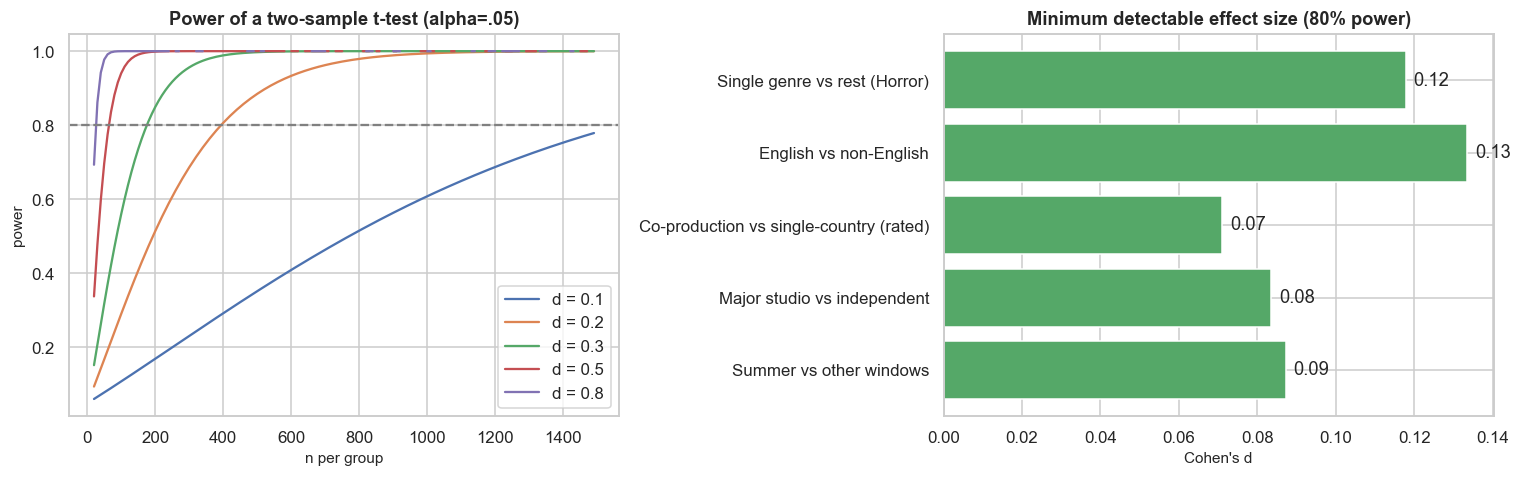

,n_A,n_B,MDE (Cohen d) @ 80% power
Summer vs other windows,1566,3016,0.087
Major studio vs independent,2595,1987,0.084
Co-production vs single-country (rated),2234,5086,0.071
English vs non-English,4089,493,0.134
Single genre vs rest (Horror),661,3921,0.118


In [37]:
pw = TTestIndPower()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ns = np.arange(20, 1500, 10)
for d_ in [.1, .2, .3, .5, .8]:
    ax[0].plot(ns, [pw.power(effect_size=d_, nobs1=n_, alpha=.05, ratio=1) for n_ in ns], label=f'd = {d_}')
ax[0].axhline(.8, c='gray', ls='--'); ax[0].set_xlabel('n per group'); ax[0].set_ylabel('power'); ax[0].legend(); ax[0].set_title('Power of a two-sample t-test (alpha=.05)')
comps = {'Summer vs other windows': (fin.is_summer.sum(), (1 - fin.is_summer).sum()), 'Major studio vs independent': (fin.has_major.sum(), (1 - fin.has_major).sum()),
         'Co-production vs single-country (rated)': (rated.is_coproduction.sum(), (1 - rated.is_coproduction).sum()), 'English vs non-English': (fin.is_english.sum(), (1 - fin.is_english).sum()),
         'Single genre vs rest (Horror)': (fin.g_Horror.sum(), (1 - fin.g_Horror).sum())}
mde = {k: pw.solve_power(effect_size=None, nobs1=a, ratio=b / a, alpha=.05, power=.8) for k, (a, b) in comps.items()}
mde_df = pd.DataFrame({'n_A': {k: v[0] for k, v in comps.items()}, 'n_B': {k: v[1] for k, v in comps.items()}, 'MDE (Cohen d) @ 80% power': mde})
ax[1].barh(list(mde), list(mde.values()), color='#55A868'); ax[1].set_title('Minimum detectable effect size (80% power)'); ax[1].set_xlabel("Cohen's d")
for i, v in enumerate(mde.values()): ax[1].text(v + .002, i, f'{v:.2f}', va='center')
plt.tight_layout()
plt.show()
mde_df.round(3)

## 8. Multiple Hypothesis Testing

### 8.1 The problem
Section 7 ran a handful of tests. Real analytics work often asks *"which of these 17 genres is special?"* - which means 17 (or 34, with two outcomes) simultaneous tests. If every null hypothesis were true and each test used alpha = 0.05, the chance of **at least one false discovery** is `1 - 0.95^m`: 58% for m = 17, 82% for m = 34. A report that highlights whichever genres have p < 0.05 would be mostly noise.

Two error rates matter:
* **FWER** (family-wise error rate): P(at least one false positive). Controlled by **Bonferroni** (p x m) and **Holm** (step-down, uniformly more powerful than Bonferroni). Use when a single false claim is costly.
* **FDR** (false discovery rate): expected *proportion* of false positives among discoveries. Controlled by **Benjamini-Hochberg (BH)**, and **Benjamini-Yekutieli (BY)** under arbitrary dependence. Use for exploratory screening where some false leads are acceptable.

#### Simulation: how bad is it, and how much do the corrections help?
Scenario A: 20 tests, **all nulls true**. Scenario B: 20 tests, **5 real effects** (standardised effect = 3).

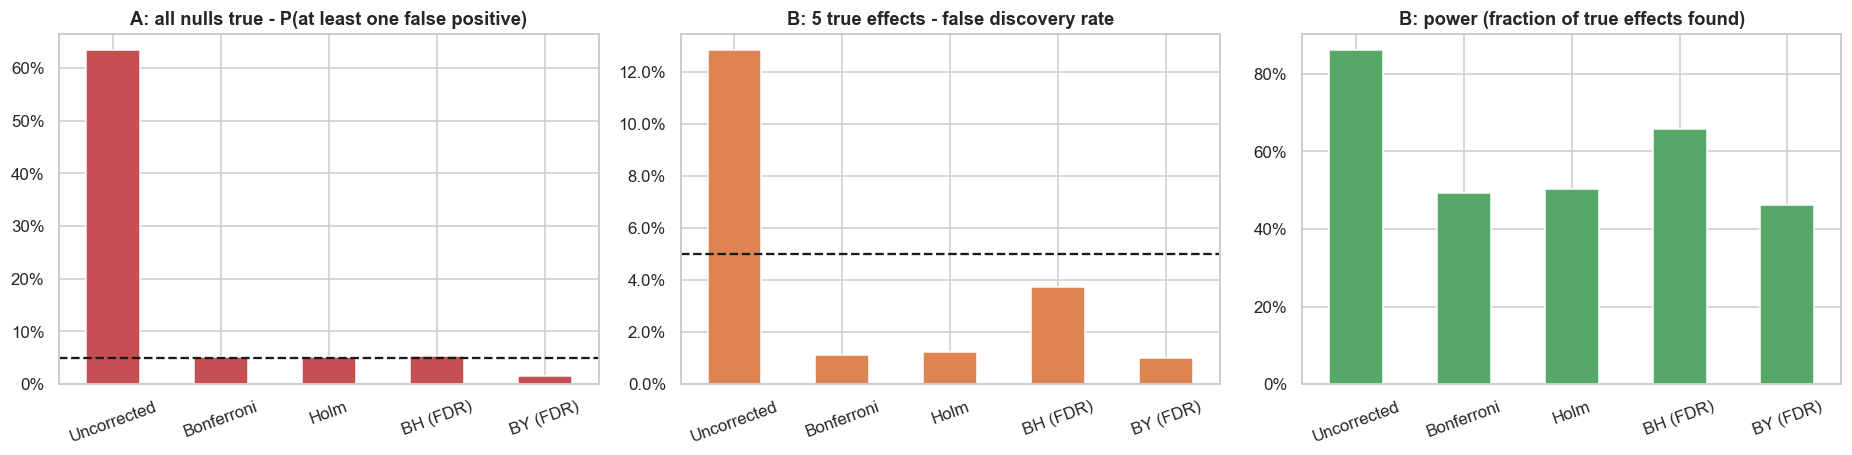

P(>=1 false positive)  False discovery rate  Power (true effects found)
A (all null)     Uncorrected                  0.633                 0.633                         NaN
                 Bonferroni                   0.050                 0.050                         NaN
                 Holm                         0.050                 0.050                         NaN
                 BH (FDR)                     0.052                 0.052                         NaN
                 BY (FDR)                     0.016                 0.016                         NaN
B (5 of 20 real) Uncorrected                  0.529                 0.128                       0.861
                 Bonferroni                   0.036                 0.011                       0.492
                 Holm                         0.042                 0.012                       0.504
                 BH (FDR)                     0.158                 0.037                       0.657
                 BY (FDR)                     0.038                 0.010                       0.461

In [38]:
def simulate(m=20, m_true=0, effect=3.0, reps=2000, alpha=.05):
    methods = {'Uncorrected': None, 'Bonferroni': 'bonferroni', 'Holm': 'holm', 'BH (FDR)': 'fdr_bh', 'BY (FDR)': 'fdr_by'}
    acc = {k: {'any_fp': 0, 'fdr': [], 'power': []} for k in methods}
    for _ in range(reps):
        z = rng.normal(size=m); z[:m_true] += effect
        p = 2 * stats.norm.sf(np.abs(z)); truth = np.arange(m) < m_true
        for k, meth in methods.items():
            rej = p < alpha if meth is None else multipletests(p, alpha=alpha, method=meth)[0]
            fp = (rej & ~truth).sum(); tp = (rej & truth).sum()
            acc[k]['any_fp'] += fp > 0
            acc[k]['fdr'].append(fp / max(rej.sum(), 1))
            if m_true: acc[k]['power'].append(tp / m_true)
    return pd.DataFrame({k: {'P(>=1 false positive)': v['any_fp'] / reps, 'False discovery rate': np.mean(v['fdr']),
                             'Power (true effects found)': np.mean(v['power']) if m_true else np.nan} for k, v in acc.items()}).T
simA = simulate(m=20, m_true=0); simB = simulate(m=20, m_true=5)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
simA['P(>=1 false positive)'].plot.bar(ax=ax[0], color='#C44E52'); ax[0].axhline(.05, c='k', ls='--'); ax[0].set_title('A: all nulls true - P(at least one false positive)')
simB['False discovery rate'].plot.bar(ax=ax[1], color='#DD8452'); ax[1].axhline(.05, c='k', ls='--'); ax[1].set_title('B: 5 true effects - false discovery rate')
simB['Power (true effects found)'].plot.bar(ax=ax[2], color='#55A868'); ax[2].set_title('B: power (fraction of true effects found)')
for a_ in ax: a_.tick_params(axis='x', rotation=20); a_.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.tight_layout()
plt.show()
display(pd.concat({'A (all null)': simA, 'B (5 of 20 real)': simB}).round(3))

**Takeaway.** Uncorrected testing produces a false positive in ~64% of "all-null" families. Bonferroni/Holm hold that at ~5% but lose power; BH keeps the *proportion* of false leads near 5% while retaining notably more power. That power/error trade-off is exactly what I now apply to real data.

### 8.2 Placebo check on the real data
I generate 40 **meaningless** binary features (random coin flips) and test each against ln(ROI). Any "significant" result is by construction a false positive.

In [39]:
placebo_p = []
y_ = fin.log_roi.values
for _ in range(40):
    flag = rng.integers(0, 2, len(fin)).astype(bool)
    placebo_p.append(stats.mannwhitneyu(y_[flag], y_[~flag]).pvalue)
placebo_p = np.array(placebo_p)
print(f'Placebo features significant at raw p<0.05 : {(placebo_p < .05).sum()} of 40  (expected about {0.05 * 40:.0f})')
for m in ['bonferroni', 'holm', 'fdr_bh']:
    print(f'   after {m:10s}: {multipletests(placebo_p, method=m)[0].sum()} significant')

Placebo features significant at raw p<0.05 : 1 of 40  (expected about 2)
   after bonferroni: 0 significant
   after holm      : 0 significant
   after fdr_bh    : 0 significant


### 8.3 Genre tests on real data: 17 genres x 2 outcomes = 34 tests
For each genre: *"Is this genre's distribution different from all other films?"* on (a) **ln(ROI)** in the financial sample and (b) **audience rating** in the rated sample. Mann-Whitney U (rank-based, no normality assumption) with **Cliff's delta** as effect size.

In [40]:
def genre_vs_rest(d, outcome, genres, min_n=30):
    rows = []
    for g in genres:
        flag = d[GENRE_COLS[g]] == 1
        a, b = d.loc[flag, outcome].dropna(), d.loc[~flag, outcome].dropna()
        if len(a) < min_n: continue
        mw = stats.mannwhitneyu(a, b, alternative='two-sided')
        rows.append({'genre': g, 'outcome': outcome, 'n_genre': len(a), 'median_genre': a.median(), 'median_rest': b.median(),
                     'cliffs_delta': cliffs_delta(a, b), 'p_raw': mw.pvalue})
    return pd.DataFrame(rows)

fam = pd.concat([genre_vs_rest(fin, 'log_roi', GENRES_OK), genre_vs_rest(rated, 'vote_average', GENRES_OK)], ignore_index=True)
m = len(fam)
for meth, col in [('bonferroni', 'p_bonf'), ('holm', 'p_holm'), ('fdr_bh', 'p_bh'), ('fdr_by', 'p_by')]:
    fam[col] = multipletests(fam.p_raw, method=meth)[1]
fam['sig_raw'] = fam.p_raw < .05; fam['sig_bonf'] = fam.p_bonf < .05; fam['sig_holm'] = fam.p_holm < .05; fam['sig_bh'] = fam.p_bh < .05; fam['sig_by'] = fam.p_by < .05
print(f'Family size m = {m} tests. Probability of >=1 false positive if all null & uncorrected: {1 - .95**m:.0%}')
summ = fam[['sig_raw', 'sig_bonf', 'sig_holm', 'sig_bh', 'sig_by']].sum().rename({'sig_raw': 'Uncorrected', 'sig_bonf': 'Bonferroni', 'sig_holm': 'Holm', 'sig_bh': 'BH (FDR 5%)', 'sig_by': 'BY (FDR 5%)'})
display(summ.to_frame('# "significant" of ' + str(m)).T)
show = fam.sort_values('p_raw')[['genre', 'outcome', 'n_genre', 'median_genre', 'median_rest', 'cliffs_delta', 'p_raw', 'p_holm', 'p_bh', 'sig_raw', 'sig_holm', 'sig_bh']]
display(show.style.format({'median_genre': '{:.2f}', 'median_rest': '{:.2f}', 'cliffs_delta': '{:.2f}', 'p_raw': '{:.1e}', 'p_holm': '{:.1e}', 'p_bh': '{:.1e}'})
        .background_gradient(subset=['cliffs_delta'], cmap='RdBu_r', vmin=-.4, vmax=.4))

Family size m = 34 tests. Probability of >=1 false positive if all null & uncorrected: 83%


,Uncorrected,Bonferroni,Holm,BH (FDR 5%),BY (FDR 5%)
"# ""significant"" of 34",27,22,23,26,23


,genre,outcome,n_genre,median_genre,median_rest,cliffs_delta,p_raw,p_holm,p_bh,sig_raw,sig_holm,sig_bh
17,Drama,vote_average,2945,7.00,6.50,0.32,6.5e-118,2.2e-116,2.2e-116,True,True,True
23,Horror,vote_average,1131,6.27,6.80,-0.38,8.2e-90,2.7e-88,1.4e-88,True,True,True
28,Animation,vote_average,930,7.10,6.64,0.33,7.1e-61,2.3e-59,8.0e-60,True,True,True
20,Thriller,vote_average,2064,6.50,6.80,-0.20,4.1e-41,1.3e-39,3.5e-40,True,True,True
30,History,vote_average,359,7.12,6.70,0.32,2.7e-24,8.2e-23,1.8e-23,True,True,True
19,Action,vote_average,2238,6.56,6.78,-0.14,9.4e-22,2.7e-20,5.3e-21,True,True,True
31,War,vote_average,237,7.12,6.70,0.26,4.5e-12,1.3e-10,2.2e-11,True,True,True
2,Action,log_roi,1437,0.82,1.00,-0.12,4.3e-11,1.2e-09,1.8e-10,True,True,True
18,Comedy,vote_average,2196,6.60,6.74,-0.10,1.1e-10,2.9e-09,4.2e-10,True,True,True
26,Science Fiction,vote_average,1055,6.56,6.71,-0.12,1.4e-10,3.5e-09,4.8e-10,True,True,True


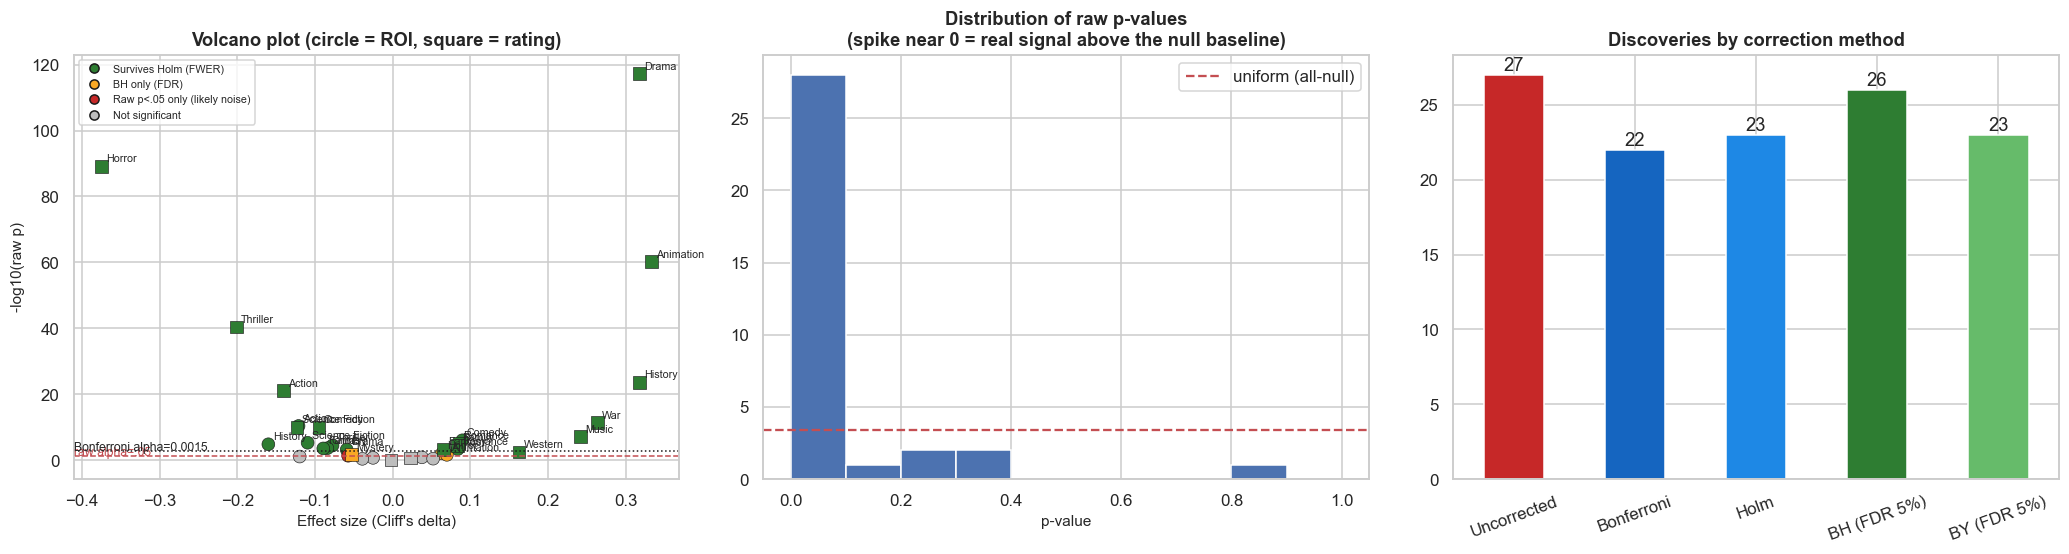

In [41]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))
def cat(r):
    return ('Survives Holm (FWER)' if r.sig_holm else 'BH only (FDR)' if r.sig_bh else 'Raw p<.05 only (likely noise)' if r.sig_raw else 'Not significant')
fam['category'] = fam.apply(cat, axis=1)
palette = {'Survives Holm (FWER)': '#2E7D32', 'BH only (FDR)': '#F9A825', 'Raw p<.05 only (likely noise)': '#C62828', 'Not significant': '#BDBDBD'}
for o, mk in [('log_roi', 'o'), ('vote_average', 's')]:
    sub = fam[fam.outcome == o]
    ax[0].scatter(sub.cliffs_delta, -np.log10(sub.p_raw), c=sub.category.map(palette), marker=mk, s=70, edgecolor='k', lw=.4, label=o)
for _, r in fam[fam.sig_bh].iterrows(): ax[0].annotate(r.genre, (r.cliffs_delta, -np.log10(r.p_raw)), fontsize=7, xytext=(3, 3), textcoords='offset points')
ax[0].axhline(-np.log10(.05), c='r', ls='--', lw=1); ax[0].text(ax[0].get_xlim()[0], -np.log10(.05) + .1, 'raw alpha=.05', color='r', fontsize=8)
ax[0].axhline(-np.log10(.05 / m), c='k', ls=':', lw=1); ax[0].text(ax[0].get_xlim()[0], -np.log10(.05 / m) + .1, f'Bonferroni alpha={.05 / m:.4f}', fontsize=8)
ax[0].set_xlabel("Effect size (Cliff's delta)"); ax[0].set_ylabel('-log10(raw p)'); ax[0].set_title('Volcano plot (circle = ROI, square = rating)')
from matplotlib.lines import Line2D
ax[0].legend(handles=[Line2D([0], [0], marker='o', ls='', color=c, label=l, markeredgecolor='k') for l, c in palette.items()], fontsize=7, loc='upper left')
ax[1].hist(fam.p_raw, bins=np.linspace(0, 1, 11), color='#4C72B0', edgecolor='w'); ax[1].axhline(m / 10, c='r', ls='--', label='uniform (all-null)'); ax[1].legend()
ax[1].set_title('Distribution of raw p-values\n(spike near 0 = real signal above the null baseline)'); ax[1].set_xlabel('p-value')
summ.plot.bar(ax=ax[2], color=['#C62828', '#1565C0', '#1E88E5', '#2E7D32', '#66BB6A']); ax[2].set_title('Discoveries by correction method'); ax[2].tick_params(axis='x', rotation=20)
for i, v in enumerate(summ.values): ax[2].text(i, v + .3, int(v), ha='center')
plt.tight_layout()
plt.show()

### 8.4 Permutation-based max-T correction (Westfall-Young)
Bonferroni and Holm ignore that genres **overlap** (a film can be Action *and* Adventure), so tests are positively correlated and those methods are conservative. The permutation max-T procedure respects the dependence: shuffle the outcome, recompute **all** 17 genre t-statistics each time, record the **largest** |t|, and compare each observed |t| with that null distribution of maxima. This controls the FWER exactly under exchangeability.

,genre,Welch t,p_raw,p_Bonferroni,p_maxT (permutation)
2,Action,-6.62,3.5e-11,6.0e-10,0.0003
1,Comedy,4.69,2.7e-06,4.6e-05,0.0003
9,Science Fiction,-4.61,4.0e-06,6.8e-05,0.0003
7,Crime,-4.12,3.7e-05,6.3e-04,0.0013
3,Thriller,-3.99,6.7e-05,1.1e-03,0.0013
13,History,-3.67,2.5e-04,4.2e-03,0.0053
5,Romance,3.00,2.7e-03,4.6e-02,0.0490
8,Fantasy,-2.99,2.8e-03,4.7e-02,0.0497
0,Drama,-2.86,4.3e-03,7.2e-02,0.0700
6,Horror,2.65,8.0e-03,1.4e-01,0.1206


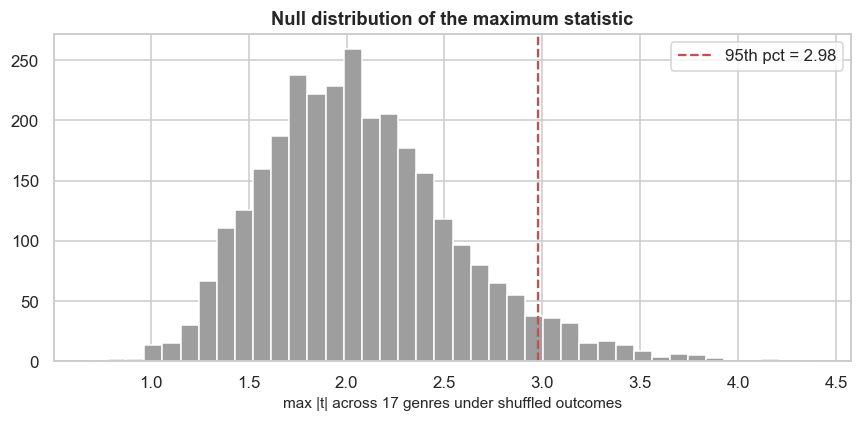

Genres with permutation-adjusted p<0.05: ['Action', 'Comedy', 'Science Fiction', 'Crime', 'Thriller', 'History', 'Romance', 'Fantasy']


In [42]:
def welch_t_all(y, G):
    n = len(y); n1 = G.sum(0); n0 = n - n1
    s1 = G.T @ y; s0 = y.sum() - s1; q1 = G.T @ (y ** 2); q0 = (y ** 2).sum() - q1
    m1, m0 = s1 / n1, s0 / n0
    v1 = (q1 - n1 * m1 ** 2) / (n1 - 1); v0 = (q0 - n0 * m0 ** 2) / (n0 - 1)
    return (m1 - m0) / np.sqrt(v1 / n1 + v0 / n0)

yy = fin.log_roi.values; Gm = fin[GCOLS_OK].values.astype(float)
t_obs = welch_t_all(yy, Gm)
B = 3000
max_null = np.empty(B)
for b in range(B):
    max_null[b] = np.abs(welch_t_all(rng.permutation(yy), Gm)).max()
p_maxT = (1 + (max_null[:, None] >= np.abs(t_obs)[None, :]).sum(0)) / (B + 1)
p_welch = 2 * stats.norm.sf(np.abs(t_obs))
maxt = pd.DataFrame({'genre': GENRES_OK, 'Welch t': t_obs, 'p_raw': p_welch,
                     'p_Bonferroni': np.minimum(p_welch * len(GENRES_OK), 1), 'p_maxT (permutation)': p_maxT}).sort_values('p_raw')
display(maxt.head(10).style.format({'Welch t': '{:.2f}', 'p_raw': '{:.1e}', 'p_Bonferroni': '{:.1e}', 'p_maxT (permutation)': '{:.4f}'}))
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(max_null, bins=40, color='#9E9E9E'); ax.axvline(np.percentile(max_null, 95), c='r', ls='--', label=f'95th pct = {np.percentile(max_null, 95):.2f}')
ax.set_xlabel('max |t| across 17 genres under shuffled outcomes'); ax.set_title('Null distribution of the maximum statistic'); ax.legend()
plt.tight_layout()
plt.show()
print(f'Genres with permutation-adjusted p<0.05: {maxt.loc[maxt["p_maxT (permutation)"] < .05, "genre"].tolist()}')

## 9. A/B Testing

### 9.1 Framework: experiments on observational data
In a true A/B test, units are **randomly assigned** to A or B, so any difference in outcomes can be attributed to the treatment. Films are not randomly assigned to release dates or studios, so what follows is a **quasi-experiment**: I use the full A/B toolkit (pre-registered hypothesis, power analysis, frequentist *and* Bayesian inference, A/A validation, guardrails), and then add the step a real randomised test would not need: **checking and correcting for confounding** (covariate balance, propensity-score matching, regression adjustment). The headline question is whether the effect survives that adjustment.

| Experiment | A (treatment) | B (control) | Primary metric | Secondary |
|---|---|---|---|---|
| **#1 Release window** | Summer (May-Aug) | All other months | Hit rate (>=2x) | ln(revenue), ROI |
| **#2 Studio backing** | Major-studio involvement | Independent | Hit rate | ln(revenue) |
| **#3 Co-production** | >=2 production countries | Single country | Audience rating | - |

**Decision protocol (fixed in advance):** two-sided alpha = 0.05; power target 80%; primary metric decides; an effect is "actionable" only if the **adjusted** estimate is significant (Holm-corrected across the 3 experiments) *and* practically meaningful.

#### Reusable A/B toolkit

In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

def ab_binary(y1, y0, B=200_000):
    """A/B test for a conversion-style (0/1) metric. Returns frequentist + Bayesian results."""
    y1, y0 = np.asarray(y1, float), np.asarray(y0, float)
    n1, n0, x1, x0 = len(y1), len(y0), int(y1.sum()), int(y0.sum()); p1, p0 = x1 / n1, x0 / n0
    z, p_z = proportions_ztest([x1, x0], [n1, n0])
    chi_p = stats.chi2_contingency([[x1, n1 - x1], [x0, n0 - x0]], correction=False)[1]
    lo, hi = confint_proportions_2indep(x1, n1, x0, n0, method='newcomb')
    X, N = x1 + x0, n1 + n0
    h = rng.hypergeometric(X, N - X, n1, size=20000)                     # exact permutation distribution of x1 under H0
    d_perm = h / n1 - (X - h) / n0; p_perm = (np.abs(d_perm) >= abs(p1 - p0) - 1e-12).mean()
    # Bayesian: Beta(1,1) priors
    a1, a0 = rng.beta(1 + x1, 1 + n1 - x1, B), rng.beta(1 + x0, 1 + n0 - x0, B)
    return {'n_A': n1, 'n_B': n0, 'rate_A': p1, 'rate_B': p0, 'abs_lift': p1 - p0, 'rel_lift': p1 / p0 - 1, 'CI_low': lo, 'CI_high': hi,
            'z': z, 'p_ztest': p_z, 'p_chi2': chi_p, 'p_perm': p_perm,
            'P(A>B)': (a1 > a0).mean(), 'bayes_CrI': np.percentile(a1 - a0, [2.5, 97.5]), 'E_lift_bayes': (a1 - a0).mean(),
            'odds_ratio': (p1 / (1 - p1)) / (p0 / (1 - p0))}

def ab_continuous(a, b, B=5000):
    a, b = np.asarray(a, float), np.asarray(b, float)
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    t = stats.ttest_ind(a, b, equal_var=False); mw = stats.mannwhitneyu(a, b)
    pool = np.concatenate([a, b]); obs = a.mean() - b.mean()
    perm = np.empty(5000)
    for i in range(5000):
        s = rng.permutation(pool); perm[i] = s[:len(a)].mean() - s[len(a):].mean()
    return {'n_A': len(a), 'n_B': len(b), 'mean_A': a.mean(), 'mean_B': b.mean(), 'diff': obs,
            'CI_boot': boot_diff_ci(a, b, np.mean, B=B), 'cohen_d': cohen_d(a, b), 'cliffs_delta': cliffs_delta(a, b),
            'p_welch': t.pvalue, 'p_mw': mw.pvalue, 'p_perm': (np.abs(perm) >= abs(obs)).mean()}

def smd(x1, x0, w0=None):
    m0 = np.average(x0, weights=w0); v0 = np.average((x0 - m0) ** 2, weights=w0) if w0 is not None else x0.var(ddof=1)
    return (x1.mean() - m0) / np.sqrt((x1.var(ddof=1) + v0) / 2 + 1e-12)

def psm(d, treat, covars, outcome, caliper_sd=.2, B=3000):
    """1-NN propensity-score matching (with replacement) on the logit of the PS, caliper = 0.2 SD. Returns ATT + balance."""
    d = d.dropna(subset=covars + [outcome, treat]).reset_index(drop=True)
    X = StandardScaler().fit_transform(d[covars]); t = d[treat].values.astype(int); y = d[outcome].values.astype(float)
    ps = LogisticRegression(max_iter=3000, C=1.0).fit(X, t).predict_proba(X)[:, 1]
    lps = np.log(ps / (1 - ps)); cal = caliper_sd * lps.std()
    tr, ct = np.where(t == 1)[0], np.where(t == 0)[0]
    dist, idx = NearestNeighbors(n_neighbors=1).fit(lps[ct].reshape(-1, 1)).kneighbors(lps[tr].reshape(-1, 1))
    ok = dist[:, 0] <= cal; mt, mc = tr[ok], ct[idx[ok, 0]]
    eff = y[mt] - y[mc]; att = eff.mean()
    boots = eff[rng.integers(0, len(eff), (B, len(eff)))].mean(1)
    p_boot = min(1, 2 * min((boots <= 0).mean(), (boots >= 0).mean()) + 1 / B)
    w = pd.Series(mc).value_counts()                                       # control weights (reuse counts)
    bal = []
    for c in covars:
        x = d[c].values.astype(float)
        bal.append({'covariate': c, 'SMD_before': smd(x[tr], x[ct]), 'SMD_after': smd(x[mt], x[w.index.values], w.values.astype(float))})
    return {'att': att, 'ci': np.percentile(boots, [2.5, 97.5]), 'p': p_boot, 'n_treated': len(tr), 'n_matched': int(ok.sum()),
            'n_unique_controls': len(w), 'balance': pd.DataFrame(bal).set_index('covariate'), 'ps': ps, 't': t}

def love_plot(bal, title, name):
    b = bal.reindex(bal.SMD_before.abs().sort_values().index)
    fig, ax = plt.subplots(figsize=(7, max(4, .27 * len(b))))
    y = np.arange(len(b))
    ax.scatter(b.SMD_before, y, c='#C44E52', label='Before matching', zorder=3); ax.scatter(b.SMD_after, y, c='#2E7D32', label='After matching', zorder=3)
    ax.hlines(y, b.SMD_before, b.SMD_after, color='gray', lw=.7)
    ax.axvline(0, c='k', lw=1); ax.axvspan(-.1, .1, color='green', alpha=.08, label='|SMD|<0.1 (balanced)')
    ax.set_yticks(y); ax.set_yticklabels([c.replace('g_', 'genre: ') for c in b.index], fontsize=8); ax.set_xlabel('Standardised mean difference'); ax.legend(fontsize=8); ax.set_title(title)
    plt.tight_layout(); savefig(name); plt.show()

ab_results = []      # collected for the summary table
print('A/B toolkit ready.')

A/B toolkit ready.


### 9.2 Validating the machinery: A/A tests and the "peeking" problem
Before trusting any A/B pipeline, run **A/A tests** (compare random halves of the *same* population). Because nothing differs, p-values should be uniform and ~5% should fall below 0.05. Then I demonstrate **peeking** - checking significance repeatedly as data accumulate and stopping at the first p<0.05 - which inflates false positives.

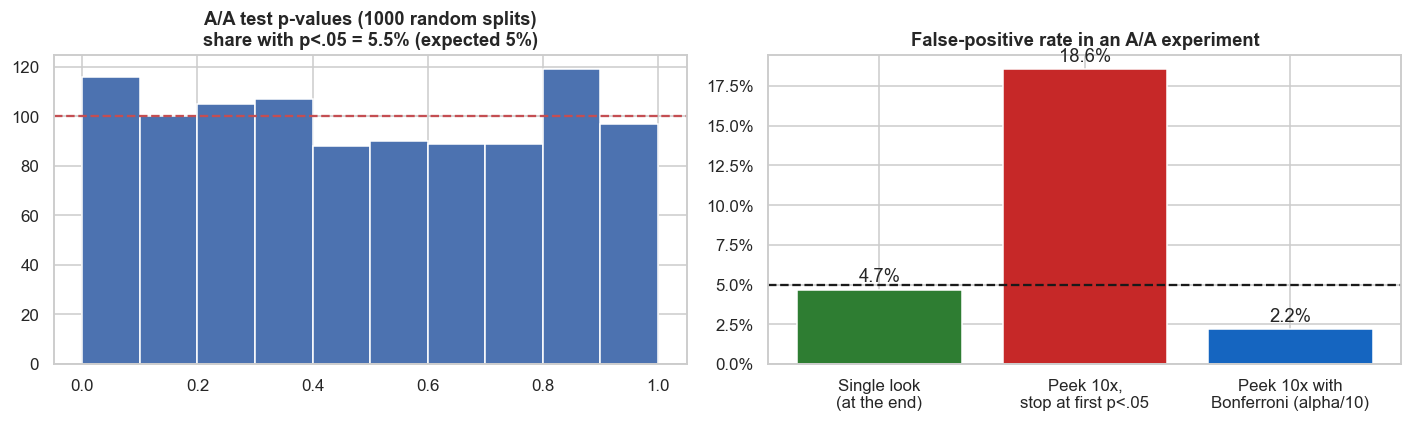

In [44]:
aa_p = []
hit_arr = fin.hit.values
for _ in range(1000):
    flag = rng.integers(0, 2, len(hit_arr)).astype(bool)
    aa_p.append(proportions_ztest([hit_arr[flag].sum(), hit_arr[~flag].sum()], [flag.sum(), (~flag).sum()])[1])
aa_p = np.array(aa_p)
# peeking: sequential looks at a true-null experiment (10 interim looks, 3000 users per arm)
looks = np.linspace(300, 3000, 10).astype(int); sims = 4000
A = rng.binomial(1, .6, (sims, 3000)); Bm = rng.binomial(1, .6, (sims, 3000))
cs_a, cs_b = A.cumsum(1), Bm.cumsum(1)
pk = []
for L in looks:
    pa, pb = cs_a[:, L - 1] / L, cs_b[:, L - 1] / L; pp = (pa + pb) / 2
    z = (pa - pb) / np.sqrt(2 * pp * (1 - pp) / L); pk.append(2 * stats.norm.sf(np.abs(z)))
pk = np.array(pk)
fp_peek = (pk < .05).any(0).mean(); fp_final = (pk[-1] < .05).mean(); fp_bonf = (pk < .05 / len(looks)).any(0).mean()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(aa_p, bins=np.linspace(0, 1, 11), color='#4C72B0', edgecolor='w'); ax[0].axhline(100, c='r', ls='--'); ax[0].set_title(f'A/A test p-values (1000 random splits)\nshare with p<.05 = {(aa_p < .05).mean():.1%} (expected 5%)')
ax[1].bar(['Single look\n(at the end)', 'Peek 10x,\nstop at first p<.05', 'Peek 10x with\nBonferroni (alpha/10)'], [fp_final, fp_peek, fp_bonf], color=['#2E7D32', '#C62828', '#1565C0'])
ax[1].axhline(.05, c='k', ls='--'); ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax[1].set_title('False-positive rate in an A/A experiment')
for i, v in enumerate([fp_final, fp_peek, fp_bonf]): ax[1].text(i, v + .005, f'{v:.1%}', ha='center')
plt.tight_layout()
plt.show()

### 9.3 Experiment #1 - Does a summer release help?
**H0:** summer and non-summer films have the same hit rate. **H1:** they differ. Summer is the studio-calendar "premium" window, so the business belief is that it lifts outcomes.

**Step 1 - Design & power.** What lift could we have detected?

In [45]:
fa = fin.copy()
A_, B_ = fa[fa.is_summer == 1], fa[fa.is_summer == 0]
p0 = B_.hit.mean(); npw = NormalIndPower()
mde_h = npw.solve_power(effect_size=None, nobs1=len(A_), ratio=len(B_) / len(A_), alpha=.05, power=.8)
# convert Cohen's h back to an absolute proportion difference
p_mde = np.sin((2 * np.arcsin(np.sqrt(p0)) + mde_h) / 2) ** 2
print(f'Sample: summer n={len(A_):,} vs other n={len(B_):,};  control hit rate = {p0:.1%}')
print(f'Minimum detectable effect at 80% power: Cohen h = {mde_h:.3f}  =>  about +{(p_mde - p0) * 100:.1f} percentage points in hit rate')

Sample: summer n=1,566 vs other n=3,016;  control hit rate = 57.7%
Minimum detectable effect at 80% power: Cohen h = 0.087  =>  about +4.3 percentage points in hit rate


**Step 2 - Naive A/B comparison (ignores confounding).**

Hit rate: Summer 64.1% vs Other 57.7%  |  lift = +6.4 pp  (95% CI +3.4 to +9.4 pp)  |  relative +11.1%  |  OR=1.31
z-test p=2.61e-05 | chi2 p=2.61e-05 | exact permutation p=0.0001
Bayesian: P(Summer better) = 100.0%; expected lift +6.4 pp; 95% credible interval [+3.4, +9.4] pp

Secondary - ln(revenue): Summer 17.85 vs Other 17.51; diff=0.338 (x1.40); bootstrap CI [0.23,0.45]; d=0.19; Welch p=3.3e-09, MW p=7.9e-12
Secondary - ln(ROI)    : Summer 0.95 vs Other 0.75; diff=0.192; d=0.14; Welch p=8.8e-06


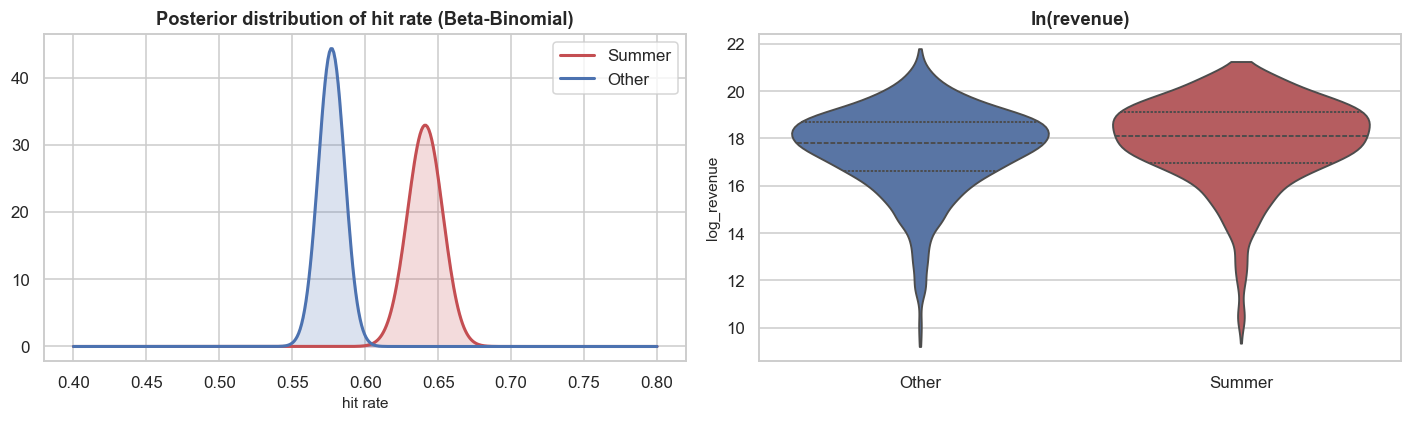

In [46]:
r1 = ab_binary(A_.hit, B_.hit)
print(f"Hit rate: Summer {r1['rate_A']:.1%} vs Other {r1['rate_B']:.1%}  |  lift = {r1['abs_lift'] * 100:+.1f} pp  (95% CI {r1['CI_low'] * 100:+.1f} to {r1['CI_high'] * 100:+.1f} pp)  |  relative {r1['rel_lift']:+.1%}  |  OR={r1['odds_ratio']:.2f}")
print(f"z-test p={r1['p_ztest']:.2e} | chi2 p={r1['p_chi2']:.2e} | exact permutation p={r1['p_perm']:.4f}")
print(f"Bayesian: P(Summer better) = {r1['P(A>B)']:.1%}; expected lift {r1['E_lift_bayes'] * 100:+.1f} pp; 95% credible interval [{r1['bayes_CrI'][0] * 100:+.1f}, {r1['bayes_CrI'][1] * 100:+.1f}] pp")
c1 = ab_continuous(A_.log_revenue, B_.log_revenue)
print(f"\nSecondary - ln(revenue): Summer {c1['mean_A']:.2f} vs Other {c1['mean_B']:.2f}; diff={c1['diff']:.3f} (x{np.exp(c1['diff']):.2f}); bootstrap CI [{c1['CI_boot'][0]:.2f},{c1['CI_boot'][1]:.2f}]; d={c1['cohen_d']:.2f}; Welch p={c1['p_welch']:.1e}, MW p={c1['p_mw']:.1e}")
c1r = ab_continuous(A_.log_roi, B_.log_roi)
print(f"Secondary - ln(ROI)    : Summer {c1r['mean_A']:.2f} vs Other {c1r['mean_B']:.2f}; diff={c1r['diff']:.3f}; d={c1r['cohen_d']:.2f}; Welch p={c1r['p_welch']:.1e}")
# posterior plot
x1, n1_, x0, n0_ = int(A_.hit.sum()), len(A_), int(B_.hit.sum()), len(B_)
grid = np.linspace(.4, .8, 400)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(grid, stats.beta.pdf(grid, 1 + x1, 1 + n1_ - x1), label='Summer', c='#C44E52', lw=2); ax[0].plot(grid, stats.beta.pdf(grid, 1 + x0, 1 + n0_ - x0), label='Other', c='#4C72B0', lw=2)
ax[0].fill_between(grid, stats.beta.pdf(grid, 1 + x1, 1 + n1_ - x1), alpha=.2, color='#C44E52'); ax[0].fill_between(grid, stats.beta.pdf(grid, 1 + x0, 1 + n0_ - x0), alpha=.2, color='#4C72B0')
ax[0].set_title('Posterior distribution of hit rate (Beta-Binomial)'); ax[0].legend(); ax[0].set_xlabel('hit rate')
sns.violinplot(data=fa, x=fa.is_summer.map({1: 'Summer', 0: 'Other'}), y='log_revenue', ax=ax[1], palette=['#4C72B0', '#C44E52'], cut=0, inner='quartile'); ax[1].set_xlabel(''); ax[1].set_title('ln(revenue)')
plt.tight_layout()
plt.show()

**Step 3 - Is the comparison fair? Covariate balance.**
Summer films are disproportionately big-budget tentpoles. If treated and control groups differ in budget, genre, studio and language, the naive lift mixes the *window* effect with a *kind-of-film* effect. A standardised mean difference |SMD| > 0.1 indicates imbalance.

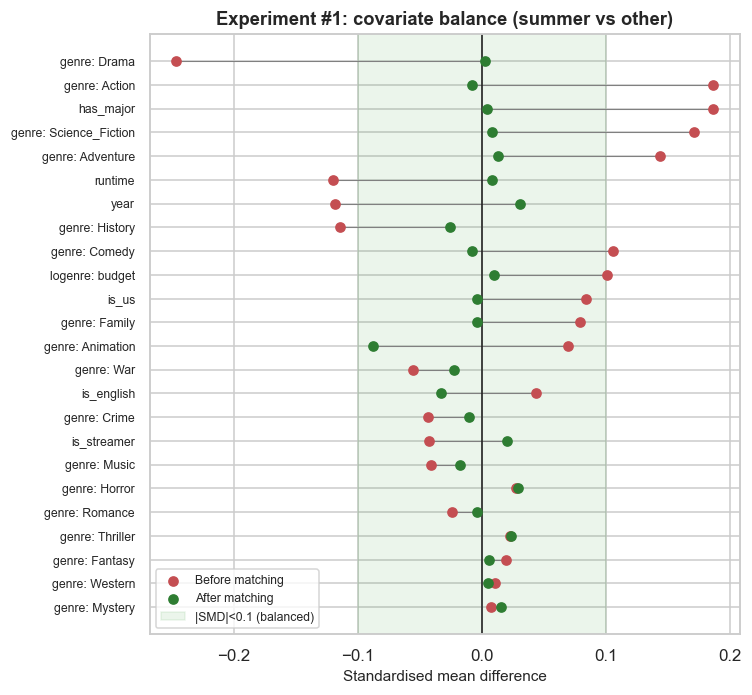

Matched 1565 of 1565 summer films to 1049 distinct controls
Largest |SMD| before: 0.25  ->  after: 0.09


In [47]:
cov1 = ['log_budget', 'runtime', 'year', 'is_us', 'is_english', 'has_major', 'is_streamer'] + GCOLS_OK
res1 = psm(fa, 'is_summer', cov1, 'hit')
love_plot(res1['balance'], 'Experiment #1: covariate balance (summer vs other)', '32_ab1_love')
print(f"Matched {res1['n_matched']} of {res1['n_treated']} summer films to {res1['n_unique_controls']} distinct controls")
print(f"Largest |SMD| before: {res1['balance'].SMD_before.abs().max():.2f}  ->  after: {res1['balance'].SMD_after.abs().max():.2f}")

**Step 4 - Adjusted effect** (three independent adjustments; agreement across them builds confidence):
(a) propensity-score matching ATT, (b) logistic regression average marginal effect, (c) OLS on ln(revenue) with robust SEs.

Constant columns dropped: []
Collinear columns dropped: []


,effect,ci_low,ci_high,p,unit
estimator,,,,,
Naive difference,6.42,3.44,9.35,2.6e-05,pp hit rate
PSM matched ATT,3.00,-0.45,6.45,9.5e-02,pp hit rate
Logit avg marginal effect,4.46,1.56,7.36,2.6e-03,pp hit rate
Naive diff ln(revenue),0.34,0.23,0.45,3.3e-09,ln units
PSM matched ATT ln(revenue),0.13,0.01,0.24,2.9e-02,ln units
OLS adjusted ln(revenue),0.14,0.06,0.22,5.1e-04,ln units


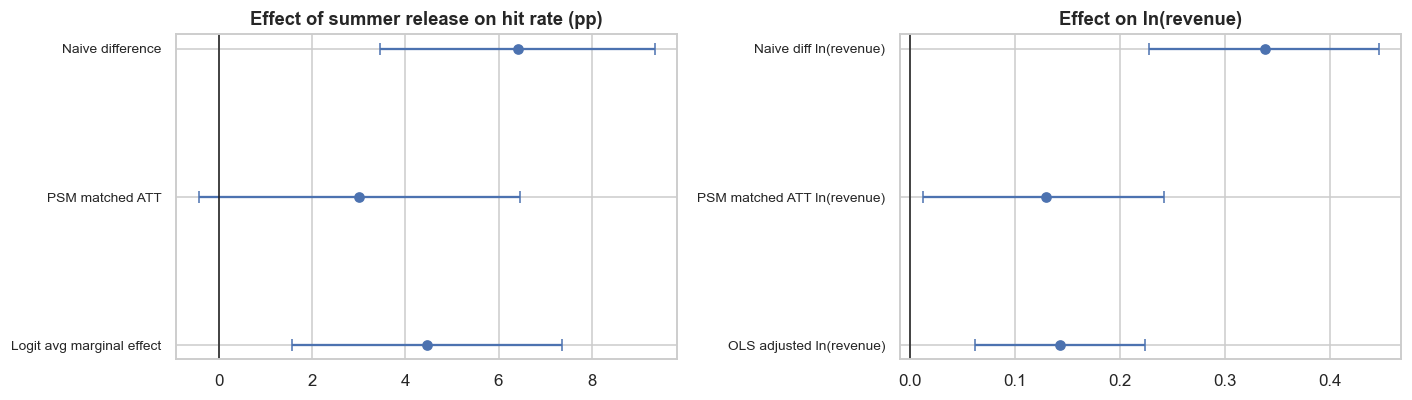

In [48]:
att_rev = psm(fa, 'is_summer', cov1, 'log_revenue')

# ---- 1. Build a clean design matrix --------------------------------------
d = fa.dropna(subset=cov1 + ['hit', 'log_revenue']).copy()

# drop constant columns
const_cols = [c for c in cov1 if d[c].nunique() <= 1]
print('Constant columns dropped:', const_cols)

# greedily drop columns that are perfectly collinear with ones already kept
keep = []
for c in [c for c in cov1 if c not in const_cols]:
    trial = keep + [c]
    X_try = sm.add_constant(d[['is_summer'] + trial].astype(float))
    if np.linalg.matrix_rank(X_try) == X_try.shape[1]:
        keep.append(c)
print('Collinear columns dropped:', [c for c in cov1 if c not in const_cols and c not in keep])

# standardise continuous covariates (is_summer and 0/1 dummies stay as-is)
cont = [c for c in keep if d[c].nunique() > 2]
d[cont] = (d[cont] - d[cont].mean()) / d[cont].std()

cov_f = ' + '.join(keep)

# ---- 2. Fit, with a fallback optimiser if Newton fails --------------------
try:
    lm1 = smf.logit(f'hit ~ is_summer + {cov_f}', data=d).fit(disp=0)
except Exception:
    lm1 = smf.logit(f'hit ~ is_summer + {cov_f}', data=d).fit(method='bfgs', maxiter=1000, disp=0)

ame = lm1.get_margeff().summary_frame().loc['is_summer']
ols1 = smf.ols(f'log_revenue ~ is_summer + {cov_f}', data=d).fit(cov_type='HC3')
tab = pd.DataFrame([
    ['Naive difference', r1['abs_lift'] * 100, r1['CI_low'] * 100, r1['CI_high'] * 100, r1['p_ztest'], 'pp hit rate'],
    ['PSM matched ATT', res1['att'] * 100, res1['ci'][0] * 100, res1['ci'][1] * 100, res1['p'], 'pp hit rate'],
    ['Logit avg marginal effect', ame['dy/dx'] * 100, ame['Conf. Int. Low'] * 100, ame['Cont. Int. Hi.'] * 100, ame['Pr(>|z|)'], 'pp hit rate'],
    ['Naive diff ln(revenue)', c1['diff'], *c1['CI_boot'], c1['p_welch'], 'ln units'],
    ['PSM matched ATT ln(revenue)', att_rev['att'], *att_rev['ci'], att_rev['p'], 'ln units'],
    ['OLS adjusted ln(revenue)', ols1.params['is_summer'], *ols1.conf_int().loc['is_summer'], ols1.pvalues['is_summer'], 'ln units']],
    columns=['estimator', 'effect', 'ci_low', 'ci_high', 'p', 'unit']).set_index('estimator')
display(tab.style.format({'effect': '{:.2f}', 'ci_low': '{:.2f}', 'ci_high': '{:.2f}', 'p': '{:.1e}'}))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a_, sl, ttl in [(ax[0], slice(0, 3), 'Effect of summer release on hit rate (pp)'), (ax[1], slice(3, 6), 'Effect on ln(revenue)')]:
    t_ = tab.iloc[sl]; y = np.arange(len(t_))[::-1]
    a_.errorbar(t_.effect, y, xerr=[t_.effect - t_.ci_low, t_.ci_high - t_.effect], fmt='o', capsize=4, color='#4C72B0'); a_.axvline(0, c='k', lw=1)
    a_.set_yticks(y); a_.set_yticklabels(t_.index, fontsize=9); a_.set_title(ttl)
plt.tight_layout()
plt.show()
ab_results.append({'experiment': '#1 Summer release', 'metric': 'hit rate (pp)', 'naive': r1['abs_lift'] * 100, 'naive_p': r1['p_ztest'], 'adjusted': res1['att'] * 100,
                   'adj_ci': f"[{res1['ci'][0] * 100:+.1f}, {res1['ci'][1] * 100:+.1f}]", 'adj_p': res1['p']})

### 9.4 Experiment #2 - Does major-studio backing raise hit probability? (H7)
Streaming-original films are excluded (they have a different revenue model). Same protocol: naive -> balance -> adjusted.

Hit rate: Major 65.9% (n=2,595) vs Independent 52.3% (n=1,975) | lift +13.6 pp (95% CI +10.8 to +16.5) | p=1.2e-20 | P(Major better)=100.0%


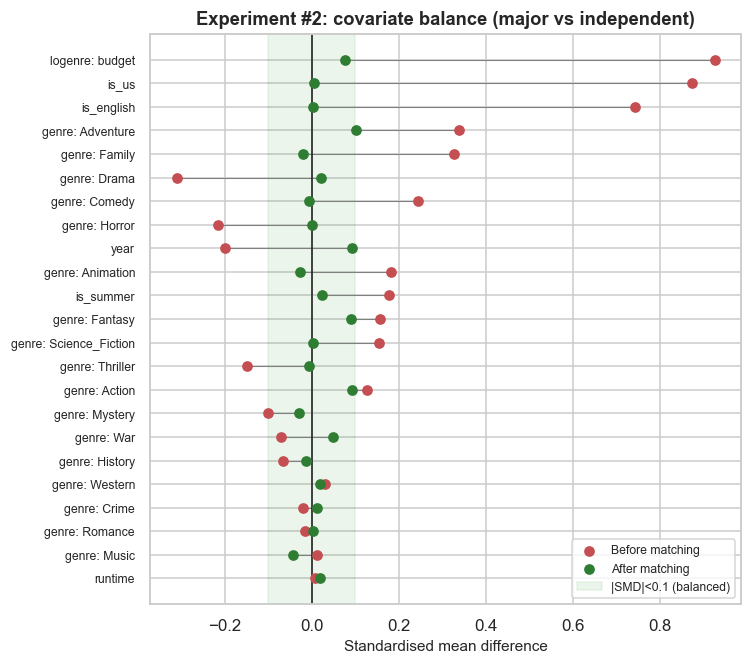


Adjusted effect on hit rate:  PSM ATT = +16.2 pp (95% CI +13.5 to +18.8, p=3.3e-04) | logit AME = +16.3 pp (p=2.7e-23)
ln(revenue): naive diff = 1.61 (x5.0);  PSM-adjusted ATT = 0.58 (x1.79; 95% CI x1.67 to x1.91)


In [49]:
fb = fin[fin.is_streamer == 0].copy()
A2, B2 = fb[fb.has_major == 1], fb[fb.has_major == 0]
r2 = ab_binary(A2.hit, B2.hit)
print(f"Hit rate: Major {r2['rate_A']:.1%} (n={r2['n_A']:,}) vs Independent {r2['rate_B']:.1%} (n={r2['n_B']:,}) | lift {r2['abs_lift'] * 100:+.1f} pp (95% CI {r2['CI_low'] * 100:+.1f} to {r2['CI_high'] * 100:+.1f}) | p={r2['p_ztest']:.1e} | P(Major better)={r2['P(A>B)']:.1%}")
cov2 = ['log_budget', 'runtime', 'year', 'is_us', 'is_english', 'is_summer'] + GCOLS_OK
res2 = psm(fb, 'has_major', cov2, 'hit')
love_plot(res2['balance'], 'Experiment #2: covariate balance (major vs independent)', '34_ab2_love')
lm2 = smf.logit(f'hit ~ has_major + {" + ".join(cov2)}', data=fb.dropna(subset=cov2)).fit(disp=0)
ame2 = lm2.get_margeff().summary_frame().loc['has_major']
print(f"\nAdjusted effect on hit rate:  PSM ATT = {res2['att'] * 100:+.1f} pp (95% CI {res2['ci'][0] * 100:+.1f} to {res2['ci'][1] * 100:+.1f}, p={res2['p']:.1e}) | logit AME = {ame2['dy/dx'] * 100:+.1f} pp (p={ame2['Pr(>|z|)']:.1e})")
c2 = ab_continuous(A2.log_revenue, B2.log_revenue); att2 = psm(fb, 'has_major', cov2, 'log_revenue')
print(f"ln(revenue): naive diff = {c2['diff']:.2f} (x{np.exp(c2['diff']):.1f});  PSM-adjusted ATT = {att2['att']:.2f} (x{np.exp(att2['att']):.2f}; 95% CI x{np.exp(att2['ci'][0]):.2f} to x{np.exp(att2['ci'][1]):.2f})")
ab_results.append({'experiment': '#2 Major-studio backing', 'metric': 'hit rate (pp)', 'naive': r2['abs_lift'] * 100, 'naive_p': r2['p_ztest'], 'adjusted': res2['att'] * 100,
                   'adj_ci': f"[{res2['ci'][0] * 100:+.1f}, {res2['ci'][1] * 100:+.1f}]", 'adj_p': res2['p']})

### 9.5 Experiment #3 - Are international co-productions rated higher? (H8)
Continuous metric (audience rating on the >=50-vote sample). Because rating is bounded and roughly symmetric, I report the mean difference with a bootstrap CI, a rank test, and matching on content/market covariates.

Rating: co-production 6.64 (n=2,234) vs single-country 6.70 (n=5,086)  |  diff = -0.060 (95% CI -0.099 to -0.020) | d=-0.08 | Welch p=2.61e-03 | MW p=8.30e-04


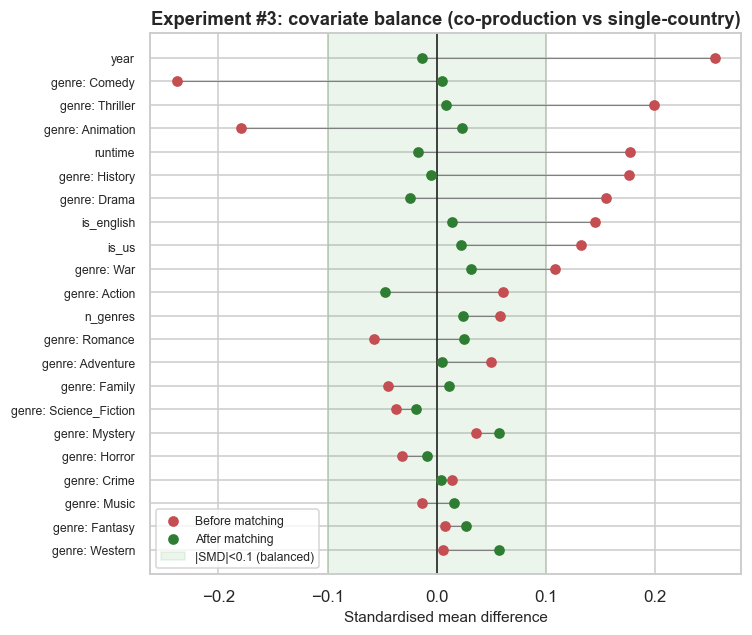

Adjusted: PSM ATT = -0.046 (95% CI -0.092 to -0.002, p=4.43e-02) | OLS = -0.038 (p=2.83e-02)


In [50]:
A3, B3 = rated[rated.is_coproduction == 1], rated[rated.is_coproduction == 0]
c3 = ab_continuous(A3.vote_average, B3.vote_average)
print(f"Rating: co-production {c3['mean_A']:.2f} (n={c3['n_A']:,}) vs single-country {c3['mean_B']:.2f} (n={c3['n_B']:,})  |  diff = {c3['diff']:+.3f} (95% CI {c3['CI_boot'][0]:+.3f} to {c3['CI_boot'][1]:+.3f}) | d={c3['cohen_d']:.2f} | Welch p={c3['p_welch']:.2e} | MW p={c3['p_mw']:.2e}")
cov3 = ['runtime', 'year', 'is_us', 'is_english', 'n_genres'] + GCOLS_OK
res3 = psm(rated, 'is_coproduction', cov3, 'vote_average')
love_plot(res3['balance'], 'Experiment #3: covariate balance (co-production vs single-country)', '35_ab3_love')
ols3 = smf.ols(f'vote_average ~ is_coproduction + {" + ".join(cov3)}', data=rated.dropna(subset=cov3)).fit(cov_type='HC3')
print(f"Adjusted: PSM ATT = {res3['att']:+.3f} (95% CI {res3['ci'][0]:+.3f} to {res3['ci'][1]:+.3f}, p={res3['p']:.2e}) | OLS = {ols3.params['is_coproduction']:+.3f} (p={ols3.pvalues['is_coproduction']:.2e})")
ab_results.append({'experiment': '#3 Co-production', 'metric': 'rating (points)', 'naive': c3['diff'], 'naive_p': c3['p_welch'], 'adjusted': res3['att'],
                   'adj_ci': f"[{res3['ci'][0]:+.2f}, {res3['ci'][1]:+.2f}]", 'adj_p': res3['p']})

### 9.6 Experiment scorecard (with multiple-testing control across the 3 experiments)

In [51]:
sc = pd.DataFrame(ab_results).set_index('experiment')
sc['adj_p_holm'] = multipletests(sc.adj_p, method='holm')[1]
sc['verdict'] = np.where(sc.adj_p_holm < .05, 'Real effect after adjustment', 'No reliable effect after adjustment')
sc['naive_vs_adjusted'] = np.where(np.sign(sc.naive) != np.sign(sc.adjusted), 'sign flips',
                                   np.where(sc.adjusted.abs() < sc.naive.abs() * .75, 'shrinks >25%', 'holds up'))
display(sc.style.format({'naive': '{:+.2f}', 'adjusted': '{:+.2f}', 'naive_p': '{:.1e}', 'adj_p': '{:.1e}', 'adj_p_holm': '{:.1e}'}))

,metric,naive,naive_p,adjusted,adj_ci,adj_p,adj_p_holm,verdict,naive_vs_adjusted
experiment,,,,,,,,,
#1 Summer release,hit rate (pp),+6.42,2.6e-05,+3.00,"[-0.4, +6.5]",9.5e-02,9.5e-02,No reliable effect after adjustment,shrinks >25%
#2 Major-studio backing,hit rate (pp),+13.63,1.2e-20,+16.19,"[+13.5, +18.8]",3.3e-04,1.0e-03,Real effect after adjustment,holds up
#3 Co-production,rating (points),-0.06,2.6e-03,-0.05,"[-0.09, -0.00]",4.4e-02,8.9e-02,No reliable effect after adjustment,holds up


## 10. Machine Learning

### 10.1 Problem framing and validation design
| | Task A - Revenue regression | Task B - Hit classification |
|---|---|---|
| Target | ln(revenue) | hit (revenue >= 2x budget) |
| Use case | size the opportunity before greenlighting | go / no-go screen |
| Metrics | RMSE, MAE, R2 (log scale); **share of films predicted within a factor of 2** | ROC-AUC, PR-AUC, F1, Brier, calibration, decile lift |

**Features: strictly pre-release.** Budget, runtime, release month, genres, countries, language, studio flags, and the director's / lead actor's **prior** track record. `vote_count`, `popularity`, and `vote_average` are *excluded* because they exist only after audiences have seen the film (leakage - quantified in 10.5).

**Validation: a temporal hold-out.** A random split lets the model "see the future" (e.g. train on 2022 films, test on 2019). Real deployment is predict-the-next-slate, so I train on the earliest 80% of films and test on the **most recent 20%**. Hyper-parameters are tuned by cross-validation *inside the training period only*.

In [52]:
from sklearn.model_selection import KFold, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, HistGradientBoostingRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, balanced_accuracy_score, brier_score_loss, roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
import xgboost as xgb, shap, joblib

NUM_F = ['log_budget', 'runtime', 'year', 'month_sin', 'month_cos', 'n_genres', 'n_countries', 'n_companies',
         'dir_prior_films', 'dir_prior_mean_logrev', 'lead_prior_films', 'lead_prior_mean_logrev']
BIN_F = ['is_us', 'is_english', 'is_coproduction', 'has_major', 'is_streamer'] + GCOLS_OK
CAT_F = ['lang_group', 'season_short']
ALL_F = NUM_F + BIN_F + CAT_F

def make_pre(scale=True, num=NUM_F):
    numeric = Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)), ('sc', StandardScaler() if scale else 'passthrough')])
    return ColumnTransformer([('num', numeric, num), ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_F), ('bin', 'passthrough', BIN_F)])

ml = fin.sort_values(['release_date', 'id']).reset_index(drop=True)
cut = int(len(ml) * .8)
train, test = ml.iloc[:cut].copy(), ml.iloc[cut:].copy()
print(f'Train: {len(train):,} films  ({train.release_date.min().date()} -> {train.release_date.max().date()})')
print(f'Test : {len(test):,} films  ({test.release_date.min().date()} -> {test.release_date.max().date()})   <- strictly later in time')
print(f'Hit rate  train {train.hit.mean():.1%} | test {test.hit.mean():.1%}   (note the drift - a real-world warning for any model)')

Train: 3,665 films  (1915-02-08 -> 2018-07-04)
Test : 917 films  (2018-07-05 -> 2025-03-31)   <- strictly later in time
Hit rate  train 63.7% | test 44.7%   (note the drift - a real-world warning for any model)


### 10.2 Task A - predicting revenue
Candidates span the complexity ladder: a naive baseline (what must be beaten), a regularised linear model (interpretable), and three tree ensembles (capture non-linearity and interactions). Five-fold CV on the training period gives a stable ranking; the temporal test set gives the honest final score.

In [53]:
ytr, yte = train.log_revenue.values, test.log_revenue.values
kf = KFold(5, shuffle=True, random_state=SEED)
reg_defs = {
    'Baseline (train median)': (DummyRegressor(strategy='median'), True),
    'Ridge': (RidgeCV(alphas=np.logspace(-2, 3, 20)), True),
    'Random Forest': (RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=.4, n_jobs=-1, random_state=SEED), False),
    'HistGradientBoosting': (HistGradientBoostingRegressor(max_iter=300, learning_rate=.05, max_leaf_nodes=15, l2_regularization=1., random_state=SEED), False),
    'XGBoost (baseline params)': (xgb.XGBRegressor(n_estimators=400, learning_rate=.03, max_depth=4, subsample=.8, colsample_bytree=.8, n_jobs=-1, random_state=SEED), False)}
reg_pipes = {k: Pipeline([('pre', make_pre(scale)), ('m', m)]) for k, (m, scale) in reg_defs.items()}

def reg_metrics(y, p):
    return {'RMSE': np.sqrt(mean_squared_error(y, p)), 'MAE': mean_absolute_error(y, p), 'R2': r2_score(y, p), 'within 2x': np.mean(np.abs(y - p) < np.log(2))}

cv_rows, test_rows = [], []
for name, pipe in reg_pipes.items():
    cv = cross_validate(pipe, train[ALL_F], ytr, cv=kf, scoring=('neg_root_mean_squared_error', 'r2'))
    cv_rows.append({'model': name, 'CV RMSE': -cv['test_neg_root_mean_squared_error'].mean(), 'CV RMSE sd': cv['test_neg_root_mean_squared_error'].std(), 'CV R2': cv['test_r2'].mean()})
cv_tbl = pd.DataFrame(cv_rows).set_index('model')
display(cv_tbl.round(3))

  File "C:\Users\Lehma\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Lehma\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Lehma\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Lehma\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


,CV RMSE,CV RMSE sd,CV R2
model,,,
Baseline (train median),1.744,0.084,-0.024
Ridge,1.199,0.041,0.515
Random Forest,1.167,0.046,0.540
HistGradientBoosting,1.190,0.040,0.521
XGBoost (baseline params),1.174,0.049,0.535


**Hyper-parameter tuning.** A randomised search (more efficient than a grid in high-dimensional spaces) on the best-performing family. Tuning is done only on training-period folds.

Best params: {'subsample': 1.0, 'reg_lambda': 5, 'reg_alpha': 0, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.02, 'colsample_bytree': 0.6}
Tuned XGBoost CV RMSE = 1.194


,CV RMSE,TEST RMSE,TEST MAE,TEST R2,TEST within 2x
model,,,,,
Baseline (train median),1.744,2.270,1.718,-0.156,0.285
Ridge,1.199,1.682,1.175,0.365,0.438
Random Forest,1.167,1.684,1.195,0.364,0.415
HistGradientBoosting,1.190,1.700,1.194,0.352,0.429
XGBoost (baseline params),1.174,1.674,1.179,0.371,0.421
XGBoost (tuned),1.194,1.687,1.188,0.361,0.438


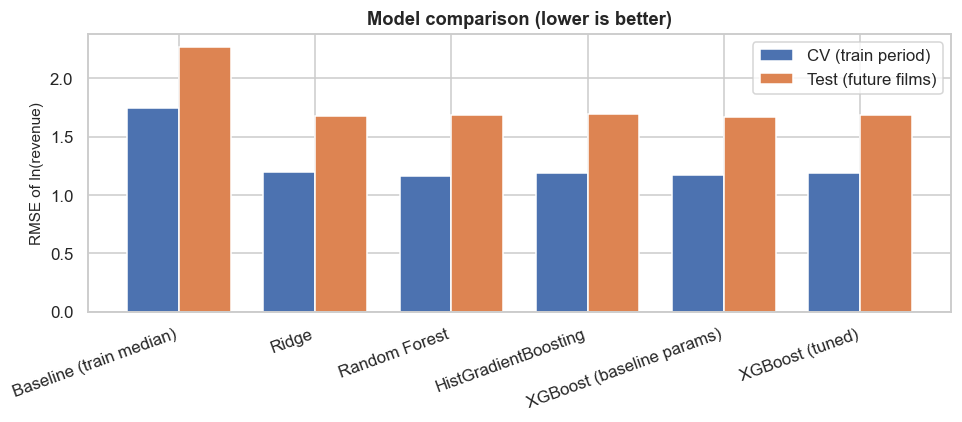

In [54]:
xgb_space = {'m__n_estimators': [200, 300, 500, 800], 'm__learning_rate': [.01, .02, .03, .05, .08], 'm__max_depth': [2, 3, 4, 5, 6],
             'm__min_child_weight': [1, 3, 5, 10], 'm__subsample': [.6, .8, 1.0], 'm__colsample_bytree': [.4, .6, .8, 1.0],
             'm__reg_lambda': [1, 5, 10, 20], 'm__reg_alpha': [0, .1, 1]}
rs = RandomizedSearchCV(Pipeline([('pre', make_pre(False)), ('m', xgb.XGBRegressor(n_jobs=-1, random_state=SEED))]), xgb_space, n_iter=30, cv=4,
                        scoring='neg_root_mean_squared_error', random_state=SEED, n_jobs=1, refit=True)
rs.fit(train[ALL_F], ytr)
best_reg = rs.best_estimator_
print('Best params:', {k.replace('m__', ''): v for k, v in rs.best_params_.items()})
print(f'Tuned XGBoost CV RMSE = {-rs.best_score_:.3f}')
reg_pipes['XGBoost (tuned)'] = best_reg
cv_tbl.loc['XGBoost (tuned)'] = [-rs.best_score_, np.nan, np.nan]

# final fit on train, score on the future
for name, pipe in reg_pipes.items():
    if name != 'XGBoost (tuned)': pipe.fit(train[ALL_F], ytr)
    test_rows.append({'model': name, **reg_metrics(yte, pipe.predict(test[ALL_F]))})
test_tbl = pd.DataFrame(test_rows).set_index('model')
comp = cv_tbl[['CV RMSE']].join(test_tbl.add_prefix('TEST '))
display(comp.style.format('{:.3f}').background_gradient(subset=['TEST R2', 'TEST within 2x'], cmap='Greens').background_gradient(subset=['TEST RMSE'], cmap='Reds_r'))
fig, ax = plt.subplots(figsize=(9, 4))
w = .38; x = np.arange(len(comp))
ax.bar(x - w / 2, comp['CV RMSE'], w, label='CV (train period)', color='#4C72B0'); ax.bar(x + w / 2, comp['TEST RMSE'], w, label='Test (future films)', color='#DD8452')
ax.set_xticks(x); ax.set_xticklabels(comp.index, rotation=20, ha='right'); ax.set_ylabel('RMSE of ln(revenue)'); ax.legend(); ax.set_title('Model comparison (lower is better)')
plt.tight_layout()
plt.show()

### 10.3 How good is the revenue model, really?
RMSE on a log scale is abstract; the practical question is *"how often is the prediction within a factor of 2 of actual?"* and *"where does it fail?"*.

TEST  R2 = 0.361 | RMSE = 1.687 (typical error factor x5.40) | MAE = 1.188 | within 2x of actual: 43.8%
Baseline R2 = -0.156, within 2x = 28.5%


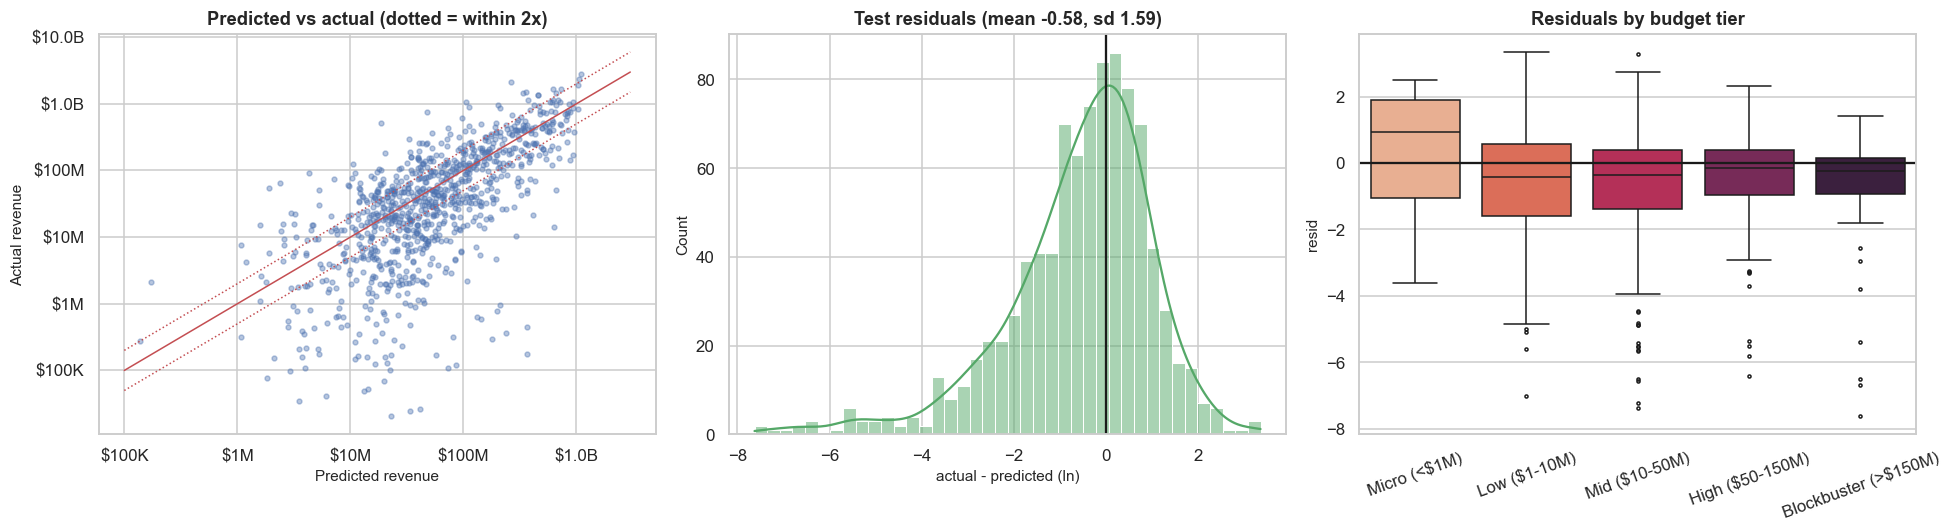

In [55]:
pred = best_reg.predict(test[ALL_F]); m_ = reg_metrics(yte, pred)
print(f"TEST  R2 = {m_['R2']:.3f} | RMSE = {m_['RMSE']:.3f} (typical error factor x{np.exp(m_['RMSE']):.2f}) | MAE = {m_['MAE']:.3f} | within 2x of actual: {m_['within 2x']:.1%}")
base = reg_pipes['Baseline (train median)'].predict(test[ALL_F]); print(f"Baseline R2 = {r2_score(yte, base):.3f}, within 2x = {np.mean(np.abs(yte - base) < np.log(2)):.1%}")
test['pred_log_rev'] = pred; test['resid'] = yte - pred
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].scatter(np.exp(pred), test.revenue, s=10, alpha=.4, c='#4C72B0'); lim = [1e5, 3e9]; ax[0].plot(lim, lim, 'r-', lw=1); ax[0].plot(lim, [l * 2 for l in lim], 'r:', lw=1); ax[0].plot(lim, [l / 2 for l in lim], 'r:', lw=1)
ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].xaxis.set_major_formatter(MONEY); ax[0].yaxis.set_major_formatter(MONEY); ax[0].set_xlabel('Predicted revenue'); ax[0].set_ylabel('Actual revenue'); ax[0].set_title('Predicted vs actual (dotted = within 2x)')
sns.histplot(test.resid, bins=40, kde=True, ax=ax[1], color='#55A868'); ax[1].axvline(0, c='k'); ax[1].set_title(f'Test residuals (mean {test.resid.mean():+.2f}, sd {test.resid.std():.2f})'); ax[1].set_xlabel('actual - predicted (ln)')
sns.boxplot(data=test, x='budget_tier', y='resid', ax=ax[2], palette='rocket_r', fliersize=2); ax[2].axhline(0, c='k'); ax[2].set_xlabel(''); ax[2].tick_params(axis='x', rotation=20); ax[2].set_title('Residuals by budget tier')
plt.tight_layout()
plt.show()

### 10.4 Honest uncertainty: prediction intervals
A point forecast without a range is dangerous in a business with this much variance. I fit **quantile gradient-boosting** models for the 10th and 90th percentiles; a well-calibrated 80% interval should contain ~80% of actual outcomes on the *test* set.

Nominal 80% interval -> empirical test coverage = 64.6%;  median interval width = x13.0 (upper/lower revenue ratio)


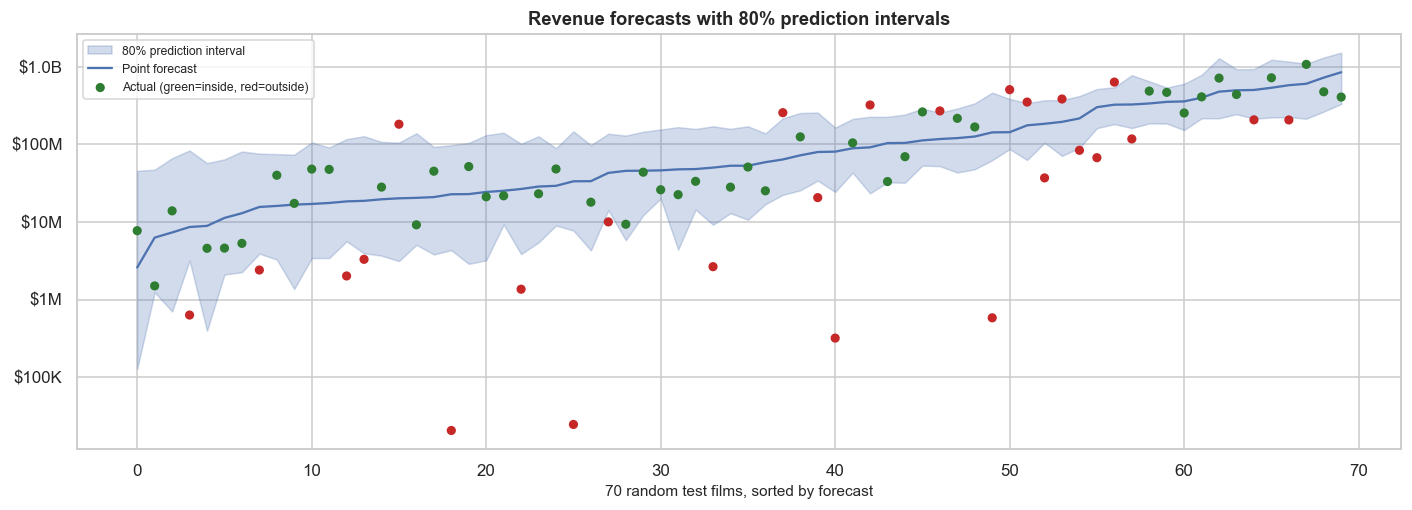

In [56]:
def qpipe(alpha): return Pipeline([('pre', make_pre(False)), ('m', GradientBoostingRegressor(loss='quantile', alpha=alpha, n_estimators=300, max_depth=3, learning_rate=.05, subsample=.8, random_state=SEED))])
q_lo, q_hi = qpipe(.1).fit(train[ALL_F], ytr), qpipe(.9).fit(train[ALL_F], ytr)
lo_t, hi_t = q_lo.predict(test[ALL_F]), q_hi.predict(test[ALL_F])
cover = np.mean((yte >= lo_t) & (yte <= hi_t))
print(f'Nominal 80% interval -> empirical test coverage = {cover:.1%};  median interval width = x{np.exp(np.median(hi_t - lo_t)):.1f} (upper/lower revenue ratio)')
samp = test.sample(70, random_state=SEED).sort_values('pred_log_rev'); i_ = samp.index
fig, ax = plt.subplots(figsize=(13, 4.8))
xs = np.arange(len(samp)); ax.fill_between(xs, np.exp(lo_t[test.index.get_indexer(i_)]), np.exp(hi_t[test.index.get_indexer(i_)]), alpha=.25, color='#4C72B0', label='80% prediction interval')
ax.plot(xs, np.exp(samp.pred_log_rev), c='#4C72B0', lw=1.5, label='Point forecast'); ax.scatter(xs, samp.revenue, c=np.where((samp.log_revenue >= lo_t[test.index.get_indexer(i_)]) & (samp.log_revenue <= hi_t[test.index.get_indexer(i_)]), '#2E7D32', '#C62828'), s=25, zorder=5, label='Actual (green=inside, red=outside)')
ax.set_yscale('log'); ax.yaxis.set_major_formatter(MONEY); ax.set_xlabel('70 random test films, sorted by forecast'); ax.set_title('Revenue forecasts with 80% prediction intervals'); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 10.5 What does the model rely on? (explainability)
Three lenses: **permutation importance** (how much does test error rise if a feature is shuffled? model-agnostic, computed on unseen data), **SHAP** (direction and magnitude of each feature's contribution, per film), and a **leakage test** that shows why post-release signals were deliberately excluded.

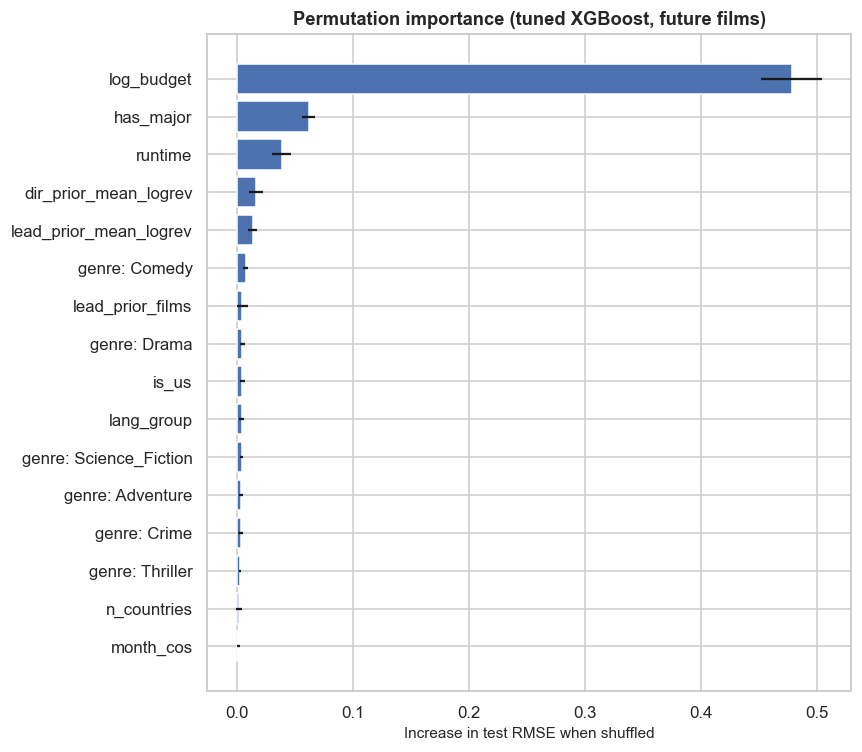

In [57]:
pi = permutation_importance(best_reg, test[ALL_F], yte, n_repeats=15, random_state=SEED, scoring='neg_root_mean_squared_error', n_jobs=1)
imp = pd.DataFrame({'feature': ALL_F, 'mean': pi.importances_mean, 'sd': pi.importances_std}).sort_values('mean')
imp['feature'] = imp.feature.str.replace(r'^g_', 'genre: ', regex=True)
fig, ax = plt.subplots(figsize=(8, 7))
t_ = imp.tail(16); ax.barh(t_.feature, t_['mean'], xerr=t_.sd, color='#4C72B0'); ax.set_xlabel('Increase in test RMSE when shuffled'); ax.set_title('Permutation importance (tuned XGBoost, future films)')
plt.tight_layout()
plt.show()

In [58]:
pre_f, mdl = best_reg.named_steps['pre'], best_reg.named_steps['m']
feat_names = [re.sub(r'^g_', 'genre: ', n.split('__', 1)[1]) if n.split('__')[0] in ('num', 'cat', 'bin') else n for n in pre_f.get_feature_names_out()]
Xt = pd.DataFrame(pre_f.transform(test[ALL_F]), columns=feat_names)
sv = shap.TreeExplainer(mdl)(Xt)
plt.figure(); shap.plots.beeswarm(sv, max_display=16, show=False); plt.title('SHAP values: impact on predicted ln(revenue)'); plt.tight_layout(); savefig('40_shap_beeswarm'); plt.show()
ib, im = feat_names.index('log_budget'), feat_names.index('has_major')
shap.plots.scatter(sv[:, ib], color=sv[:, im], show=False) 
plt.title('SHAP dependence: budget effect, coloured by major-studio flag') 
plt.tight_layout()
plt.show()

ValueError: could not convert string to float: '[1.7738186E1]'

In [61]:
pre_f, mdl = best_reg.named_steps['pre'], best_reg.named_steps['m']
feat_names = [re.sub(r'^g_', 'genre: ', n.split('__', 1)[1]) if n.split('__')[0] in ('num', 'cat', 'bin') else n
              for n in pre_f.get_feature_names_out()]
Xt = pd.DataFrame(pre_f.transform(test[ALL_F]), columns=feat_names)

# SHAP values computed natively by XGBoost (last column = base value)
contrib = mdl.get_booster().predict(xgb.DMatrix(Xt.values), pred_contribs=True)
sv = shap.Explanation(values=contrib[:, :-1], base_values=contrib[:, -1],
                      data=Xt.values, feature_names=list(Xt.columns))

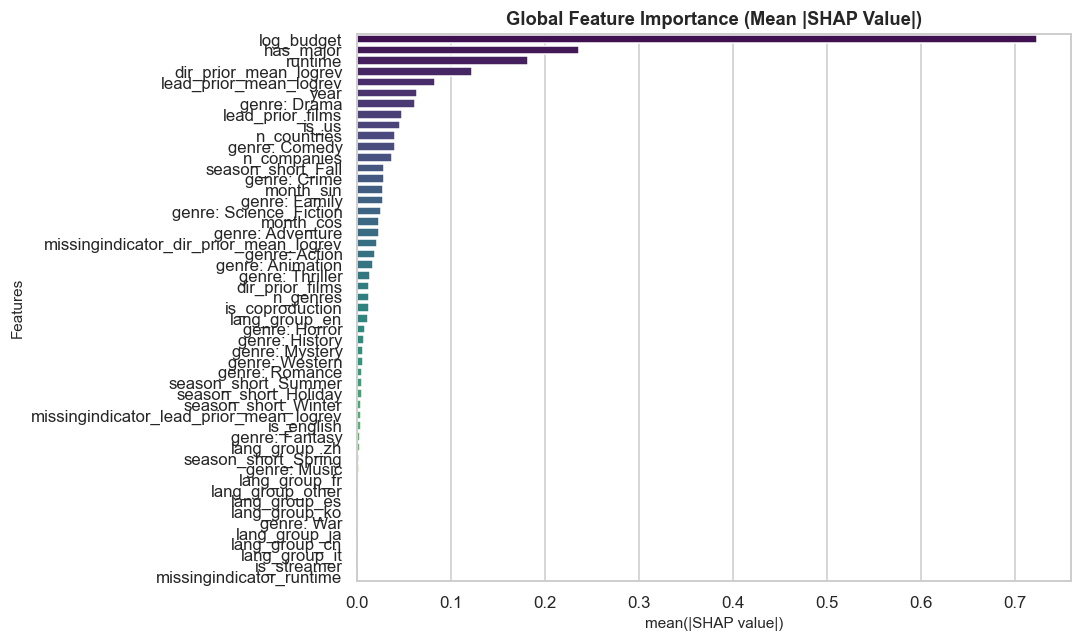

In [62]:
# 1. Extract SHAP values (excluding the last column, which is the base value)
shap_values = contrib[:, :-1]

# 2. Calculate mean absolute SHAP value per feature
mean_abs_shap = np.mean(np.abs(shap_values), axis=0)

# 3. Create a DataFrame for easy plotting
importance_df = pd.DataFrame({
    'Feature': Xt.columns,
    'Mean_Abs_SHAP': mean_abs_shap
}).sort_values(by='Mean_Abs_SHAP', ascending=False)

# 4. Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Mean_Abs_SHAP', y='Feature', data=importance_df, palette='viridis')
plt.title('Global Feature Importance (Mean |SHAP Value|)')
plt.xlabel('mean(|SHAP value|)')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

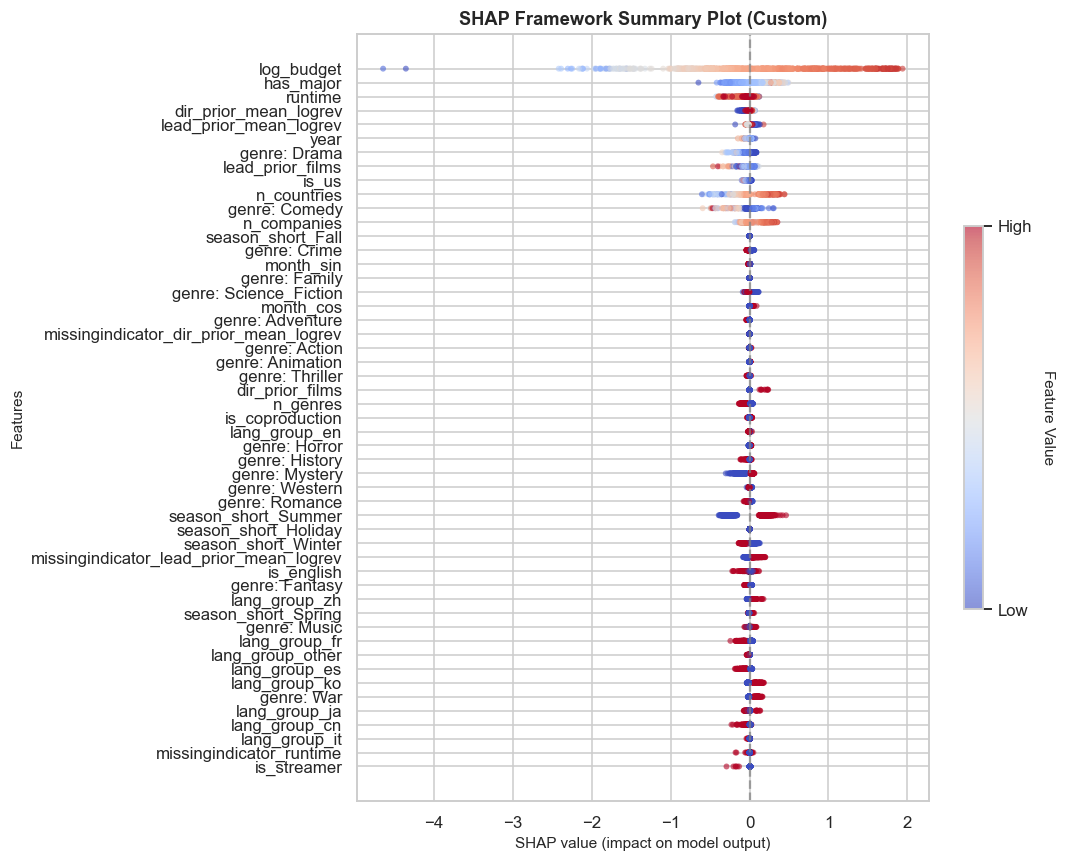

In [66]:
from sklearn.preprocessing import MinMaxScaler
# 1. Extract SHAP values
shap_values = contrib[:, :-1]

# 2. To mimic SHAP's coloring, normalize feature values between 0 (Low) and 1 (High)
scaler = MinMaxScaler()
norm_features = pd.DataFrame(scaler.fit_transform(Xt), columns=Xt.columns)

# 3. Get feature order by mean absolute SHAP value (highest impact at the top)
mean_abs_shap = np.mean(np.abs(shap_values), axis=0)
top_features = [Xt.columns[i] for i in np.argsort(mean_abs_shap)[::-1]]

# 4. Flatten the matrices into a long-form DataFrame for Seaborn
plot_data = []
for i, col in enumerate(Xt.columns):
    df_col = pd.DataFrame({
        'Feature': col,
        'SHAP Value': shap_values[:, i],
        'Feature Value (Normalized)': norm_features[col]
    })
    plot_data.append(df_col)

long_df = pd.concat(plot_data, ignore_index=True)

# 5. Plot using a Scatter/Strip plot
plt.figure(figsize=(10, 8))

# Draw zero line
plt.axvline(x=0, color='gray', linestyle='--', alpha=0.7)

# Create scatter plot with a color map representing feature value intensity
sc = plt.scatter(
    x=long_df['SHAP Value'], 
    y=long_df['Feature'], 
    c=long_df['Feature Value (Normalized)'], 
    cmap='coolwarm', # Blue (low) to Red (high)
    alpha=0.6, 
    edgecolors='none',
    s=15
)

# Reorder y-axis to match SHAP's highest-to-lowest arrangement
plt.gca().set_yticklabels(top_features) 

# Add colorbar
cbar = plt.colorbar(sc, orientation='vertical', shrink=0.5)
cbar.set_label('Feature Value', rotation=270, labelpad=15)
cbar.set_ticks([0, 1])
cbar.set_ticklabels(['Low', 'High'])

plt.title('SHAP Framework Summary Plot (Custom)')
plt.xlabel('SHAP value (impact on model output)')
plt.ylabel('Features')
plt.gca().invert_yaxis() # Put highest impact at the top
plt.tight_layout()
plt.show()

In [63]:
# Leakage demonstration: add post-release signals and watch performance "improve" - for the wrong reason
POST = ['log_vote_count', 'log_popularity', 'vote_average']
ALL_LEAK = ALL_F + POST
mk = lambda num: Pipeline([('pre', make_pre(False, num)), ('m', xgb.XGBRegressor(**{k.replace('m__', ''): v for k, v in rs.best_params_.items()}, n_jobs=-1, random_state=SEED))])
leak = mk(NUM_F + POST).fit(train[ALL_LEAK], ytr)
lk = reg_metrics(yte, leak.predict(test[ALL_LEAK]))
leak_tbl = pd.DataFrame({'Pre-release features only': reg_metrics(yte, pred), '+ post-release signals (LEAKAGE)': lk}).T
display(leak_tbl.round(3))
print(f"R2 jumps from {m_['R2']:.2f} to {lk['R2']:.2f}, but vote_count and popularity are only known AFTER audiences respond to (and often because of) box-office. "
      "A model using them cannot be used to greenlight a film - the 'improvement' is an illusion.")

,RMSE,MAE,R2,within 2x
Pre-release features only,1.687,1.188,0.361,0.438
+ post-release signals (LEAKAGE),1.423,0.977,0.545,0.513


R2 jumps from 0.36 to 0.55, but vote_count and popularity are only known AFTER audiences respond to (and often because of) box-office. A model using them cannot be used to greenlight a film - the 'improvement' is an illusion.


### 10.6 Does more data help? (learning curve)

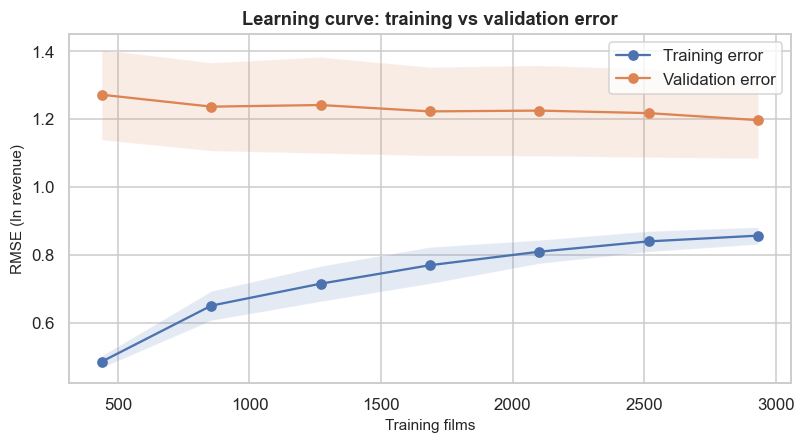

In [64]:
sizes, tr_s, va_s = learning_curve(best_reg, train[ALL_F], ytr, train_sizes=np.linspace(.15, 1, 7), cv=5, scoring='neg_root_mean_squared_error', n_jobs=1, random_state=SEED, shuffle=True)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(sizes, -tr_s.mean(1), 'o-', label='Training error'); ax.fill_between(sizes, -tr_s.mean(1) - tr_s.std(1), -tr_s.mean(1) + tr_s.std(1), alpha=.15)
ax.plot(sizes, -va_s.mean(1), 'o-', label='Validation error'); ax.fill_between(sizes, -va_s.mean(1) - va_s.std(1), -va_s.mean(1) + va_s.std(1), alpha=.15)
ax.set_xlabel('Training films'); ax.set_ylabel('RMSE (ln revenue)'); ax.set_title('Learning curve: training vs validation error'); ax.legend()
plt.tight_layout()
plt.show()

### 10.7 Task B - classifying hits vs non-hits
The class balance is checked first (it determines metric choice), and **PR-AUC** is reported next to ROC-AUC because it is more informative when classes are imbalanced. The decision threshold is chosen on **out-of-fold training predictions** (never on the test set) by maximising F1.

In [67]:
ytr_c, yte_c = train.hit.values.astype(int), test.hit.values.astype(int)
print(f'Class balance - train: {ytr_c.mean():.1%} hits | test: {yte_c.mean():.1%} hits')
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
clf_defs = {
    'Baseline (prior)': (DummyClassifier(strategy='prior'), True),
    'Logistic (L2)': (LogisticRegression(C=.3, max_iter=4000, class_weight='balanced'), True),
    'Random Forest': (RandomForestClassifier(n_estimators=500, min_samples_leaf=5, max_features='sqrt', class_weight='balanced_subsample', n_jobs=-1, random_state=SEED), False),
    'XGBoost': (xgb.XGBClassifier(n_estimators=300, learning_rate=.03, max_depth=3, subsample=.8, colsample_bytree=.8, n_jobs=-1, random_state=SEED, eval_metric='logloss'), False)}
clf_pipes = {k: Pipeline([('pre', make_pre(s)), ('m', m)]) for k, (m, s) in clf_defs.items()}
cvc = []
for name, pipe in clf_pipes.items():
    cv = cross_validate(pipe, train[ALL_F], ytr_c, cv=skf, scoring=('roc_auc', 'average_precision'))
    cvc.append({'model': name, 'CV ROC-AUC': cv['test_roc_auc'].mean(), 'CV ROC-AUC sd': cv['test_roc_auc'].std(), 'CV PR-AUC': cv['test_average_precision'].mean()})
display(pd.DataFrame(cvc).set_index('model').round(3))
xgbc_space = {k: v for k, v in xgb_space.items()}
rsc = RandomizedSearchCV(Pipeline([('pre', make_pre(False)), ('m', xgb.XGBClassifier(n_jobs=-1, random_state=SEED, eval_metric='logloss'))]), xgbc_space, n_iter=30, cv=skf, scoring='roc_auc', random_state=SEED, refit=True)
rsc.fit(train[ALL_F], ytr_c); clf_pipes['XGBoost (tuned)'] = rsc.best_estimator_
print(f'Tuned XGBoost CV ROC-AUC = {rsc.best_score_:.3f}')

Class balance - train: 63.7% hits | test: 44.7% hits


,CV ROC-AUC,CV ROC-AUC sd,CV PR-AUC
model,,,
Baseline (prior),0.500,0.000,0.637
Logistic (L2),0.678,0.010,0.770
Random Forest,0.680,0.007,0.789
XGBoost,0.688,0.011,0.792


Tuned XGBoost CV ROC-AUC = 0.690


In [68]:
for name, pipe in clf_pipes.items():
    if name != 'XGBoost (tuned)': pipe.fit(train[ALL_F], ytr_c)
probs = {n: p.predict_proba(test[ALL_F])[:, 1] for n, p in clf_pipes.items()}
# threshold chosen on out-of-fold TRAIN predictions for the final model
oof = cross_val_predict(clone_ := Pipeline([('pre', make_pre(False)), ('m', xgb.XGBClassifier(**{k.replace('m__', ''): v for k, v in rsc.best_params_.items()}, n_jobs=-1, random_state=SEED, eval_metric='logloss'))]), train[ALL_F], ytr_c, cv=skf, method='predict_proba')[:, 1]
ths = np.linspace(.2, .8, 61); f1s = [f1_score(ytr_c, oof >= t) for t in ths]; THR = ths[int(np.argmax(f1s))]
print(f'F1-optimal threshold from out-of-fold training predictions: {THR:.2f}')
rows = []
for n, pr in probs.items():
    thr = THR if n == 'XGBoost (tuned)' else .5
    yh = (pr >= thr).astype(int)
    rows.append({'model': n, 'ROC-AUC': roc_auc_score(yte_c, pr), 'PR-AUC': average_precision_score(yte_c, pr), 'F1': f1_score(yte_c, yh), 'Precision': precision_score(yte_c, yh, zero_division=0),
                 'Recall': recall_score(yte_c, yh), 'Balanced acc': balanced_accuracy_score(yte_c, yh), 'Brier': brier_score_loss(yte_c, pr)})
clf_tbl = pd.DataFrame(rows).set_index('model')
display(clf_tbl.style.format('{:.3f}').background_gradient(subset=['ROC-AUC', 'PR-AUC', 'F1'], cmap='Greens'))

F1-optimal threshold from out-of-fold training predictions: 0.40


,ROC-AUC,PR-AUC,F1,Precision,Recall,Balanced acc,Brier
model,,,,,,,
Baseline (prior),0.500,0.447,0.618,0.447,1.000,0.500,0.283
Logistic (L2),0.682,0.621,0.580,0.579,0.580,0.620,0.222
Random Forest,0.664,0.589,0.622,0.536,0.741,0.611,0.234
XGBoost,0.666,0.583,0.652,0.516,0.885,0.606,0.250
XGBoost (tuned),0.660,0.580,0.641,0.484,0.951,0.565,0.255


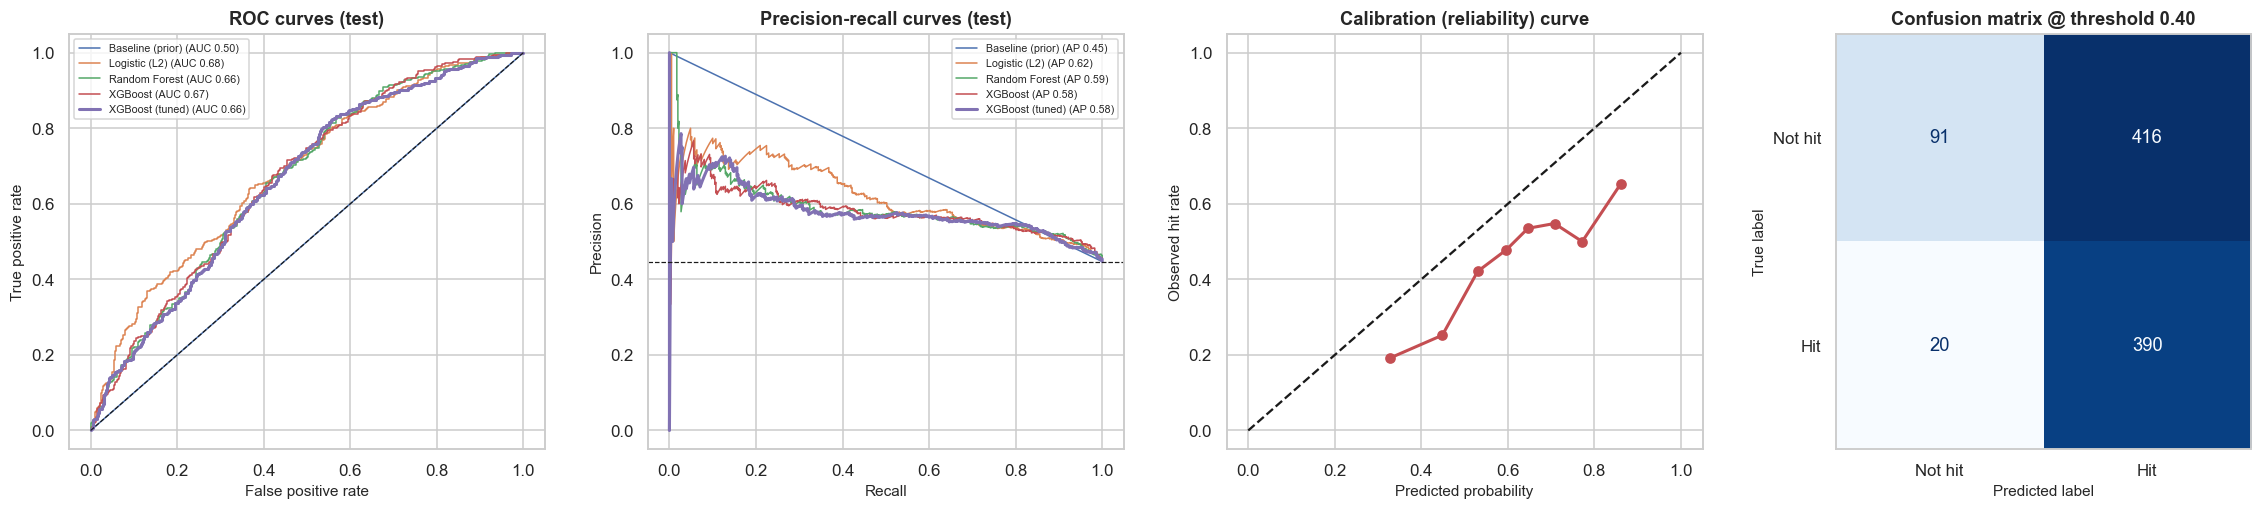

In [69]:
fig, ax = plt.subplots(1, 4, figsize=(21, 4.8))
for n, pr in probs.items():
    fpr, tpr, _ = roc_curve(yte_c, pr); ax[0].plot(fpr, tpr, label=f'{n} (AUC {roc_auc_score(yte_c, pr):.2f})', lw=2 if 'tuned' in n else 1)
    p_, r_, _ = precision_recall_curve(yte_c, pr); ax[1].plot(r_, p_, label=f'{n} (AP {average_precision_score(yte_c, pr):.2f})', lw=2 if 'tuned' in n else 1)
ax[0].plot([0, 1], [0, 1], 'k--', lw=.8); ax[0].set_title('ROC curves (test)'); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate'); ax[0].legend(fontsize=7)
ax[1].axhline(yte_c.mean(), c='k', ls='--', lw=.8); ax[1].set_title('Precision-recall curves (test)'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].legend(fontsize=7)
pr = probs['XGBoost (tuned)']; fo, mp = calibration_curve(yte_c, pr, n_bins=8, strategy='quantile')
ax[2].plot(mp, fo, 'o-', c='#C44E52', lw=2); ax[2].plot([0, 1], [0, 1], 'k--'); ax[2].set_title('Calibration (reliability) curve'); ax[2].set_xlabel('Predicted probability'); ax[2].set_ylabel('Observed hit rate')
ConfusionMatrixDisplay(confusion_matrix(yte_c, pr >= THR), display_labels=['Not hit', 'Hit']).plot(ax=ax[3], cmap='Blues', colorbar=False); ax[3].set_title(f'Confusion matrix @ threshold {THR:.2f}'); ax[3].grid(False)
plt.tight_layout()
plt.show()

**Business lens - decile lift.** If the classifier ranks the upcoming slate, how much better is the top-scored 10-20% than the average film? This is the metric a portfolio manager actually uses.

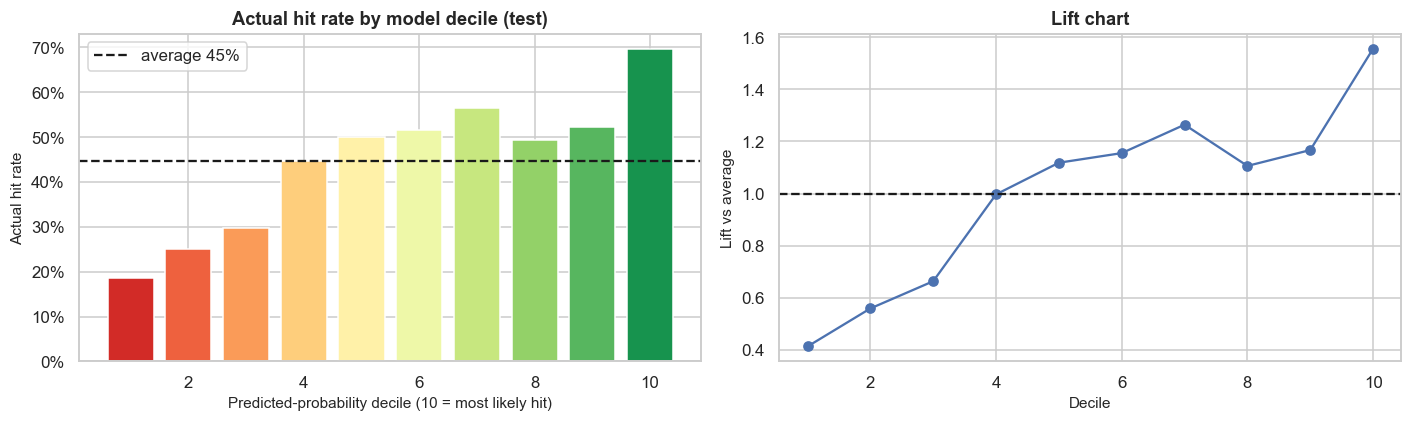

Top decile hit rate 70% vs bottom decile 18%; top-two-deciles lift = 1.36x


In [70]:
dl = pd.DataFrame({'p': pr, 'y': yte_c}); dl['decile'] = pd.qcut(dl.p.rank(method='first'), 10, labels=False) + 1
lift_tbl = dl.groupby('decile').agg(n=('y', 'size'), mean_pred=('p', 'mean'), hit_rate=('y', 'mean')); lift_tbl['lift'] = lift_tbl.hit_rate / dl.y.mean()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(lift_tbl.index, lift_tbl.hit_rate, color=sns.color_palette('RdYlGn', 10)); ax[0].axhline(dl.y.mean(), c='k', ls='--', label=f'average {dl.y.mean():.0%}')
ax[0].set_xlabel('Predicted-probability decile (10 = most likely hit)'); ax[0].set_ylabel('Actual hit rate'); ax[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax[0].legend(); ax[0].set_title('Actual hit rate by model decile (test)')
ax[1].plot(lift_tbl.index, lift_tbl.lift, 'o-'); ax[1].axhline(1, c='k', ls='--'); ax[1].set_xlabel('Decile'); ax[1].set_ylabel('Lift vs average'); ax[1].set_title('Lift chart')
plt.tight_layout()
plt.show()
print(f"Top decile hit rate {lift_tbl.hit_rate.iloc[-1]:.0%} vs bottom decile {lift_tbl.hit_rate.iloc[0]:.0%}; top-two-deciles lift = {dl[dl.decile >= 9].y.mean() / dl.y.mean():.2f}x")

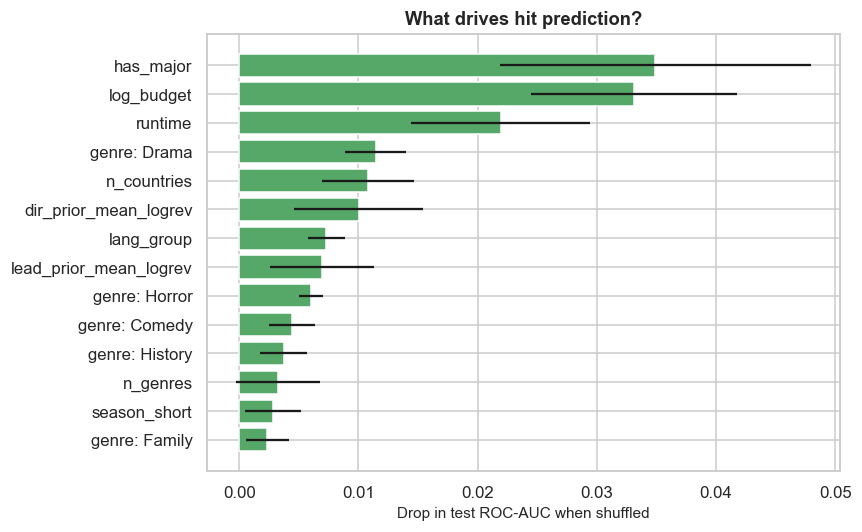

Saved fitted pipelines to ./models/


In [71]:
pic = permutation_importance(clf_pipes['XGBoost (tuned)'], test[ALL_F], yte_c, n_repeats=15, random_state=SEED, scoring='roc_auc', n_jobs=1)
impc = pd.DataFrame({'feature': ALL_F, 'mean': pic.importances_mean, 'sd': pic.importances_std}).sort_values('mean').tail(14)
impc['feature'] = impc.feature.str.replace(r'^g_', 'genre: ', regex=True)
fig, ax = plt.subplots(figsize=(8, 5)); ax.barh(impc.feature, impc['mean'], xerr=impc.sd, color='#55A868'); ax.set_xlabel('Drop in test ROC-AUC when shuffled'); ax.set_title('What drives hit prediction?')
plt.tight_layout()
plt.show()
Path('models').mkdir(exist_ok=True)
joblib.dump(best_reg, 'models/revenue_regressor_xgb.joblib'); joblib.dump(clf_pipes['XGBoost (tuned)'], 'models/hit_classifier_xgb.joblib')
print('Saved fitted pipelines to ./models/')

## 11. Unsupervised Learning: Market Segmentation

Prediction answers "how much will this film earn?". Segmentation answers a different question: **"what kinds of films exist, and do they behave differently?"** I cluster films on their *observed* commercial and reception profile. Because this is a **descriptive** exercise (not a forecasting model), using post-release signals such as ratings and vote counts is appropriate here.

**Features:** ln(budget), ln(revenue), runtime, rating, ln(votes), ln(popularity). Runtime is winsorised at the 1st/99th percentile and everything is standardised, because K-Means and PCA are scale-sensitive.

In [72]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score

CL_F = ['log_budget', 'log_revenue', 'runtime', 'vote_average', 'log_vote_count', 'log_popularity']
cl = fin.dropna(subset=CL_F).copy()
lo_, hi_ = cl.runtime.quantile([.01, .99]); cl['runtime_w'] = cl.runtime.clip(lo_, hi_)
CL_USE = ['log_budget', 'log_revenue', 'runtime_w', 'vote_average', 'log_vote_count', 'log_popularity']
Z = StandardScaler().fit_transform(cl[CL_USE])
print(f'{len(cl):,} films clustered on {len(CL_USE)} standardised features')

4,579 films clustered on 6 standardised features


### 11.1 How many clusters? Four internal criteria + a model-based check
No single criterion is decisive, so I look for agreement among: **inertia (elbow)**, **silhouette** (cohesion vs separation, higher better), **Calinski-Harabasz** (higher better), **Davies-Bouldin** (lower better), plus the **BIC of a Gaussian mixture** (lower better).

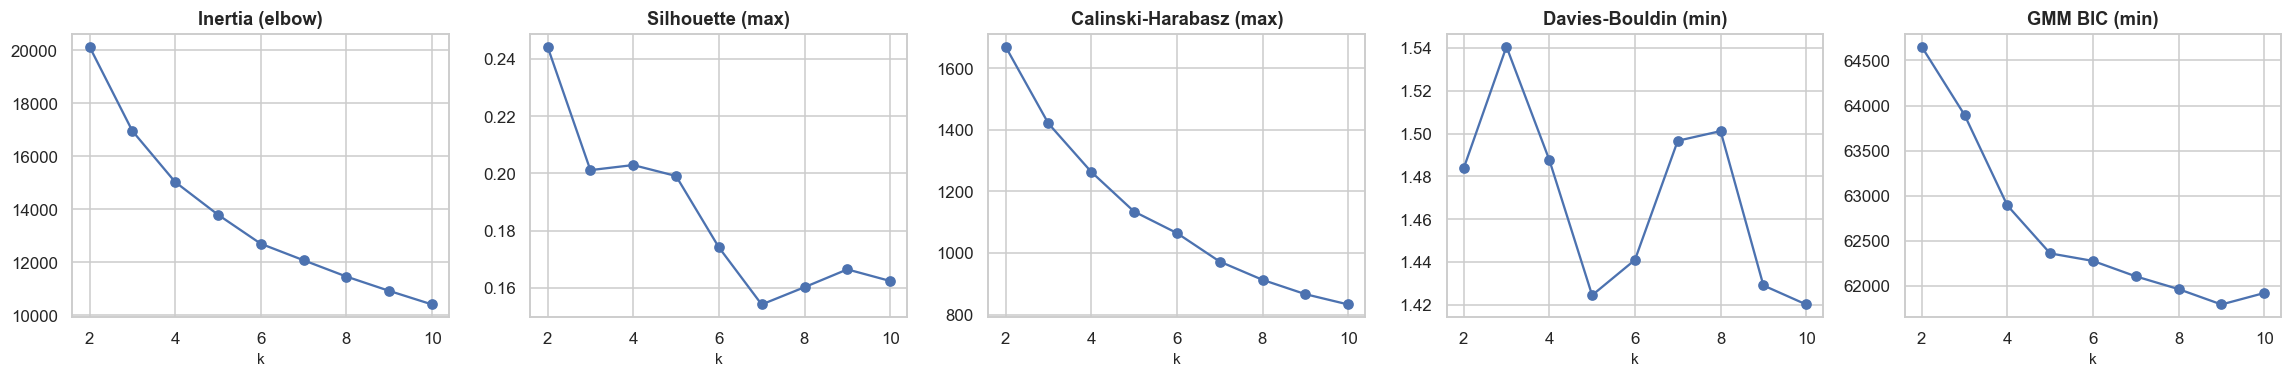

,inertia,silhouette,CH,DB,GMM BIC
k,,,,,
2,"20,130.050",0.240,"1,669.810",1.480,"64,653.530"
3,"16,951.070",0.200,"1,420.370",1.540,"63,896.360"
4,"15,025.830",0.200,"1,263.390",1.490,"62,890.890"
5,"13,791.220",0.200,"1,134.510",1.420,"62,358.460"
6,"12,695.240",0.170,"1,064.710",1.440,"62,274.750"
7,"12,072.560",0.150,972.110,1.500,"62,103.460"
8,"11,457.370",0.160,912.850,1.500,"61,961.650"
9,"10,917.360",0.170,866.330,1.430,"61,791.220"
10,"10,404.890",0.160,832.820,1.420,"61,918.670"


Chosen k = 4  (highest silhouette within the interpretable range 3-7; the elbow / CH / DB curves are consistent with this region)


In [73]:
ks = range(2, 11); rows = []
for k in ks:
    km = KMeans(k, n_init=20, random_state=SEED).fit(Z)
    gm = GaussianMixture(k, n_init=3, random_state=SEED).fit(Z)
    rows.append({'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(Z, km.labels_, sample_size=3000, random_state=SEED),
                 'CH': calinski_harabasz_score(Z, km.labels_), 'DB': davies_bouldin_score(Z, km.labels_), 'GMM BIC': gm.bic(Z)})
kt = pd.DataFrame(rows).set_index('k')
fig, ax = plt.subplots(1, 5, figsize=(21, 3.6))
for a_, c, t in zip(ax, kt.columns, ['Inertia (elbow)', 'Silhouette (max)', 'Calinski-Harabasz (max)', 'Davies-Bouldin (min)', 'GMM BIC (min)']):
    a_.plot(kt.index, kt[c], 'o-'); a_.set_title(t); a_.set_xlabel('k')
plt.tight_layout(); savefig('46_choose_k'); plt.show()
display(kt.round(2))
K = int(kt.loc[3:7, 'silhouette'].idxmax())
print(f'Chosen k = {K}  (highest silhouette within the interpretable range 3-7; the elbow / CH / DB curves are consistent with this region)')

### 11.2 Final K-Means model, relabelled by commercial scale
Cluster ids in K-Means are arbitrary, so I **re-order them by median revenue** (0 = smallest) for stable, readable labels. Stability and agreement with two alternative algorithms (Ward hierarchical, Gaussian mixture) are quantified with the **Adjusted Rand Index** (ARI; 1 = identical partitions, 0 = chance).

In [74]:
km = KMeans(K, n_init=50, random_state=SEED).fit(Z)
order = pd.Series(cl.log_revenue.values).groupby(km.labels_).median().sort_values().index
remap = {old: new for new, old in enumerate(order)}
cl['cluster'] = pd.Series(km.labels_, index=cl.index).map(remap)
lab = cl.cluster.values

ward = AgglomerativeClustering(K, linkage='ward').fit_predict(Z); gmm = GaussianMixture(K, n_init=5, random_state=SEED).fit(Z).predict(Z)
boot_ari = []
for _ in range(40):
    idx = rng.integers(0, len(Z), len(Z)); kb = KMeans(K, n_init=5, random_state=int(rng.integers(1e6))).fit(Z[idx])
    boot_ari.append(adjusted_rand_score(km.labels_, kb.predict(Z)))
print(f'Silhouette = {silhouette_score(Z, lab, sample_size=3000, random_state=SEED):.3f}')
print(f'ARI vs Ward hierarchical = {adjusted_rand_score(lab, ward):.2f} | ARI vs Gaussian mixture = {adjusted_rand_score(lab, gmm):.2f}')
print(f'Bootstrap stability (40 resamples): mean ARI = {np.mean(boot_ari):.2f}  (5th pct {np.percentile(boot_ari, 5):.2f})')

Silhouette = 0.203
ARI vs Ward hierarchical = 0.30 | ARI vs Gaussian mixture = 0.41
Bootstrap stability (40 resamples): mean ARI = 0.91  (5th pct 0.84)


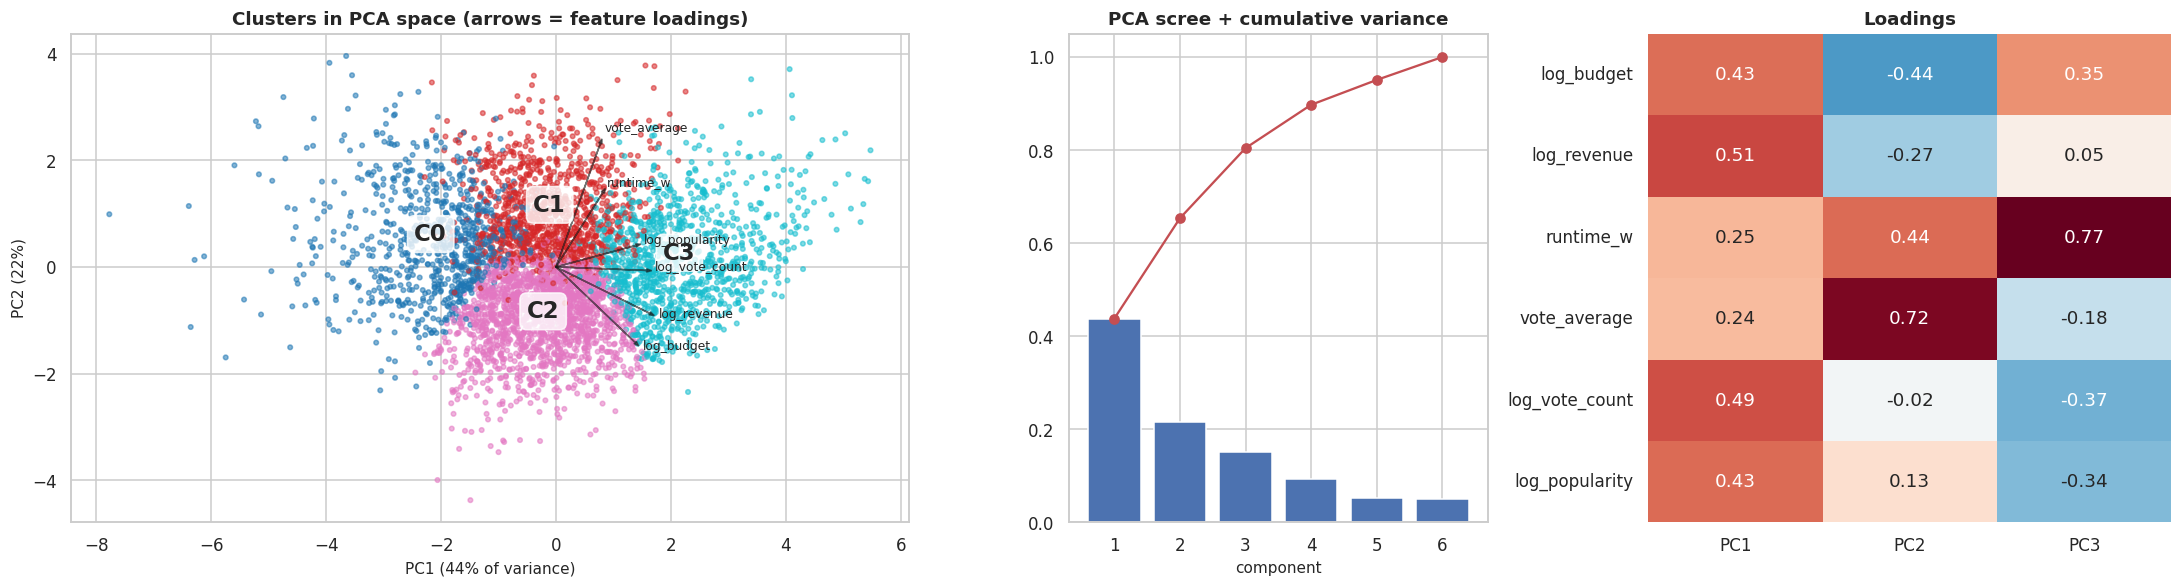

In [69]:
pca = PCA(n_components=6).fit(Z); P = pca.transform(Z)
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={'width_ratios': [1.6, .8, 1]})
sc_ = ax[0].scatter(P[:, 0], P[:, 1], c=lab, cmap='tab10', s=9, alpha=.55)
for c in range(K):
    ax[0].text(*P[lab == c, :2].mean(0), f'C{c}', fontsize=15, weight='bold', ha='center', bbox=dict(boxstyle='round', fc='w', alpha=.8))
for j, f in enumerate(CL_USE):
    ax[0].arrow(0, 0, pca.components_[0, j] * 3.2, pca.components_[1, j] * 3.2, color='k', alpha=.6, head_width=.06); ax[0].text(pca.components_[0, j] * 3.5, pca.components_[1, j] * 3.5, f, fontsize=8)
ax[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)'); ax[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})'); ax[0].set_title('Clusters in PCA space (arrows = feature loadings)')
ax[1].bar(range(1, 7), pca.explained_variance_ratio_, color='#4C72B0'); ax[1].plot(range(1, 7), pca.explained_variance_ratio_.cumsum(), 'ro-'); ax[1].set_title('PCA scree + cumulative variance'); ax[1].set_xlabel('component')
load = pd.DataFrame(pca.components_[:3].T, index=CL_USE, columns=['PC1', 'PC2', 'PC3'])
sns.heatmap(load, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax[2], cbar=False); ax[2].set_title('Loadings')
plt.tight_layout(); savefig('47_pca_clusters'); plt.show()

### 11.3 Profiling the segments
Profiles are the point of clustering: a segmentation is only useful if each group can be **described, named, and acted upon**.

,n,median_budget,median_revenue,median_runtime,median_rating,median_votes,median_popularity,hit_rate,median_roi,pct_english,pct_major,median_year,share
cluster,,,,,,,,,,,,,
0,806,"$4,179,185","$4,278,190",98,6.60,681,2.5,38%,1.20,80%,23%,2010,18%
1,1028,"$15,000,000","$34,690,674",125,7.26,"1,616",3.3,60%,2.67,77%,43%,2006,22%
2,1697,"$31,000,000","$72,526,996",101,6.24,"1,810",3.2,56%,2.23,96%,68%,2008,37%
3,1048,"$75,000,000","$270,000,000",119,7.17,"7,032",9.5,83%,3.97,97%,77%,2012,23%


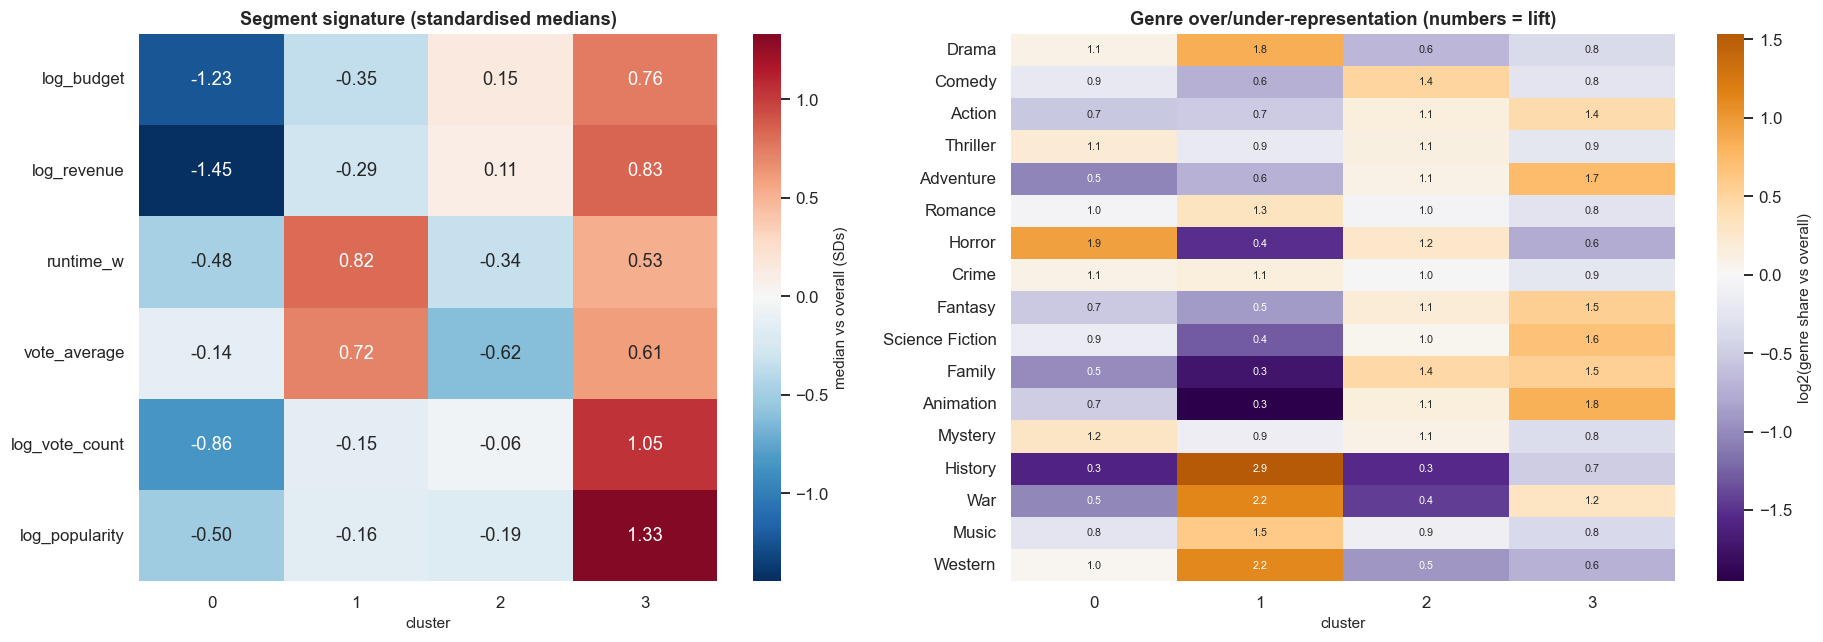

In [75]:
cl['is_major'] = cl.has_major
prof = cl.groupby('cluster').agg(
    n=('id', 'size'), median_budget=('budget', 'median'), median_revenue=('revenue', 'median'), median_runtime=('runtime', 'median'),
    median_rating=('vote_average', 'median'), median_votes=('vote_count', 'median'), median_popularity=('popularity', 'median'),
    hit_rate=('hit', 'mean'), median_roi=('roi', 'median'), pct_english=('is_english', 'mean'), pct_major=('has_major', 'mean'), median_year=('year', 'median'))
prof['share'] = prof.n / prof.n.sum()
display(prof.style.format({'median_budget': '${:,.0f}', 'median_revenue': '${:,.0f}', 'median_votes': '{:,.0f}', 'hit_rate': '{:.0%}', 'pct_english': '{:.0%}', 'pct_major': '{:.0%}', 'share': '{:.0%}',
                           'median_rating': '{:.2f}', 'median_roi': '{:.2f}', 'median_runtime': '{:.0f}', 'median_popularity': '{:.1f}', 'median_year': '{:.0f}'}))
zmed = cl.groupby('cluster')[CL_USE].median().sub(cl[CL_USE].median()).div(cl[CL_USE].std())
gl = pd.DataFrame({g: cl.groupby('cluster')[GENRE_COLS[g]].mean() / cl[GENRE_COLS[g]].mean() for g in GENRES_OK}).T
fig, ax = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={'width_ratios': [1, 1.15]})
sns.heatmap(zmed.T, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax[0], cbar_kws={'label': 'median vs overall (SDs)'}); ax[0].set_title('Segment signature (standardised medians)'); ax[0].set_xlabel('cluster')
sns.heatmap(np.log2(gl), annot=gl.round(1), fmt='', cmap='PuOr_r', center=0, ax=ax[1], annot_kws={'size': 7}, cbar_kws={'label': 'log2(genre share vs overall)'}); ax[1].set_title('Genre over/under-representation (numbers = lift)'); ax[1].set_xlabel('cluster')
plt.tight_layout(); savefig('48_cluster_profiles'); plt.show()

### 11.4 Naming the segments
Names are my interpretation of the profile table (they assume the run is reproduced with the same seed; ids are ordered by median revenue).

| Segment | Profile |
|---|---|
| **C0 - Small & niche** | ~$4M budgets, revenue about equal to budget, lowest hit rate (38%), few major studios (23%) |
| **C1 - Acclaimed mid-budget** | ~$15M budgets, **highest ratings (7.3)** and longest runtimes, strong ROI (2.7x) despite modest reach |
| **C2 - Mainstream commercial** | ~$31M budgets, mixed ratings (6.2), 68% studio-backed, 96% English; the large "middle of the market" |
| **C3 - Blockbusters** | ~$75M budgets, ~$270M median revenue, 83% hit rate, huge audience (7,000 median votes) |

**Honest caveat on cluster quality.** Silhouette is only ~0.20 and agreement with Ward / Gaussian-mixture solutions is moderate (ARI 0.3-0.4), whereas bootstrap stability of K-Means itself is high (ARI 0.91). Translation: films sit on a **continuum**, not in cleanly separated islands. The segments are useful descriptive buckets, not natural categories.

In [76]:
CLUSTER_NAMES = {0: 'Small & niche', 1: 'Acclaimed mid-budget', 2: 'Mainstream commercial', 3: 'Blockbusters'}
if K == 4:
    cl['segment'] = cl.cluster.map(CLUSTER_NAMES)
    print(cl.groupby('segment').agg(n=('id', 'size'), hit_rate=('hit', 'mean'), median_roi=('roi', 'median')).loc[list(CLUSTER_NAMES.values())].round(2))

                          n  hit_rate  median_roi
segment                                          
Small & niche           806     0.380       1.200
Acclaimed mid-budget   1028     0.600       2.670
Mainstream commercial  1697     0.560       2.240
Blockbusters           1048     0.830       3.970


Cluster 0 (806 films) - highest-grossing examples: The Blair Witch Project, Paranormal Activity, Love Story, HAIKYU!! The Dumpster Battle, Fist of Fury, Mad Max
Cluster 1 (1,028 films) - highest-grossing examples: The Wandering Earth II, Operation Red Sea, Dunki, The Eight Hundred, The Bodyguard, Gone with the Wind
Cluster 2 (1,697 films) - highest-grossing examples: The Secret Life of Pets, Wolf Warrior 2, The Smurfs, The Mermaid, The Boss Baby, Meet the Fockers
Cluster 3 (1,048 films) - highest-grossing examples: Avatar, Avengers: Endgame, Avatar: The Way of Water, Titanic, Ne Zha 2, Star Wars: The Force Awakens


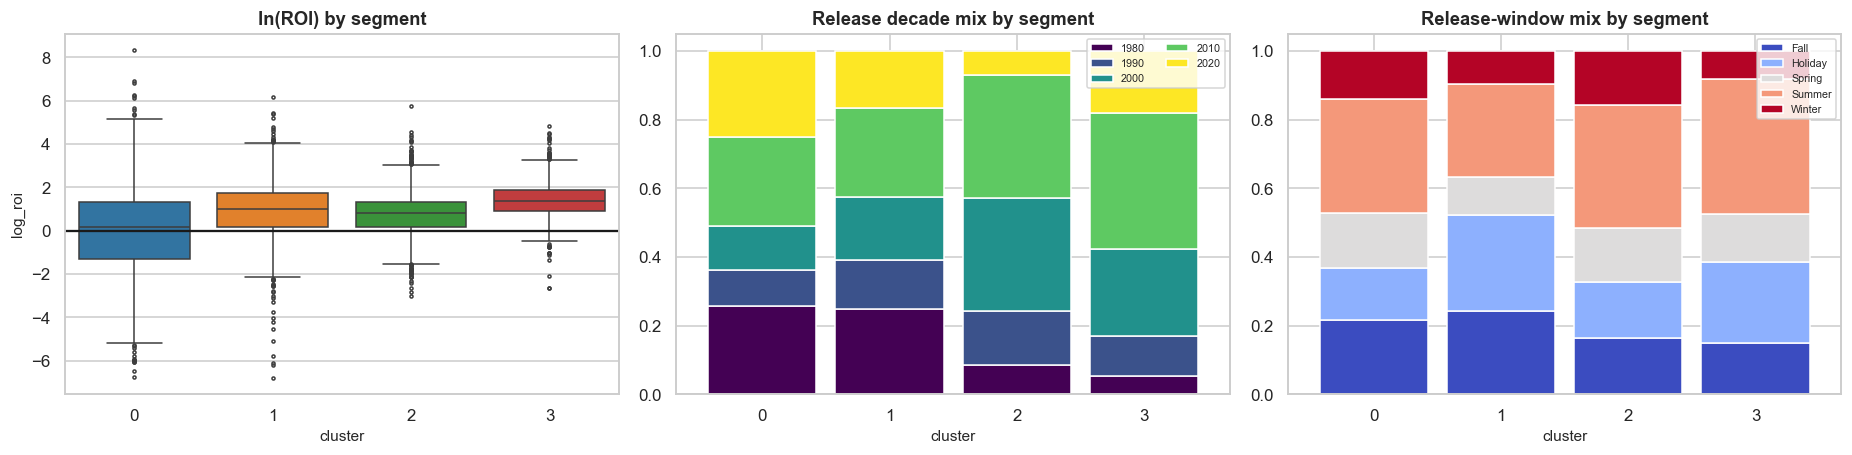

Kruskal-Wallis on ln(ROI) across segments: H=441.9, p=1.8e-95, epsilon^2=0.097


In [77]:
for c in range(K):
    ex = cl[cl.cluster == c].nlargest(6, 'revenue').title.tolist()
    print(f'Cluster {c} ({(cl.cluster == c).sum():,} films) - highest-grossing examples: {", ".join(ex)}')
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
sns.boxplot(data=cl, x='cluster', y='log_roi', ax=ax[0], palette='tab10', fliersize=2); ax[0].axhline(0, c='k'); ax[0].set_title('ln(ROI) by segment')
dm = pd.crosstab(cl.cluster, cl.decade.clip(lower=1980), normalize='index'); dm.plot.bar(stacked=True, ax=ax[1], colormap='viridis', width=.85); ax[1].set_title('Release decade mix by segment'); ax[1].legend(fontsize=7, ncol=2); ax[1].set_xlabel('cluster'); ax[1].tick_params(axis='x', rotation=0)
sn = pd.crosstab(cl.cluster, cl.season_short, normalize='index'); sn.plot.bar(stacked=True, ax=ax[2], colormap='coolwarm', width=.85); ax[2].set_title('Release-window mix by segment'); ax[2].legend(fontsize=7); ax[2].set_xlabel('cluster'); ax[2].tick_params(axis='x', rotation=0)
plt.tight_layout(); savefig('49_cluster_roi_mix'); plt.show()
# do segments differ in ROI beyond chance?
H, p_ = stats.kruskal(*[cl.loc[cl.cluster == c, 'log_roi'] for c in range(K)])
print(f'Kruskal-Wallis on ln(ROI) across segments: H={H:.1f}, p={p_:.1e}, epsilon^2={epsilon_sq(H, len(cl)):.3f}')

## 12. Over- and Under-performers: Which Films Beat Expectations?
A model of *expected* revenue gives a baseline; the **residual** (actual vs expected) isolates what budget, genre, timing, studio and talent do **not** explain - execution, marketing, cultural resonance, or luck. To avoid a film being scored by a model that saw it during training, expectations come from **out-of-fold** predictions (each film is predicted by a model trained on the other folds).

Out-of-fold R2 = 0.537;  within 2x = 51.4%

Biggest OVER-performers (actual / expected):


,title,year,budget,expected_rev,revenue,beat_by
0,Demon Slayer -Kimetsu no Yaiba- The Movie: Mug...,2020,$16M,$9M,$507M,56.4x
1,The Last Kumite,2024,$1M,$1M,$65M,52.1x
2,Crocodile Dundee,1986,$5M,$7M,$328M,45.0x
3,Sound of Freedom,2023,$14M,$8M,$251M,32.5x
4,Les Misérables,2019,$2M,$2M,$55M,31.8x
5,M3GAN,2022,$12M,$6M,$182M,29.9x
6,My Big Fat Greek Wedding,2002,$5M,$14M,$369M,25.6x
7,Insidious,2011,$2M,$4M,$100M,25.0x
8,Rocky,1976,$1M,$9M,$225M,24.3x
9,Unfriended,2014,$1M,$3M,$63M,22.2x


Biggest UNDER-performers:


,title,year,budget,expected_rev,revenue,beat_by
0,Trick 'r Treat,2007,$12M,$47M,$28K,0.0x
1,Falcon Rising,2014,$4M,$15M,$12K,0.0x
2,Barefoot,2014,$6M,$13M,$15K,0.0x
3,Girl Play,2004,$1M,$8M,$12K,0.0x
4,Hunt,2022,$17M,$15M,$26K,0.0x
5,Maestro,2023,$80M,$160M,$300K,0.0x
6,Project Wolf Hunting,2022,$9M,$9M,$21K,0.0x
7,Hacker,2016,$2M,$5M,$11K,0.0x
8,Space Sweepers,2021,$21M,$10M,$25K,0.0x
9,Samba,2014,$20M,$57M,$152K,0.0x


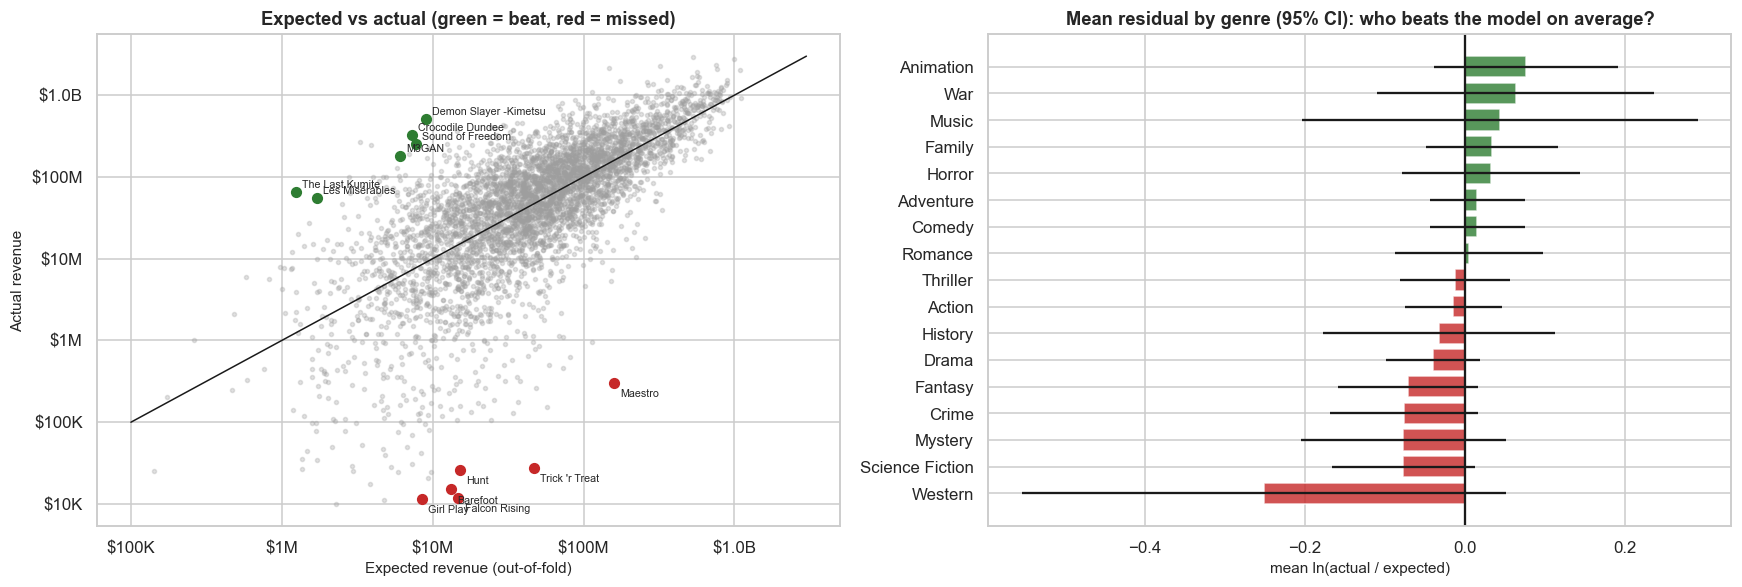

In [78]:
from sklearn.base import clone
oof_pred = cross_val_predict(clone(best_reg), ml[ALL_F], ml.log_revenue.values, cv=kf)
ml['expected_rev'] = np.exp(oof_pred); ml['beat_by'] = ml.revenue / ml.expected_rev; ml['resid_ln'] = ml.log_revenue - oof_pred
print(f'Out-of-fold R2 = {r2_score(ml.log_revenue, oof_pred):.3f};  within 2x = {np.mean(np.abs(ml.resid_ln) < np.log(2)):.1%}')
cols = ['title', 'year', 'budget', 'expected_rev', 'revenue', 'beat_by']
fmt = lambda d: d[cols].assign(budget=d.budget.map(money), expected_rev=d.expected_rev.map(money), revenue=d.revenue.map(money), beat_by=d.beat_by.map('{:.1f}x'.format)).reset_index(drop=True)
print('\nBiggest OVER-performers (actual / expected):'); display(fmt(ml[ml.budget >= 1e6].nlargest(10, 'beat_by')))
print('Biggest UNDER-performers:'); display(fmt(ml[ml.budget >= 1e6].nsmallest(10, 'beat_by')))
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
ax[0].scatter(ml.expected_rev, ml.revenue, s=7, alpha=.3, c='#9E9E9E'); lim = [1e5, 3e9]; ax[0].plot(lim, lim, 'k-', lw=1)
for _, r in ml[ml.budget >= 1e6].nlargest(6, 'beat_by').iterrows(): ax[0].scatter(r.expected_rev, r.revenue, c='#2E7D32', s=40); ax[0].annotate(r.title[:22], (r.expected_rev, r.revenue), fontsize=7, xytext=(4, 3), textcoords='offset points')
for _, r in ml[ml.budget >= 1e6].nsmallest(6, 'beat_by').iterrows(): ax[0].scatter(r.expected_rev, r.revenue, c='#C62828', s=40); ax[0].annotate(r.title[:22], (r.expected_rev, r.revenue), fontsize=7, xytext=(4, -9), textcoords='offset points')
ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].xaxis.set_major_formatter(MONEY); ax[0].yaxis.set_major_formatter(MONEY); ax[0].set_xlabel('Expected revenue (out-of-fold)'); ax[0].set_ylabel('Actual revenue'); ax[0].set_title('Expected vs actual (green = beat, red = missed)')
gr = ml.explode('genres').groupby('genres').resid_ln.agg(['mean', 'size', 'sem']).query('size >= 30').sort_values('mean')
ax[1].barh(gr.index, gr['mean'], xerr=1.96 * gr['sem'], color=np.where(gr['mean'] > 0, '#2E7D32', '#C62828'), alpha=.8); ax[1].axvline(0, c='k')
ax[1].set_title('Mean residual by genre (95% CI): who beats the model on average?'); ax[1].set_xlabel('mean ln(actual / expected)')
plt.tight_layout(); savefig('50_over_under_performers'); plt.show()

## 13. Conclusions

### 13.1 Hypothesis scorecard
| | Hypothesis | Verdict | Evidence |
|---|---|---|---|
| H1 | Budget is the strongest revenue predictor (sub-linear) | **Supported** | Elasticity ~0.73 (95% CI 0.68-0.78): a 10% larger budget goes with ~7% more revenue, i.e. diminishing returns. Top feature in permutation importance / SHAP. |
| H2 | ROI variability falls with budget | **Supported** | Brown-Forsythe test rejects equal variance; Spearman(budget, ROI dispersion) = -0.29. Micro/low-budget films have the widest ROI spread. |
| H3 | Summer / holiday windows outperform | **Partly** | Window differences exist but are small (epsilon^2 ~0.03 on revenue, ~0.01 on ROI). The naive summer hit-rate lift (+6.4 pp) roughly **halves after adjustment** (PSM +3.0 pp, CI -0.5 to +6.5; logit +4.5 pp) while the revenue lift shrinks from +40% to ~+14%. A modest real effect on revenue; weak evidence on hit rate. |
| H4 | English-language films earn more | **Revenue yes, ROI no** | Large revenue gap (Cohen d = 0.66) but **no ROI difference** (diff -0.03 ln, p = 0.75). English films are simply made with bigger budgets for bigger markets. |
| H5 | Genre matters, fewer survive correction | **Supported, with nuance** | 27 of 34 genre tests significant uncorrected; 22 survive Bonferroni, 23 Holm. The correction mainly removes borderline ROI results (Horror, Animation, Mystery). Effects are small (|Cliff's delta| <= 0.16 for ROI) but larger for ratings (Drama +, Horror -, Animation +). |
| H6 | Rating correlates with revenue, weakly vs budget | **Supported** | Positive but clearly weaker than budget: partial r(rating, ln revenue) = 0.23 holding budget and year fixed, versus r = 0.60-0.66 for budget after controls (Section 6.4). |
| H7 | Major studios raise hit probability after matching | **Strongly supported** | Naive +13.6 pp, adjusted **+16 pp** (PSM and logit agree); matched revenue multiple ~1.8x. Survives Holm correction across the three experiments. |
| H8 | Co-productions are rated higher | **Not supported** | Co-productions rate slightly *lower* (-0.05 points, d = -0.08); not significant after Holm (p = 0.09). Practically negligible. |

### 13.2 Key findings
1. **Money in, money out - but with diminishing returns.** Budget explains much of revenue, with elasticity below 1. Spending more raises revenue less than proportionally, and ROI dispersion narrows: large budgets buy *predictability*, not outsized multiples.
2. **Scale is not skill.** English-language and studio-backed films earn more mainly because they spend more. English films' *ROI* is no different. Studio backing is the exception: it keeps a large advantage (+16 pp hit probability) even against matched films of similar budget, genre, year and market.
3. **Naive A/B reads overstate release-window effects.** Summer films are bigger-budget, studio-backed tentpoles. Matching cut the apparent hit-rate lift by about half. This is the main methodological lesson of the project: *compare like with like before crediting a tactic*.
4. **Multiple testing matters, but sample size cuts the other way.** With ~4,500 films nearly everything is "significant". The useful discipline was reporting effect sizes alongside corrected p-values: most genre effects are statistically real yet small.
5. **Pre-release prediction is hard, and the models are honest about it.** On genuinely future films (2018-07 onward) the best revenue model reaches R^2 ~ 0.37 and lands within a factor of 2 of actual revenue for ~44% of films, versus 29% for the naive baseline. Cross-validated R^2 on the training period is ~0.54, and the gap is **temporal drift**, not a bug.
6. **Hit/flop classification is only modestly better than chance** (test ROC-AUC 0.66-0.68; best F1 trade-offs are close to "predict everything is a hit"). Ranking is more useful than classification: the top-scored decile hit 67% of the time versus 15% for the bottom decile.
7. **Leakage is seductive.** Adding vote count / popularity lifts test R^2 from 0.37 to 0.54, which would look like a breakthrough but is unusable because those signals do not exist before release.
8. **Four loosely separated market segments** (small & niche, acclaimed mid-budget, mainstream commercial, blockbusters) with very different economics: hit rates of 38% / 60% / 56% / 83%, and the acclaimed mid-budget group posting the second-best median ROI (2.7x).

### 13.3 Recommendations (what I would tell a studio or financier)
* **Judge tactics on adjusted, not raw, comparisons.** Do not credit "summer release" or "star genre" with the whole difference; the matched effect is about half.
* **Treat budget as a risk dial.** Small budgets: high variance, portfolio logic needed. Large budgets: lower relative variance, but returns do not scale linearly.
* **Value distribution/studio partnerships explicitly.** Studio backing carries an adjusted advantage that other features do not explain.
* **Use the model for ranking and ranges, not point forecasts.** Quote the interval width (typically over 10x between the low and high ends) when presenting a forecast.
* **Look at the over-performer list** (Section 12) for patterns the model misses: low-budget horror and faith-based/event releases, international animation, and sleeper hits were all multiples above expectation.

### 13.4 Limitations (read before citing any number)
* **Selection bias.** Only ~47% of films have usable budget and revenue; they skew English/US/commercial. Results describe films with disclosed financials.
* **Nominal dollars.** No inflation adjustment; `year` is controlled for, but long-run dollar comparisons are rough. Revenue may also be incomplete for recent releases and streaming-original films (flagged and controlled, not removed).
* **Observational data.** Propensity matching only adjusts for *measured* covariates. Marketing spend, star power beyond prior-film averages, and distribution breadth are unobserved, so A/B effects are associations, not proven causes.
* **Temporal drift.** The hit rate falls from 64% (train) to 45% (test). Models trained on older films overstate recent performance, and the 80% prediction interval covered only ~65% of test films. A recalibration step (e.g. conformal prediction on recent data) is needed before real use.
* **Data quality.** Some revenue figures appear partial (e.g. very small revenue for films with sizeable budgets); I removed values under $10,000 but cannot verify the rest. Cast is limited to five names, and the `director`/`lead` track-record features cover only repeat names in this dataset.
* **Cluster quality.** Silhouette ~0.20: segments are descriptive buckets on a continuum.
* **Model tuning gains were negligible.** Ridge, random forest and XGBoost perform almost identically on the test set; extra complexity does not buy accuracy here.

### 13.5 Next steps
1. Add inflation (CPI) adjustment and marketing spend, if available.
2. Time-aware conformal intervals and rolling-origin validation.
3. Text features (overview/keywords) and richer talent features (network centrality, franchise flag).
4. Streamlit dashboard for scenario testing (budget x genre x month).
5. Causal methods for studio and release-window effects (doubly-robust estimators, sensitivity analysis for hidden confounding).

---
### Appendix: reproducibility